target_csemCur = 5000252545
P0_true = 335363.5650097035 Pa
alpha_true = 64.85958289678 Pa/day
tf = 236.87424931723152 days
number of sampling instants = 238
x_max_zoom = 50


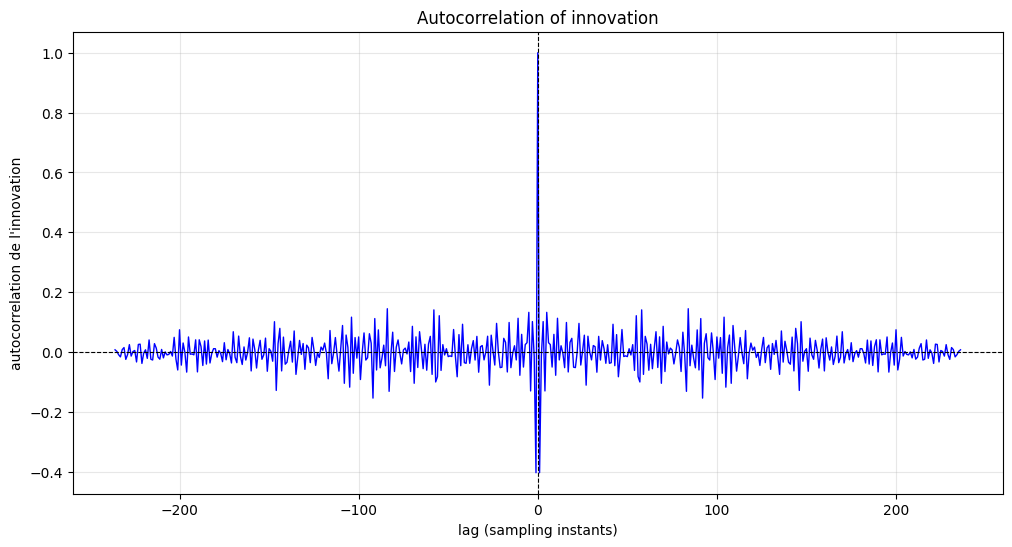

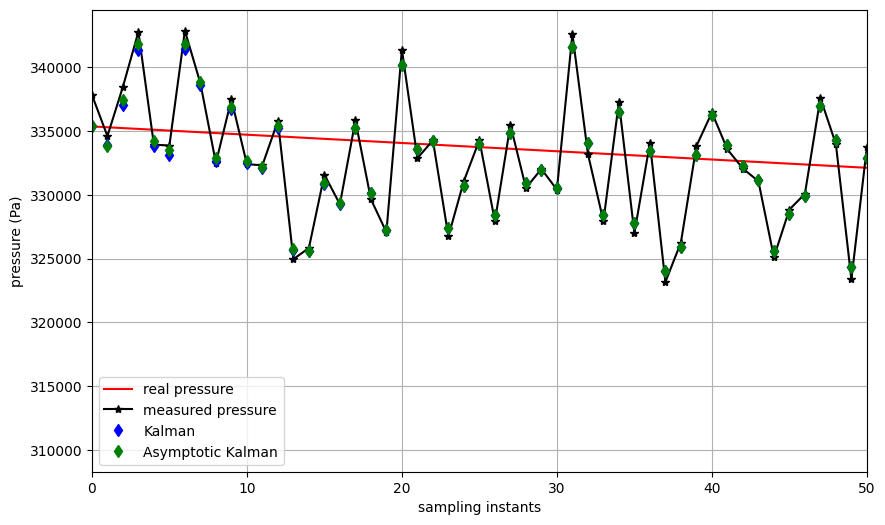

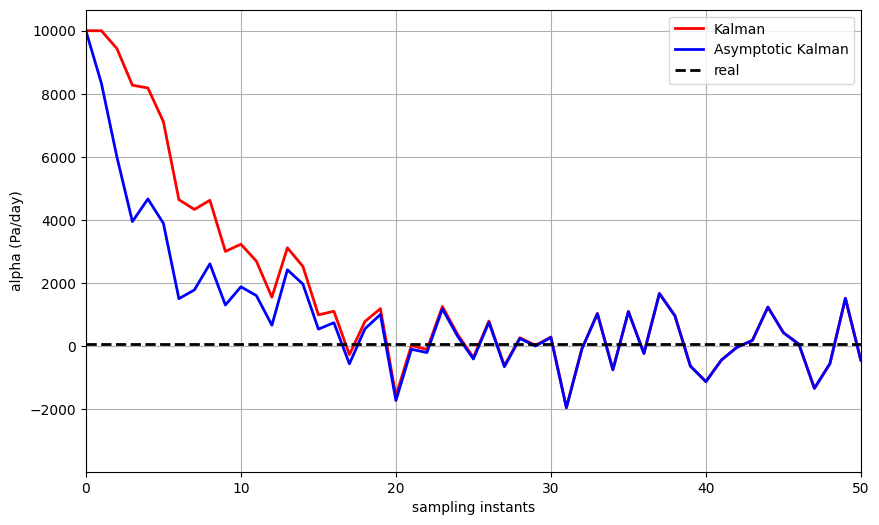

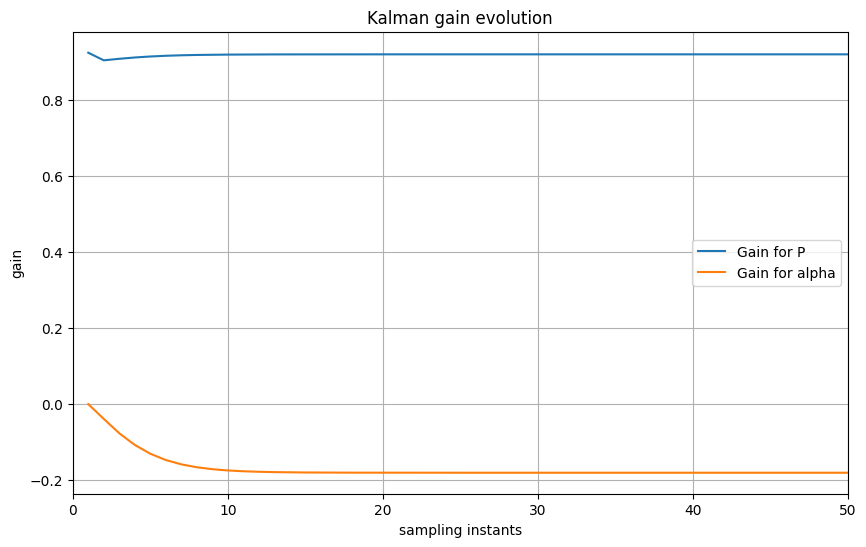

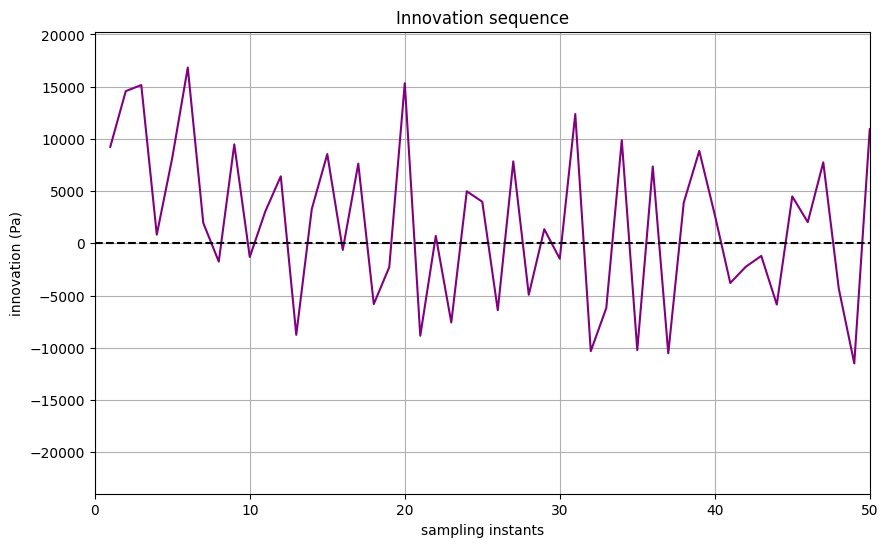

In [ ]:
# add autocorrelation figure
# x-axis changed to sampling instants instead of time (days)
# change pressure unit from bar to Pa
# alpha unit: Pa/day

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# =========================
# 0. 基本设置
# =========================
plt.close('all')
np.random.seed(42)

# 压力单位转换：
# 1 bar = 100000 Pa
BAR_TO_PA = 1e5
BAR2_TO_PA2 = BAR_TO_PA ** 2


# =========================
# 1. 读取真实系统初始值
# =========================
df = pd.read_csv(
    "/Users/wenbo.wu/Documents/Documents - Wenbo WU/Thesis/RTE_use_case/RTE_dashboard/RTE/new_df_AlphaCorrected.csv",
    encoding="utf-8-sig"
)


# target_csemCur = 5002343705
target_csemCur = 5000252545
# target_csemCur = 5000252447


df_csem = df[df['csemCur'] == target_csemCur].copy()


if df_csem.empty:
    raise ValueError(
        f"在 new_df_AlphaCorrected 中没有找到 csemCur = {target_csemCur} 的数据"
    )


row0 = df_csem.iloc[0]


# CSV 中的原始单位：
# compensatedRelativePressure_mafiltered: bar
# alpha: bar/day
P0_true_bar = float(row0['compensatedRelativePressure_mafiltered'])
alpha_true_bar_per_day = float(row0['alpha'])

# 转换为 Pa 和 Pa/day
P0_true = P0_true_bar * BAR_TO_PA
alpha_true = alpha_true_bar_per_day * BAR_TO_PA


# =========================
# 2. 真实系统线性变化
# =========================
Te = 1  # sampling time (days)

# 目标终止压力：原来为 3.2 bar，现在转换为 Pa
P_final = 3.2 * BAR_TO_PA


if alpha_true <= 0:
    raise ValueError(
        f"alpha_true 必须大于 0，当前读取到的是 "
        f"{alpha_true} Pa/day"
    )


tf = (P0_true - P_final) / alpha_true


if tf <= 0:
    raise ValueError(
        f"计算得到 tf <= 0，请检查 "
        f"P0_true={P0_true} Pa, "
        f"P_final={P_final} Pa, "
        f"alpha_true={alpha_true} Pa/day"
    )


temps = np.arange(0, tf + Te, Te)
sampling_instants = np.arange(len(temps))


# 真实压力，单位 Pa
P_true = P0_true - temps * alpha_true


# =========================
# 3. 测量噪声
# =========================
# 原始测量噪声：0.05 bar
sigma_meas_bar = 0.05

# 转换为 Pa
sigma_meas = sigma_meas_bar * BAR_TO_PA

# 测量压力，单位 Pa
P_measured = P_true + sigma_meas * np.random.randn(len(P_true))


# =========================
# 4. 压力图
# =========================
plt.figure(1, figsize=(10, 6))
plt.plot(
    sampling_instants,
    P_true,
    'r',
    label='real pressure'
)
plt.plot(
    sampling_instants,
    P_measured,
    '*-k',
    label='measured pressure'
)


# =========================
# 5. Kalman filtering
# =========================
# 原始 Q 中：
# 0.02 的单位对应压力状态 P 的方差，单位 bar^2
# 1e-3 的单位对应 alpha 状态的方差，单位 (bar/day)^2
#
# 转换到 Pa 后，方差需要乘以 (1e5)^2
Q_bar = Te * np.diag([0.02, 1e-3])
Q = Q_bar * BAR2_TO_PA2 



# R 是测量噪声方差，单位从 bar^2 转换为 Pa^2
R = sigma_meas ** 2


# 初始协方差：
# 第一个状态为压力 P
# 第二个状态为压力变化率 alpha
Sigma_priori_init_bar = np.diag([0.01, 1e-6])
Sigma_priori_init = Sigma_priori_init_bar * BAR2_TO_PA2


# alpha 初值：原来为 0.1 bar/day
alpha0_bar_per_day = 0.1
alpha0 = alpha0_bar_per_day * BAR_TO_PA


P0 = P0_true


x0 = np.array([
    [P0],
    [alpha0]
])


Kalman_states = x0.copy()
x_priori = x0.copy()
Sigma_posteriori = Sigma_priori_init.copy()
x_posteriori = x0.copy()

# 观测压力 P
H = np.array([[1, 0]])

Kalman_gain = np.empty((2, 0))


# 保存 innovation，单位 Pa
innovations = []


for k in range(len(temps) - 1):

    A = np.array([
        [1, -Te],
        [0,  1]
    ])


    x_priori = A @ x_posteriori

    Sigma_priori = (
        A @ Sigma_posteriori @ A.T + Q
    )


    K = (
        Sigma_priori
        @ H.T
        @ np.linalg.inv(
            np.array([[R]]) + H @ Sigma_priori @ H.T
        )
    )


    Sigma_posteriori = (
        np.eye(2) - K @ H
    ) @ Sigma_priori


    innovation = (
        np.array([[P_measured[k + 1]]])
        - H @ x_priori
    )

    innovations.append(float(innovation.item()))


    x_posteriori = x_priori + K @ innovation


    Kalman_states = np.hstack(
        (Kalman_states, x_posteriori)
    )

    Kalman_gain = np.hstack(
        (Kalman_gain, K)
    )


innovations = np.array(innovations)


P_Kalman = Kalman_states[0, :]
alpha_Kalman = Kalman_states[1, :]


plt.figure(1)
plt.plot(
    sampling_instants,
    P_Kalman,
    'bd',
    label='Kalman'
)3


# =========================
# 6. Asymptotic Kalman filter
# =========================
alpha0_2_bar_per_day = 0.1
alpha0_2 = alpha0_2_bar_per_day * BAR_TO_PA

P0_2 = P0_true


x0 = np.array([
    [P0_2],
    [alpha0_2]
])


Kalman_states2 = x0.copy()
x_priori = x0.copy()
Sigma_posteriori = Sigma_priori_init.copy()
x_posteriori = x0.copy()

H = np.array([[1, 0]])


K = Kalman_gain[:, -1].reshape(2, 1)


for k in range(len(temps) - 1):

    A = np.array([
        [1, -Te],
        [0,  1]
    ])


    x_priori = A @ x_posteriori

    Sigma_priori = (
        A @ Sigma_posteriori @ A.T + Q
    )


    Sigma_posteriori = (
        np.eye(2) - K @ H
    ) @ Sigma_priori


    innovation = (
        np.array([[P_measured[k + 1]]])
        - H @ x_priori
    )


    x_posteriori = x_priori + K @ innovation


    Kalman_states2 = np.hstack(
        (Kalman_states2, x_posteriori)
    )


P_Kalman2 = Kalman_states2[0, :]
alpha_Kalman2 = Kalman_states2[1, :]


plt.figure(1)
plt.plot(
    sampling_instants,
    P_Kalman2,
    'gd',
    label='Asymptotic Kalman'
)

plt.xlabel('sampling instants')
plt.ylabel('pressure (Pa)')
plt.grid(True)
plt.legend()


# =========================
# 7. alpha 图
# =========================
plt.figure(2, figsize=(10, 6))

plt.plot(
    sampling_instants,
    alpha_Kalman,
    'r',
    linewidth=2,
    label='Kalman'
)

plt.plot(
    sampling_instants,
    alpha_Kalman2,
    'b',
    linewidth=2,
    label='Asymptotic Kalman'
)

plt.plot(
    sampling_instants,
    alpha_true * np.ones_like(sampling_instants),
    'k--',
    linewidth=2,
    label='real'
)

plt.grid(True)
plt.xlabel('sampling instants')
plt.ylabel('alpha (Pa/day)')
plt.legend()


# =========================
# 8. Kalman gain 图
# =========================
sampling_instants_gain = np.arange(1, len(temps))


plt.figure(3, figsize=(10, 6))

plt.plot(
    sampling_instants_gain,
    Kalman_gain[0, :],
    label='Gain for P'
)

plt.plot(
    sampling_instants_gain,
    Kalman_gain[1, :],
    label='Gain for alpha'
)

plt.title('Kalman gain evolution')
plt.xlabel('sampling instants')
plt.ylabel('gain')
plt.grid(True)
plt.legend()


# =========================
# 9. Innovation 序列
# =========================
sampling_instants_innov = np.arange(1, len(temps))


plt.figure(4, figsize=(10, 6))

plt.plot(
    sampling_instants_innov,
    innovations,
    color='purple',
    linewidth=1.5
)

plt.axhline(
    0,
    color='black',
    linestyle='--'
)

plt.title('Innovation sequence')
plt.xlabel('sampling instants')
plt.ylabel('innovation (Pa)')
plt.grid(True)


# =========================
# 10. Innovation 对称自相关图
# =========================
x = np.asarray(innovations, dtype=float)
x = x - np.mean(x)


acf_full = np.correlate(
    x,
    x,
    mode='full'
)

acf_full = (
    acf_full / acf_full[len(x) - 1]
)


lags = np.arange(
    -(len(x) - 1),
    len(x)
)


max_lag = min(
    2000,
    len(x) - 1
)

mask = (
    (lags >= -max_lag)
    & (lags <= max_lag)
)


plt.figure(5, figsize=(12, 6))

plt.plot(
    lags[mask],
    acf_full[mask],
    color='blue',
    linewidth=1
)

plt.axhline(
    0,
    color='black',
    linestyle='--',
    linewidth=0.8
)

plt.axvline(
    0,
    color='black',
    linestyle='--',
    linewidth=0.8
)

plt.xlabel('lag (sampling instants)')
plt.ylabel("autocorrelation de l'innovation")
plt.title('Autocorrelation of innovation')
plt.grid(True, alpha=0.3)


# =========================
# 11. 放大 x 轴前段
# =========================
x_max_zoom = min(
    50,
    len(sampling_instants) - 1
)


plt.figure(1)
plt.xlim(0, x_max_zoom)

plt.figure(2)
plt.xlim(0, x_max_zoom)

plt.figure(3)
plt.xlim(0, x_max_zoom)

plt.figure(4)
plt.xlim(0, x_max_zoom)


# =========================
# 12. 打印关键信息
# =========================
print("target_csemCur =", target_csemCur)
print("P0_true =", P0_true, "Pa")
print("alpha_true =", alpha_true, "Pa/day")
print("tf =", tf, "days")
print("number of sampling instants =", len(sampling_instants))
print("x_max_zoom =", x_max_zoom)


plt.show()


========== Q tuning results ==========
 q_scale  pressure_rmse_Pa  pressure_mae_Pa  innovation_rmse_Pa
0.562000       2886.392453      2196.501515         6717.135812
0.630574       2887.185972      2209.397321         6710.814419
0.500883       2892.575324      2186.021994         6727.542468
0.707516       2894.301432      2223.509815         6708.399926
0.446412       2906.382032      2177.545140         6742.232387
0.793846       2907.090732      2238.815548         6709.733541
0.890710       2924.923999      2256.813609         6714.675679
0.397866       2928.438936      2170.963500         6761.423020
0.999393       2947.199560      2278.474887         6723.105238
0.354598       2959.337336      2167.562868         6785.350905

========== Selected parameters ==========
best_q_scale = 5.620000e-01
best_pressure_RMSE = 2886.392453 Pa

========== Noise parameters ==========
sigma_meas = 5000.000000 Pa
R = 2.500000e+07 Pa^2

Q_base =
[[1000000.       0.]
 [      0. 1000000.]]

Q_sel

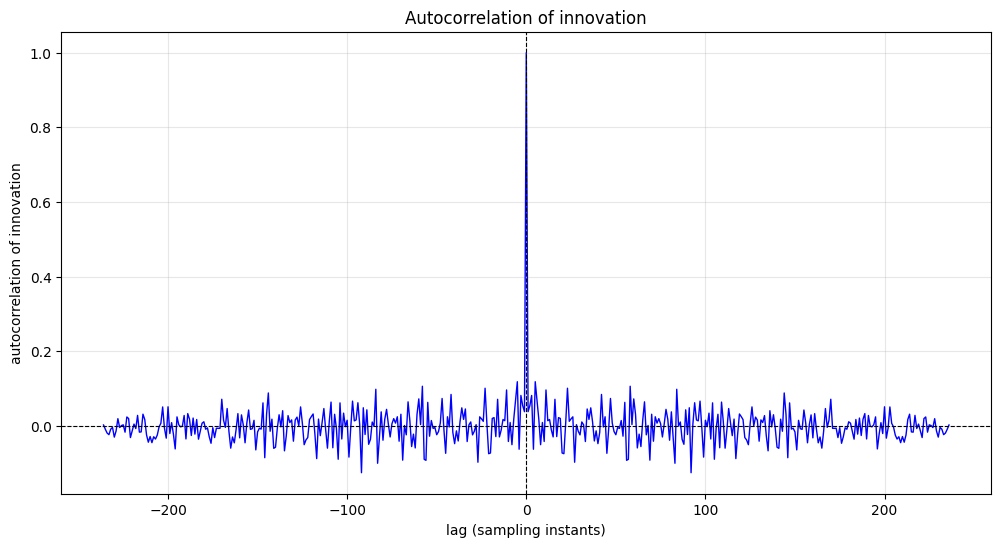

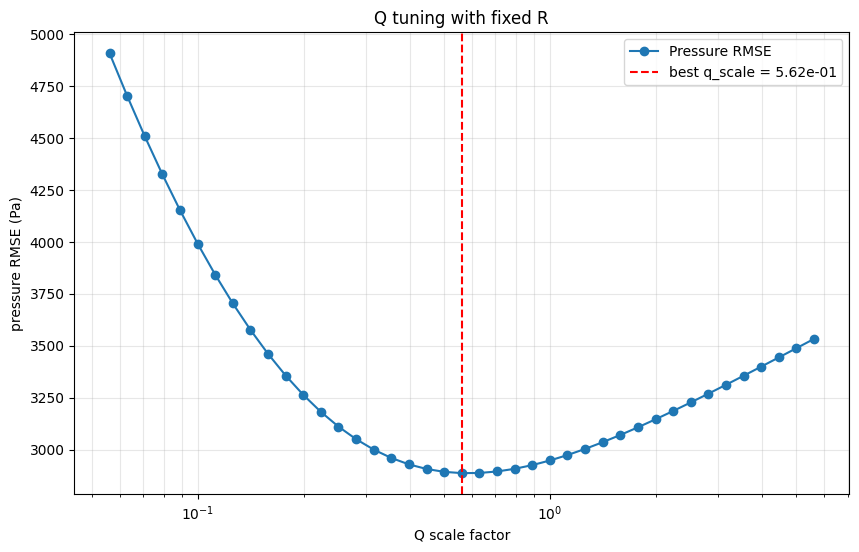

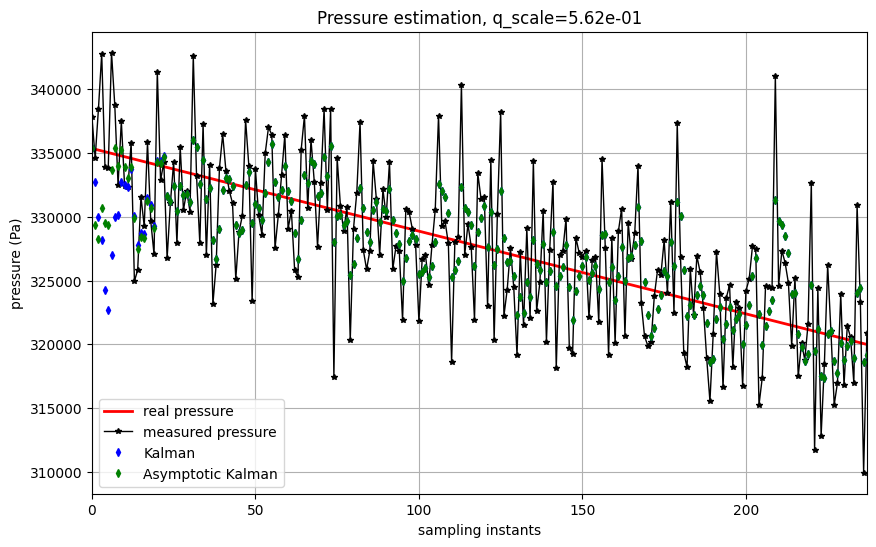

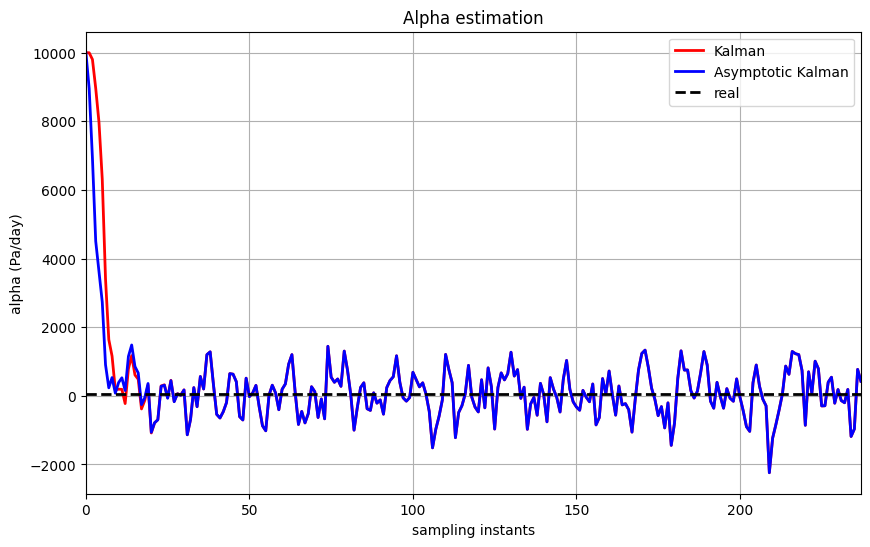

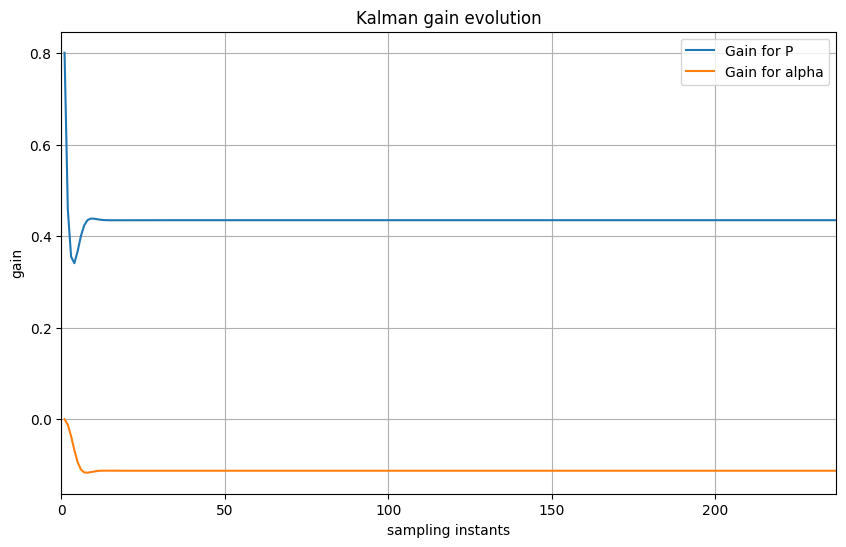

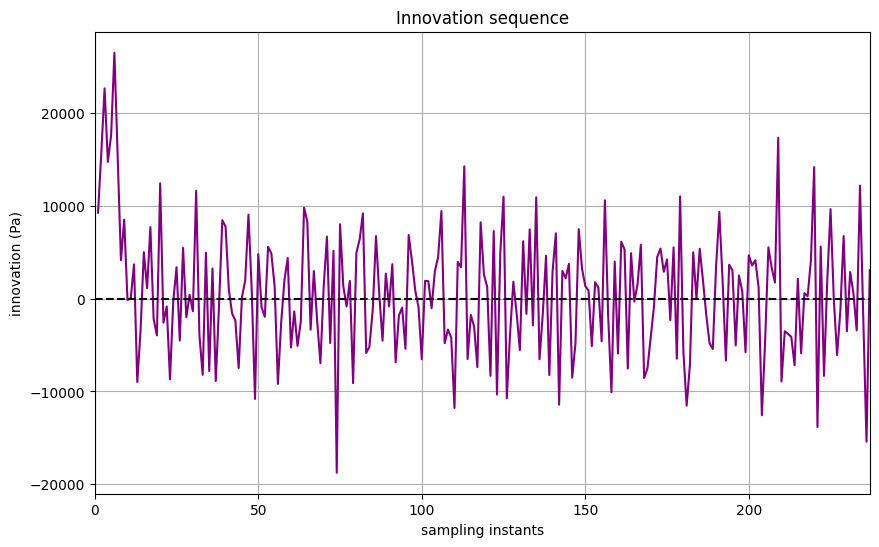

In [ ]:
# ============================================================
# Kalman filtering with pressure unit conversion and Q tuning with RMSE
#
# Pressure unit:
#     Pa
#
# Alpha unit:
#     Pa/day
#
# Original CSV units:
#     pressure: bar
#     alpha:    bar/day
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 0. 基本设置
# ============================================================
plt.close("all")
np.random.seed(42)

# 单位转换
BAR_TO_PA = 1e5
BAR2_TO_PA2 = BAR_TO_PA ** 2


# ============================================================
# 1. 读取真实系统初始值
# ============================================================
df = pd.read_csv(
    "/Users/wenbo.wu/Documents/Documents - Wenbo WU/Thesis/RTE_use_case/RTE_dashboard/RTE/new_df_AlphaCorrected.csv",
    encoding="utf-8-sig"
    )


# target_csemCur = 5002343705
target_csemCur = 5000252545
# target_csemCur = 5000252447


df_csem = df[df["csemCur"] == target_csemCur].copy()


if df_csem.empty:
    raise ValueError(
        f"在 new_df_AlphaCorrected 中没有找到 "
        f"csemCur = {target_csemCur} 的数据"
    )


row0 = df_csem.iloc[0]


# CSV 中的原始单位：
# compensatedRelativePressure_mafiltered: bar
# alpha: bar/day
P0_true_bar = float(
    row0["compensatedRelativePressure_mafiltered"]
)

alpha_true_bar_per_day = float(
    row0["alpha"]
)


# 转换为 Pa 和 Pa/day
P0_true = P0_true_bar * BAR_TO_PA
alpha_true = alpha_true_bar_per_day * BAR_TO_PA


# ============================================================
# 2. 真实系统线性变化
# ============================================================
Te = 1.0  # sampling time, day

# 原始终止压力为 3.2 bar
P_final_bar = 3.2

# 转换为 Pa
P_final = P_final_bar * BAR_TO_PA


if alpha_true <= 0:
    raise ValueError(
        f"alpha_true 必须大于 0，当前值为 "
        f"{alpha_true} Pa/day"
    )


# 计算终止时间
tf = (P0_true - P_final) / alpha_true


if tf <= 0:
    raise ValueError(
        f"计算得到 tf <= 0，请检查：\n"
        f"P0_true = {P0_true} Pa\n"
        f"P_final = {P_final} Pa\n"
        f"alpha_true = {alpha_true} Pa/day"
    )


temps = np.arange(
    0,
    tf + Te,
    Te
)

sampling_instants = np.arange(
    len(temps)
)


# 真实压力，单位 Pa
P_true = P0_true - temps * alpha_true


# ============================================================
# 3. 生成测量数据
# ============================================================
# 测量噪声标准差：
# 原始单位为 0.05 bar
sigma_meas_bar = 0.05

# 转换为 Pa
sigma_meas = sigma_meas_bar * BAR_TO_PA

# 测量压力，单位 Pa
P_measured = (
    P_true
    + sigma_meas * np.random.randn(len(P_true))
)


# ============================================================
# 4. 固定 R
# ============================================================
# R 是测量噪声协方差，单位 Pa^2
#
# sigma_meas = 0.05 bar = 5000 Pa
# R = (5000 Pa)^2 = 2.5e7 Pa^2
R = sigma_meas ** 2


# ============================================================
# 5. 设置初始协方差
# ============================================================
# 原始初始协方差：
# P:     0.01 bar^2
# alpha: 1e-6 (bar/day)^2
#
# 转换到 Pa 后，需要乘以 (1e5)^2
Sigma_priori_init_bar = np.diag([
    0.01,
    1e-6
])

Sigma_priori_init = (
    Sigma_priori_init_bar * BAR2_TO_PA2
)


# 初始 alpha：
# 原始单位为 0.1 bar/day
alpha0_bar_per_day = 0.1
alpha0 = alpha0_bar_per_day * BAR_TO_PA


# ============================================================
# 6. 设置 Q 的基准值
# ============================================================
# 这里不再直接把 0.02 作为最终 Q。
#
# 可以理解为：
# sigma_process_P_bar:
#     每个采样周期压力模型误差的标准差，单位 bar
#
# sigma_process_alpha_bar_per_day:
#     每个采样周期 alpha 模型误差的标准差，单位 bar/day
#
# 例如：
# sigma_process_P_bar = 0.01
# 表示压力模型误差标准差约为 0.01 bar
#
# 原来的 0.02 相当于：
# sqrt(0.02) = 0.1414 bar
# 这个过程噪声可能比较大。
sigma_process_P_bar = 0.01
sigma_process_alpha_bar_per_day = 0.01


# 由标准差计算方差
q_pressure_bar2 = sigma_process_P_bar ** 2

q_alpha_bar2_per_day2 = (
    sigma_process_alpha_bar_per_day ** 2
)


# 在 bar 单位下构造 Q
Q_base_bar = Te * np.diag([
    q_pressure_bar2,
    q_alpha_bar2_per_day2
])


# 转换为 Pa 相关单位
Q_base = Q_base_bar * BAR2_TO_PA2


# ============================================================
# 7. Kalman filter 函数
# ============================================================
def run_kalman_filter(
    P_measured,
    Te,
    Q,
    R,
    Sigma_priori_init,
    P0,
    alpha0
):
    """
    状态：
        x = [P, alpha]^T

    P:
        Pa

    alpha:
        Pa/day

    Q:
        过程噪声协方差

    R:
        测量噪声协方差，单位 Pa^2
    """

    n_samples = len(P_measured)

    # 状态转移矩阵
    A = np.array([
        [1.0, -Te],
        [0.0,  1.0]
    ])

    # 观测矩阵，只观测压力
    H = np.array([
        [1.0, 0.0]
    ])

    # 初始状态
    x0 = np.array([
        [P0],
        [alpha0]
    ], dtype=float)

    # 初始化
    x_posteriori = x0.copy()
    Sigma_posteriori = Sigma_priori_init.copy()

    Kalman_states = x0.copy()
    Kalman_gain = np.empty((2, 0))
    innovations = []

    # Kalman filtering
    for k in range(n_samples - 1):

        # -------------------------
        # Prediction
        # -------------------------
        x_priori = A @ x_posteriori

        Sigma_priori = (
            A
            @ Sigma_posteriori
            @ A.T
            + Q
        )

        # -------------------------
        # Kalman gain
        # -------------------------
        innovation_covariance = (
            np.array([[R]])
            + H @ Sigma_priori @ H.T
        )

        K = (
            Sigma_priori
            @ H.T
            @ np.linalg.inv(innovation_covariance)
        )

        # -------------------------
        # Innovation
        # -------------------------
        innovation = (
            np.array([[P_measured[k + 1]]])
            - H @ x_priori
        )

        innovations.append(
            float(innovation.item())
        )

        # -------------------------
        # Update state
        # -------------------------
        x_posteriori = (
            x_priori
            + K @ innovation
        )

        # -------------------------
        # Joseph form update
        # 数值稳定性通常优于：
        # (I - K @ H) @ Sigma_priori
        # -------------------------
        I = np.eye(2)

        Sigma_posteriori = (
            (I - K @ H)
            @ Sigma_priori
            @ (I - K @ H).T
            + K @ np.array([[R]]) @ K.T
        )

        # 保存结果
        Kalman_states = np.hstack([
            Kalman_states,
            x_posteriori
        ])

        Kalman_gain = np.hstack([
            Kalman_gain,
            K
        ])

    return (
        Kalman_states,
        Kalman_gain,
        np.asarray(innovations)
    )


# ============================================================
# 8. 搜索最佳 Q
# ============================================================
# q_scale 只改变 Q，不改变 R：
#
# Q_candidate = q_scale * Q_base
#
# q_scale 越小：
#     越相信模型
#
# q_scale 越大：
#     越相信测量值
# q_scale_grid = np.logspace(
#     -6,
#     2,
#     33
# )


q_scale_grid = np.logspace(
    np.log10(5.62e-1) - 1,
    np.log10(5.62e-1) + 1,
    41
)

q_search_results = []


for q_scale in q_scale_grid:

    Q_candidate = q_scale * Q_base

    (
        states_candidate,
        gain_candidate,
        innovations_candidate
    ) = run_kalman_filter(
        P_measured=P_measured,
        Te=Te,
        Q=Q_candidate,
        R=R,
        Sigma_priori_init=Sigma_priori_init,
        P0=P0_true,
        alpha0=alpha0
    )

    P_candidate = states_candidate[0, :]

    # 忽略开始阶段的初始化瞬态
    transient = min(
        5,
        max(0, len(P_true) // 10)
    )

    # 压力 RMSE
    pressure_rmse = np.sqrt(
        np.mean(
            (
                P_candidate[transient:]
                - P_true[transient:]
            ) ** 2
        )
    )

    # 压力 MAE
    pressure_mae = np.mean(
        np.abs(
            P_candidate[transient:]
            - P_true[transient:]
        )
    )

    # Innovation RMSE
    innovation_rmse = np.sqrt(
        np.mean(
            innovations_candidate ** 2
        )
    )

    q_search_results.append({
        "q_scale": q_scale,
        "pressure_rmse_Pa": pressure_rmse,
        "pressure_mae_Pa": pressure_mae,
        "innovation_rmse_Pa": innovation_rmse
    })


q_results_df = pd.DataFrame(
    q_search_results
)


# 按压力 RMSE 排序
q_results_sorted = q_results_df.sort_values(
    by="pressure_rmse_Pa",
    ascending=True
).reset_index(drop=True)


# 选择 RMSE 最小的 q_scale
best_q_scale = float(
    q_results_sorted.loc[0, "q_scale"]
)

best_pressure_rmse = float(
    q_results_sorted.loc[0, "pressure_rmse_Pa"]
)


# 最佳 Q
Q = best_q_scale * Q_base


# ============================================================
# 9. 输出 Q 搜索结果
# ============================================================
print("\n========== Q tuning results ==========")

print(
    q_results_sorted.head(10).to_string(
        index=False
    )
)

print("\n========== Selected parameters ==========")
print(f"best_q_scale = {best_q_scale:.6e}")
print(
    f"best_pressure_RMSE = "
    f"{best_pressure_rmse:.6f} Pa"
)

print("\n========== Noise parameters ==========")
print(f"sigma_meas = {sigma_meas:.6f} Pa")
print(f"R = {R:.6e} Pa^2")

print("\nQ_base =")
print(Q_base)

print("\nQ_selected =")
print(Q)


# ============================================================
# 10. 使用最佳 Q 运行正式 Kalman filter
# ============================================================
(
    Kalman_states,
    Kalman_gain,
    innovations
) = run_kalman_filter(
    P_measured=P_measured,
    Te=Te,
    Q=Q,
    R=R,
    Sigma_priori_init=Sigma_priori_init,
    P0=P0_true,
    alpha0=alpha0
)


P_Kalman = Kalman_states[0, :]
alpha_Kalman = Kalman_states[1, :]


# ============================================================
# 11. Asymptotic Kalman filter
# ============================================================
def run_asymptotic_kalman_filter(
    P_measured,
    Te,
    Q,
    R,
    Sigma_priori_init,
    P0,
    alpha0,
    K
):
    """
    使用固定 Kalman gain 的 asymptotic Kalman filter。
    """

    n_samples = len(P_measured)

    A = np.array([
        [1.0, -Te],
        [0.0,  1.0]
    ])

    H = np.array([
        [1.0, 0.0]
    ])

    x_posteriori = np.array([
        [P0],
        [alpha0]
    ], dtype=float)

    Sigma_posteriori = Sigma_priori_init.copy()

    Kalman_states = x_posteriori.copy()

    for k in range(n_samples - 1):

        # Prediction
        x_priori = A @ x_posteriori

        Sigma_priori = (
            A
            @ Sigma_posteriori
            @ A.T
            + Q
        )

        # 使用固定 gain
        Sigma_posteriori = (
            (np.eye(2) - K @ H)
            @ Sigma_priori
            @ (np.eye(2) - K @ H).T
            + K @ np.array([[R]]) @ K.T
        )

        innovation = (
            np.array([[P_measured[k + 1]]])
            - H @ x_priori
        )

        x_posteriori = (
            x_priori
            + K @ innovation
        )

        Kalman_states = np.hstack([
            Kalman_states,
            x_posteriori
        ])

    return Kalman_states


# 使用正式 Kalman filter 最后的 gain
K_asymptotic = Kalman_gain[:, -1].reshape(2, 1)


Kalman_states2 = run_asymptotic_kalman_filter(
    P_measured=P_measured,
    Te=Te,
    Q=Q,
    R=R,
    Sigma_priori_init=Sigma_priori_init,
    P0=P0_true,
    alpha0=alpha0,
    K=K_asymptotic
)


P_Kalman2 = Kalman_states2[0, :]
alpha_Kalman2 = Kalman_states2[1, :]


# ============================================================
# 12. 压力图
# ============================================================
plt.figure(1, figsize=(10, 6))

plt.plot(
    sampling_instants,
    P_true,
    "r",
    linewidth=2,
    label="real pressure"
)

plt.plot(
    sampling_instants,
    P_measured,
    "*-k",
    linewidth=1,
    markersize=4,
    label="measured pressure"
)

plt.plot(
    sampling_instants,
    P_Kalman,
    "bd",
    markersize=4,
    label="Kalman"
)

plt.plot(
    sampling_instants,
    P_Kalman2,
    "gd",
    markersize=4,
    label="Asymptotic Kalman"
)

plt.xlabel("sampling instants")
plt.ylabel("pressure (Pa)")
plt.title(
    f"Pressure estimation, q_scale={best_q_scale:.2e}"
)
plt.grid(True)
plt.legend()


# ============================================================
# 13. Alpha 图
# ============================================================
plt.figure(2, figsize=(10, 6))

plt.plot(
    sampling_instants,
    alpha_Kalman,
    "r",
    linewidth=2,
    label="Kalman"
)

plt.plot(
    sampling_instants,
    alpha_Kalman2,
    "b",
    linewidth=2,
    label="Asymptotic Kalman"
)

plt.plot(
    sampling_instants,
    alpha_true * np.ones_like(sampling_instants),
    "k--",
    linewidth=2,
    label="real"
)

plt.xlabel("sampling instants")
plt.ylabel("alpha (Pa/day)")
plt.title("Alpha estimation")
plt.grid(True)
plt.legend()


# ============================================================
# 14. Kalman gain 图
# ============================================================
sampling_instants_gain = np.arange(
    1,
    len(temps)
)


plt.figure(3, figsize=(10, 6))

plt.plot(
    sampling_instants_gain,
    Kalman_gain[0, :],
    label="Gain for P"
)

plt.plot(
    sampling_instants_gain,
    Kalman_gain[1, :],
    label="Gain for alpha"
)

plt.title("Kalman gain evolution")
plt.xlabel("sampling instants")
plt.ylabel("gain")
plt.grid(True)
plt.legend()


# ============================================================
# 15. Innovation 序列
# ============================================================
sampling_instants_innov = np.arange(
    1,
    len(temps)
)


plt.figure(4, figsize=(10, 6))

plt.plot(
    sampling_instants_innov,
    innovations,
    color="purple",
    linewidth=1.5
)

plt.axhline(
    0,
    color="black",
    linestyle="--"
)

plt.title("Innovation sequence")
plt.xlabel("sampling instants")
plt.ylabel("innovation (Pa)")
plt.grid(True)


# ============================================================
# 16. Innovation 对称自相关图
# ============================================================
x = np.asarray(
    innovations,
    dtype=float
)

x = x - np.mean(x)


if len(x) > 1 and np.var(x) > 0:

    acf_full = np.correlate(
        x,
        x,
        mode="full"
    )

    # 使用零滞后自相关进行归一化
    acf_full = (
        acf_full
        / acf_full[len(x) - 1]
    )

    lags = np.arange(
        -(len(x) - 1),
        len(x)
    )

    max_lag = min(
        2000,
        len(x) - 1
    )

    mask = (
        (lags >= -max_lag)
        & (lags <= max_lag)
    )

    plt.figure(5, figsize=(12, 6))

    plt.plot(
        lags[mask],
        acf_full[mask],
        color="blue",
        linewidth=1
    )

    plt.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=0.8
    )

    plt.axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=0.8
    )

    plt.xlabel("lag (sampling instants)")
    plt.ylabel("autocorrelation of innovation")
    plt.title("Autocorrelation of innovation")
    plt.grid(True, alpha=0.3)


# ============================================================
# 17. Q 搜索结果
# ============================================================
plt.figure(6, figsize=(10, 6))

plt.semilogx(
    q_results_df["q_scale"],
    q_results_df["pressure_rmse_Pa"],
    "o-",
    linewidth=1.5,
    label="Pressure RMSE"
)

plt.axvline(
    best_q_scale,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=(
        f"best q_scale = "
        f"{best_q_scale:.2e}"
    )
)

plt.xlabel("Q scale factor")
plt.ylabel("pressure RMSE (Pa)")
plt.title("Q tuning with fixed R")
plt.grid(True, which="both", alpha=0.3)
plt.legend()


# ============================================================
# 18. 放大 x 轴前段
# ============================================================
x_max_zoom = min(
    2000,
    len(sampling_instants) - 1
)


plt.figure(1)
plt.xlim(0, x_max_zoom)

plt.figure(2)
plt.xlim(0, x_max_zoom)

plt.figure(3)
plt.xlim(0, x_max_zoom)

plt.figure(4)
plt.xlim(0, x_max_zoom)


# ============================================================
# 19. 打印关键信息
# ============================================================
print("\n========== System information ==========")
print("target_csemCur =", target_csemCur)
print(f"P0_true = {P0_true:.6f} Pa")
print(f"alpha_true = {alpha_true:.6f} Pa/day")
print(f"P_final = {P_final:.6f} Pa")
print(f"tf = {tf:.6f} days")
print(
    "number of sampling instants =",
    len(sampling_instants)
)
print("x_max_zoom =", x_max_zoom)


plt.show()

In [13]:
# ============================================================
# Diagnose q_scale_grid
# ============================================================

q_values = q_results_df["q_scale"].to_numpy()
rmse_values = q_results_df["pressure_rmse_Pa"].to_numpy()

best_index = np.argmin(rmse_values)
best_q_scale = q_values[best_index]

print("\n========== q_scale grid diagnosis ==========")
print("minimum q_scale =", q_values.min())
print("maximum q_scale =", q_values.max())
print("best q_scale    =", best_q_scale)
print("best index      =", best_index)
print("number of grid points =", len(q_values))

if best_index == 0:
    print(
        "WARNING: best q_scale is at the LOWER boundary."
    )
    print(
        "建议向更小的 q_scale 扩展搜索范围。"
    )

elif best_index == len(q_values) - 1:
    print(
        "WARNING: best q_scale is at the UPPER boundary."
    )
    print(
        "建议向更大的 q_scale 扩展搜索范围。"
    )

else:
    print(
        "best q_scale is inside the grid."
    )
    print(
        "当前搜索范围基本覆盖了最优区域。"
    )


========== q_scale grid diagnosis ==========
minimum q_scale = 0.0562
maximum q_scale = 5.62
best q_scale    = 0.5619999999999999
best index      = 20
number of grid points = 41
best q_scale is inside the grid.
当前搜索范围基本覆盖了最优区域。



========== Q tuning results (ACF metric) ==========
 q_scale  acf_metric_sum  acf_metric_max  pressure_rmse_Pa  pressure_mae_Pa  innovation_rmse_Pa
0.707516        0.056263        0.107172       2894.301432      2223.509815         6708.399926
0.793846        0.056304        0.102933       2907.090732      2238.815548         6709.733541
0.890710        0.057592        0.102807       2924.923999      2256.813609         6714.675679
0.630574        0.057698        0.112201       2887.185972      2209.397321         6710.814419
0.999393        0.059929        0.110687       2947.199560      2278.474887         6723.105238
0.562000        0.060879        0.118058       2886.392453      2196.501515         6717.135812
1.121337        0.063150        0.117785       2973.351747      2302.264473         6734.918498
0.500883        0.066118        0.124774       2892.575324      2186.021994         6727.542468
1.258161        0.067115        0.124129       3002.856503      2330.310423        

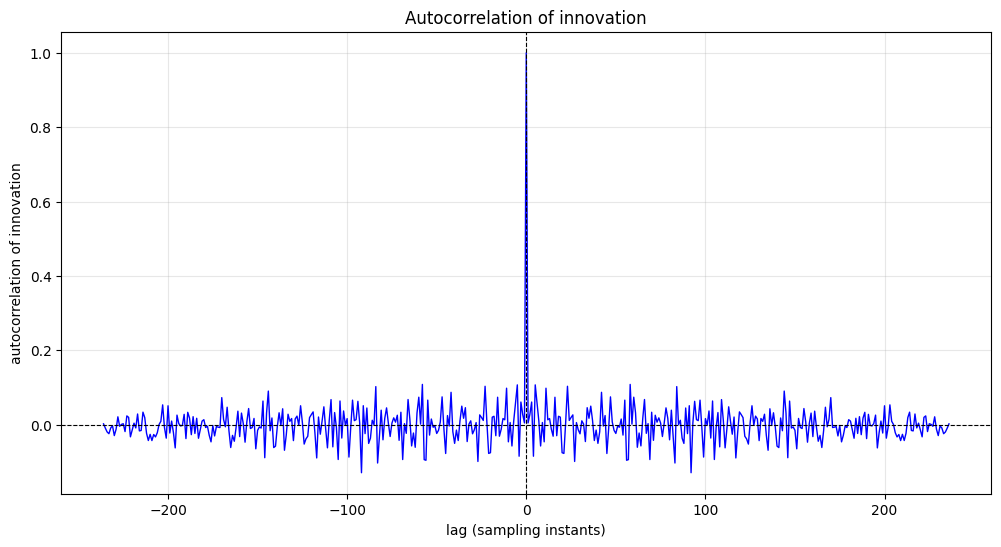

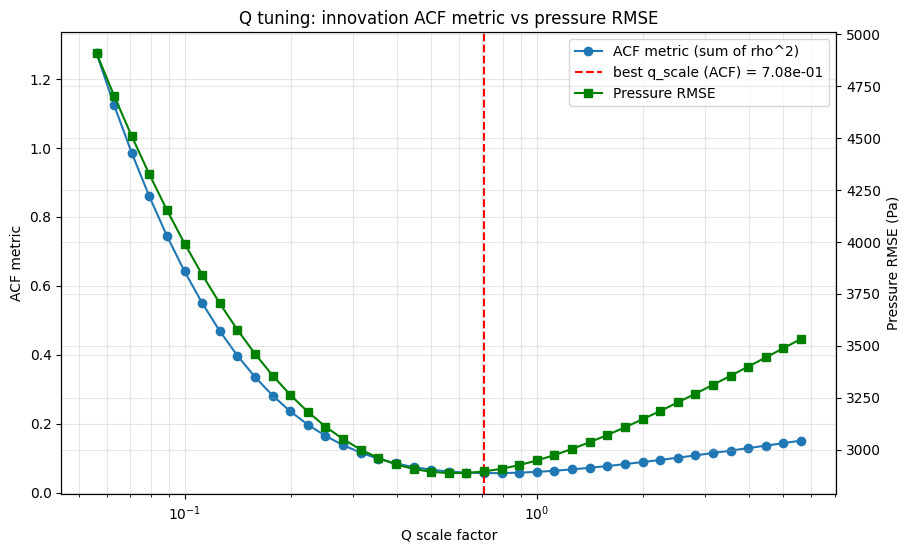

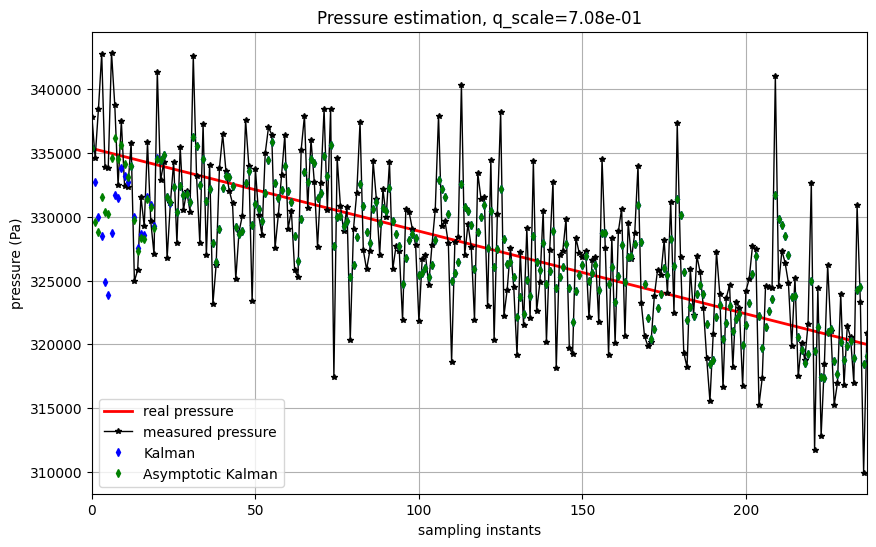

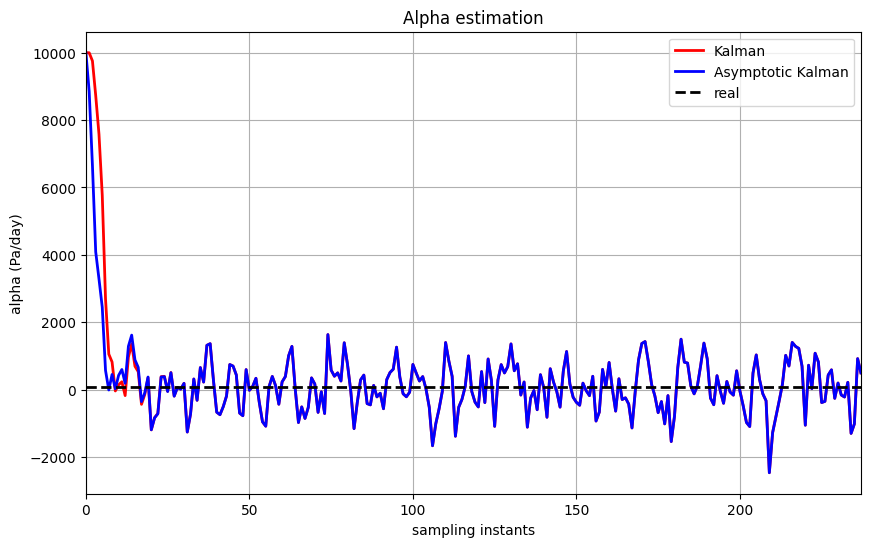

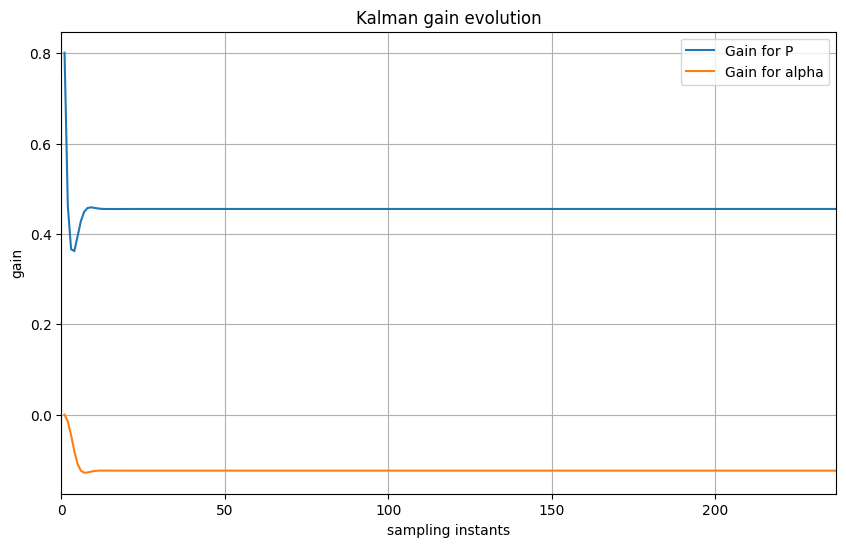

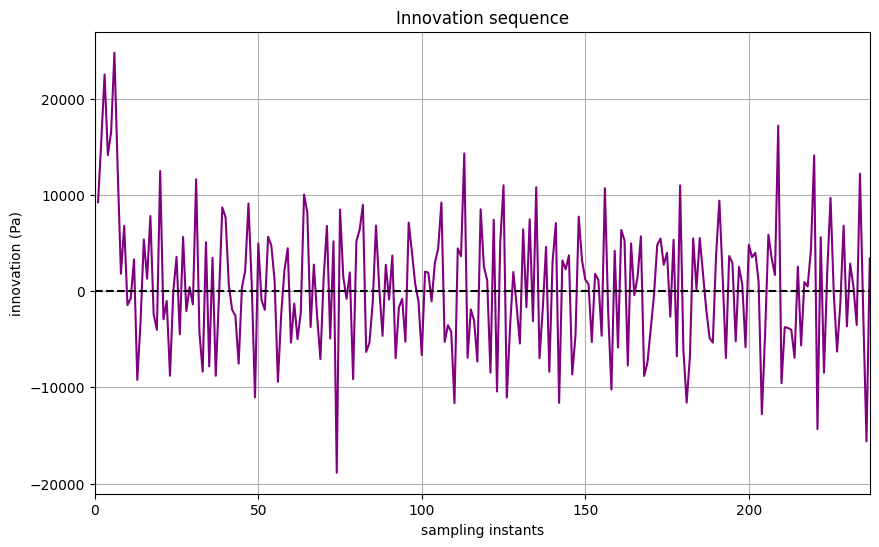

In [1]:
# ============================================================
# Kalman filtering with pressure unit conversion and Q tuning
# (ACF-based Q selection)
#
# Pressure unit:
#     Pa
#
# Alpha unit:
#     Pa/day
#
# Original CSV units:
#     pressure: bar
#     alpha:    bar/day
# ============================================================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



# ============================================================
# 0. 基本设置
# ============================================================
plt.close("all")
np.random.seed(42)


# 单位转换
BAR_TO_PA = 1e5
BAR2_TO_PA2 = BAR_TO_PA ** 2



# ============================================================
# 1. 读取真实系统初始值
# ============================================================
df = pd.read_csv(
    "/Users/wenbo.wu/Documents/Documents - Wenbo WU/Thesis/RTE_use_case/RTE_dashboard/RTE/new_df_AlphaCorrected.csv",
    encoding="utf-8-sig"
)



# target_csemCur = 5002343705
target_csemCur = 5000252545
# target_csemCur = 5000252447



df_csem = df[df["csemCur"] == target_csemCur].copy()



if df_csem.empty:
    raise ValueError(
        f"在 new_df_AlphaCorrected 中没有找到 "
        f"csemCur = {target_csemCur} 的数据"
    )



row0 = df_csem.iloc[0]



# CSV 中的原始单位：
# compensatedRelativePressure_mafiltered: bar
# alpha: bar/day
P0_true_bar = float(
    row0["compensatedRelativePressure_mafiltered"]
)


alpha_true_bar_per_day = float(
    row0["alpha"]
)



# 转换为 Pa 和 Pa/day
P0_true = P0_true_bar * BAR_TO_PA
alpha_true = alpha_true_bar_per_day * BAR_TO_PA



# ============================================================
# 2. 真实系统线性变化
# ============================================================
Te = 1.0  # sampling time, day


# 原始终止压力为 3.2 bar
P_final_bar = 3.2


# 转换为 Pa
P_final = P_final_bar * BAR_TO_PA



if alpha_true <= 0:
    raise ValueError(
        f"alpha_true 必须大于 0，当前值为 "
        f"{alpha_true} Pa/day"
    )



# 计算终止时间
tf = (P0_true - P_final) / alpha_true



if tf <= 0:
    raise ValueError(
        f"计算得到 tf <= 0，请检查：\n"
        f"P0_true = {P0_true} Pa\n"
        f"P_final = {P_final} Pa\n"
        f"alpha_true = {alpha_true} Pa/day"
    )



temps = np.arange(
    0,
    tf + Te,
    Te
)


sampling_instants = np.arange(
    len(temps)
)



# 真实压力，单位 Pa
P_true = P0_true - temps * alpha_true



# ============================================================
# 3. 生成测量数据
# ============================================================
# 测量噪声标准差：
# 原始单位为 0.05 bar
sigma_meas_bar = 0.05


# 转换为 Pa
sigma_meas = sigma_meas_bar * BAR_TO_PA


# 测量压力，单位 Pa
P_measured = (
    P_true
    + sigma_meas * np.random.randn(len(P_true))
)



# ============================================================
# 4. 固定 R
# ============================================================
# R 是测量噪声协方差，单位 Pa^2
#
# sigma_meas = 0.05 bar = 5000 Pa
# R = (5000 Pa)^2 = 2.5e7 Pa^2
R = sigma_meas ** 2



# ============================================================
# 5. 设置初始协方差
# ============================================================
# 原始初始协方差：
# P:     0.01 bar^2
# alpha: 1e-6 (bar/day)^2
#
# 转换到 Pa 后，需要乘以 (1e5)^2
Sigma_priori_init_bar = np.diag([
    0.01,
    1e-6
])


Sigma_priori_init = (
    Sigma_priori_init_bar * BAR2_TO_PA2
)



# 初始 alpha：
# 原始单位为 0.1 bar/day
alpha0_bar_per_day = 0.1
alpha0 = alpha0_bar_per_day * BAR_TO_PA



# ============================================================
# 6. 设置 Q 的基准值
# ============================================================
sigma_process_P_bar = 0.01
sigma_process_alpha_bar_per_day = 0.01



# 由标准差计算方差
q_pressure_bar2 = sigma_process_P_bar ** 2


q_alpha_bar2_per_day2 = (
    sigma_process_alpha_bar_per_day ** 2
)



# 在 bar 单位下构造 Q
Q_base_bar = Te * np.diag([
    q_pressure_bar2,
    q_alpha_bar2_per_day2
])



# 转换为 Pa 相关单位
Q_base = Q_base_bar * BAR2_TO_PA2



# ============================================================
# 7. Kalman filter 函数
# ============================================================
def run_kalman_filter(
    P_measured,
    Te,
    Q,
    R,
    Sigma_priori_init,
    P0,
    alpha0
):
    """
    状态：
        x = [P, alpha]^T


    P:
        Pa


    alpha:
        Pa/day


    Q:
        过程噪声协方差


    R:
        测量噪声协方差，单位 Pa^2
    """


    n_samples = len(P_measured)


    # 状态转移矩阵
    A = np.array([
        [1.0, -Te],
        [0.0,  1.0]
    ])


    # 观测矩阵，只观测压力
    H = np.array([
        [1.0, 0.0]
    ])


    # 初始状态
    x0 = np.array([
        [P0],
        [alpha0]
    ], dtype=float)


    # 初始化
    x_posteriori = x0.copy()
    Sigma_posteriori = Sigma_priori_init.copy()


    Kalman_states = x0.copy()
    Kalman_gain = np.empty((2, 0))
    innovations = []


    # Kalman filtering
    for k in range(n_samples - 1):


        # -------------------------
        # Prediction
        # -------------------------
        x_priori = A @ x_posteriori


        Sigma_priori = (
            A
            @ Sigma_posteriori
            @ A.T
            + Q
        )


        # -------------------------
        # Kalman gain
        # -------------------------
        innovation_covariance = (
            np.array([[R]])
            + H @ Sigma_priori @ H.T
        )


        K = (
            Sigma_priori
            @ H.T
            @ np.linalg.inv(innovation_covariance)
        )


        # -------------------------
        # Innovation
        # -------------------------
        innovation = (
            np.array([[P_measured[k + 1]]])
            - H @ x_priori
        )


        innovations.append(
            float(innovation.item())
        )


        # -------------------------
        # Update state
        # -------------------------
        x_posteriori = (
            x_priori
            + K @ innovation
        )


        # -------------------------
        # Joseph form update
        # -------------------------
        I = np.eye(2)


        Sigma_posteriori = (
            (I - K @ H)
            @ Sigma_priori
            @ (I - K @ H).T
            + K @ np.array([[R]]) @ K.T
        )


        # 保存结果
        Kalman_states = np.hstack([
            Kalman_states,
            x_posteriori
        ])


        Kalman_gain = np.hstack([
            Kalman_gain,
            K
        ])


    return (
        Kalman_states,
        Kalman_gain,
        np.asarray(innovations)
    )



# ============================================================
# 8. 搜索最佳 Q（以创新自相关为主要标准）
# ============================================================
# 指标：
#   acf_metric_sum = sum_{lag=1..L} rho(lag)^2
#   acf_metric_max = max_{lag=1..L} |rho(lag)|
#
# 目标：使 acf_metric_sum 最小

q_scale_grid = np.logspace(
    np.log10(5.62e-1) - 1,
    np.log10(5.62e-1) + 1,
    41
)


q_search_results = []

# 自相关最大 lag
L_acf = 20


for q_scale in q_scale_grid:

    Q_candidate = q_scale * Q_base


    (
        states_candidate,
        gain_candidate,
        innovations_candidate
    ) = run_kalman_filter(
        P_measured=P_measured,
        Te=Te,
        Q=Q_candidate,
        R=R,
        Sigma_priori_init=Sigma_priori_init,
        P0=P0_true,
        alpha0=alpha0
    )


    P_candidate = states_candidate[0, :]


    # 忽略开始阶段的初始化瞬态
    transient = min(
        5,
        max(0, len(P_true) // 10)
    )


    # 压力 RMSE
    pressure_rmse = np.sqrt(
        np.mean(
            (
                P_candidate[transient:]
                - P_true[transient:]
            ) ** 2
        )
    )


    # 压力 MAE
    pressure_mae = np.mean(
        np.abs(
            P_candidate[transient:]
            - P_true[transient:]
        )
    )


    # Innovation RMSE
    innovation_rmse = np.sqrt(
        np.mean(
            innovations_candidate ** 2
        )
    )


    # -------------------------
    # 创新序列自相关指标
    # -------------------------
    nu = np.asarray(
        innovations_candidate,
        dtype=float
    )
    nu = nu - np.mean(nu)

    # 防止数值问题
    if len(nu) < 10 or np.var(nu) <= 0:
        acf_metric_sum = np.nan
        acf_metric_max = np.nan
    else:
        acf_full = np.correlate(
            nu,
            nu,
            mode="full"
        )
        # 零滞后归一化
        acf_full = acf_full / acf_full[len(nu) - 1]

        lags = np.arange(
            -(len(nu) - 1),
            len(nu)
        )

        # 取 lag = 1 .. L_acf
        mask = (lags >= 1) & (lags <= L_acf)
        acf_pos = acf_full[mask]

        acf_metric_sum = np.sum(acf_pos ** 2)
        acf_metric_max = np.max(np.abs(acf_pos))

    q_search_results.append({
        "q_scale": q_scale,
        "acf_metric_sum": acf_metric_sum,
        "acf_metric_max": acf_metric_max,
        "pressure_rmse_Pa": pressure_rmse,
        "pressure_mae_Pa": pressure_mae,
        "innovation_rmse_Pa": innovation_rmse
    })



q_results_df = pd.DataFrame(
    q_search_results
)



# 按 acf_metric_sum 升序排序（越小越接近白噪声）
q_results_sorted = q_results_df.sort_values(
    by="acf_metric_sum",
    ascending=True
).reset_index(drop=True)



# 选择 acf_metric_sum 最小的 q_scale
best_q_scale = float(
    q_results_sorted.loc[0, "q_scale"]
)


best_acf_metric_sum = float(
    q_results_sorted.loc[0, "acf_metric_sum"]
)


best_pressure_rmse = float(
    q_results_sorted.loc[0, "pressure_rmse_Pa"]
)



# 最佳 Q
Q = best_q_scale * Q_base



# ============================================================
# 9. 输出 Q 搜索结果
# ============================================================
print("\n========== Q tuning results (ACF metric) ==========")
print(
    q_results_sorted.head(10)[
        ["q_scale", "acf_metric_sum", "acf_metric_max",
         "pressure_rmse_Pa", "pressure_mae_Pa", "innovation_rmse_Pa"]
    ].to_string(
        index=False
    )
)


print("\n========== Selected parameters (ACF-based) ==========")
print(f"best_q_scale = {best_q_scale:.6e}")
print(f"best_acf_metric_sum = {best_acf_metric_sum:.6e}")
print(
    f"对应的 pressure_RMSE = "
    f"{best_pressure_rmse:.6f} Pa"
)


print("\n========== Noise parameters ==========")
print(f"sigma_meas = {sigma_meas:.6f} Pa")
print(f"R = {R:.6e} Pa^2")


print("\nQ_base =")
print(Q_base)


print("\nQ_selected =")
print(Q)



# ============================================================
# 10. 使用最佳 Q 运行正式 Kalman filter
# ============================================================
(
    Kalman_states,
    Kalman_gain,
    innovations
) = run_kalman_filter(
    P_measured=P_measured,
    Te=Te,
    Q=Q,
    R=R,
    Sigma_priori_init=Sigma_priori_init,
    P0=P0_true,
    alpha0=alpha0
)



P_Kalman = Kalman_states[0, :]
alpha_Kalman = Kalman_states[1, :]



# ============================================================
# 11. Asymptotic Kalman filter
# ============================================================
def run_asymptotic_kalman_filter(
    P_measured,
    Te,
    Q,
    R,
    Sigma_priori_init,
    P0,
    alpha0,
    K
):
    """
    使用固定 Kalman gain 的 asymptotic Kalman filter。
    """


    n_samples = len(P_measured)


    A = np.array([
        [1.0, -Te],
        [0.0,  1.0]
    ])


    H = np.array([
        [1.0, 0.0]
    ])


    x_posteriori = np.array([
        [P0],
        [alpha0]
    ], dtype=float)


    Sigma_posteriori = Sigma_priori_init.copy()


    Kalman_states = x_posteriori.copy()


    for k in range(n_samples - 1):


        # Prediction
        x_priori = A @ x_posteriori


        Sigma_priori = (
            A
            @ Sigma_posteriori
            @ A.T
            + Q
        )


        # 使用固定 gain
        Sigma_posteriori = (
            (np.eye(2) - K @ H)
            @ Sigma_priori
            @ (np.eye(2) - K @ H).T
            + K @ np.array([[R]]) @ K.T
        )


        innovation = (
            np.array([[P_measured[k + 1]]])
            - H @ x_priori
        )


        x_posteriori = (
            x_priori
            + K @ innovation
        )


        Kalman_states = np.hstack([
            Kalman_states,
            x_posteriori
        ])


    return Kalman_states



# 使用正式 Kalman filter 最后的 gain
K_asymptotic = Kalman_gain[:, -1].reshape(2, 1)



Kalman_states2 = run_asymptotic_kalman_filter(
    P_measured=P_measured,
    Te=Te,
    Q=Q,
    R=R,
    Sigma_priori_init=Sigma_priori_init,
    P0=P0_true,
    alpha0=alpha0,
    K=K_asymptotic
)



P_Kalman2 = Kalman_states2[0, :]
alpha_Kalman2 = Kalman_states2[1, :]



# ============================================================
# 12. 压力图
# ============================================================
plt.figure(1, figsize=(10, 6))


plt.plot(
    sampling_instants,
    P_true,
    "r",
    linewidth=2,
    label="real pressure"
)


plt.plot(
    sampling_instants,
    P_measured,
    "*-k",
    linewidth=1,
    markersize=4,
    label="measured pressure"
)


plt.plot(
    sampling_instants,
    P_Kalman,
    "bd",
    markersize=4,
    label="Kalman"
)


plt.plot(
    sampling_instants,
    P_Kalman2,
    "gd",
    markersize=4,
    label="Asymptotic Kalman"
)


plt.xlabel("sampling instants")
plt.ylabel("pressure (Pa)")
plt.title(
    f"Pressure estimation, q_scale={best_q_scale:.2e}"
)
plt.grid(True)
plt.legend()



# ============================================================
# 13. Alpha 图
# ============================================================
plt.figure(2, figsize=(10, 6))


plt.plot(
    sampling_instants,
    alpha_Kalman,
    "r",
    linewidth=2,
    label="Kalman"
)


plt.plot(
    sampling_instants,
    alpha_Kalman2,
    "b",
    linewidth=2,
    label="Asymptotic Kalman"
)


plt.plot(
    sampling_instants,
    alpha_true * np.ones_like(sampling_instants),
    "k--",
    linewidth=2,
    label="real"
)


plt.xlabel("sampling instants")
plt.ylabel("alpha (Pa/day)")
plt.title("Alpha estimation")
plt.grid(True)
plt.legend()



# ============================================================
# 14. Kalman gain 图
# ============================================================
sampling_instants_gain = np.arange(
    1,
    len(temps)
)



plt.figure(3, figsize=(10, 6))


plt.plot(
    sampling_instants_gain,
    Kalman_gain[0, :],
    label="Gain for P"
)


plt.plot(
    sampling_instants_gain,
    Kalman_gain[1, :],
    label="Gain for alpha"
)


plt.title("Kalman gain evolution")
plt.xlabel("sampling instants")
plt.ylabel("gain")
plt.grid(True)
plt.legend()



# ============================================================
# 15. Innovation 序列
# ============================================================
sampling_instants_innov = np.arange(
    1,
    len(temps)
)



plt.figure(4, figsize=(10, 6))


plt.plot(
    sampling_instants_innov,
    innovations,
    color="purple",
    linewidth=1.5
)


plt.axhline(
    0,
    color="black",
    linestyle="--"
)


plt.title("Innovation sequence")
plt.xlabel("sampling instants")
plt.ylabel("innovation (Pa)")
plt.grid(True)



# ============================================================
# 16. Innovation 对称自相关图
# ============================================================
x = np.asarray(
    innovations,
    dtype=float
)
x = x - np.mean(x)



if len(x) > 1 and np.var(x) > 0:


    acf_full = np.correlate(
        x,
        x,
        mode="full"
    )
    # 使用零滞后自相关进行归一化
    acf_full = (
        acf_full
        / acf_full[len(x) - 1]
    )


    lags = np.arange(
        -(len(x) - 1),
        len(x)
    )


    max_lag = min(
        2000,
        len(x) - 1
    )


    mask = (
        (lags >= -max_lag)
        & (lags <= max_lag)
    )


    plt.figure(5, figsize=(12, 6))


    plt.plot(
        lags[mask],
        acf_full[mask],
        color="blue",
        linewidth=1
    )


    plt.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=0.8
    )


    plt.axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=0.8
    )


    plt.xlabel("lag (sampling instants)")
    plt.ylabel("autocorrelation of innovation")
    plt.title("Autocorrelation of innovation")
    plt.grid(True, alpha=0.3)



# ============================================================
# 17. Q 搜索结果：ACF 指标与 RMSE
# ============================================================
plt.figure(6, figsize=(10, 6))


ax1 = plt.gca()


ax1.semilogx(
    q_results_df["q_scale"],
    q_results_df["acf_metric_sum"],
    "o-",
    linewidth=1.5,
    label="ACF metric (sum of rho^2)"
)


ax1.axvline(
    best_q_scale,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=(
        f"best q_scale (ACF) = "
        f"{best_q_scale:.2e}"
    )
)


ax1.set_xlabel("Q scale factor")
ax1.set_ylabel("ACF metric")
ax1.grid(True, which="both", alpha=0.3)


ax2 = ax1.twinx()


ax2.semilogx(
    q_results_df["q_scale"],
    q_results_df["pressure_rmse_Pa"],
    "s-",
    color="green",
    linewidth=1.5,
    label="Pressure RMSE"
)


ax2.set_ylabel("Pressure RMSE (Pa)")


# 合并两个轴的 legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2)


plt.title("Q tuning: innovation ACF metric vs pressure RMSE")
plt.grid(True, which="both", alpha=0.3)



# ============================================================
# 18. 放大 x 轴前段
# ============================================================
x_max_zoom = min(
    2000,
    len(sampling_instants) - 1
)



plt.figure(1)
plt.xlim(0, x_max_zoom)


plt.figure(2)
plt.xlim(0, x_max_zoom)


plt.figure(3)
plt.xlim(0, x_max_zoom)


plt.figure(4)
plt.xlim(0, x_max_zoom)



# ============================================================
# 19. 打印关键信息
# ============================================================
print("\n========== System information ==========")
print("target_csemCur =", target_csemCur)
print(f"P0_true = {P0_true:.6f} Pa")
print(f"alpha_true = {alpha_true:.6f} Pa/day")
print(f"P_final = {P_final:.6f} Pa")
print(f"tf = {tf:.6f} days")
print(
    "number of sampling instants =",
    len(sampling_instants)
)
print("x_max_zoom =", x_max_zoom)



plt.show()


========== Q tuning results (manual s_alpha grid) ==========
 s_alpha  pressure_rmse_Pa  alpha_rmse_Pa  nu_mean   nu_std  nu_sq_mean  innovation_rmse_Pa
0.794328       2898.851203     804.340209 0.079726 0.996209    0.998788         6709.943467
0.630957       2941.528962     821.471857 0.099978 1.031566    1.074124         6755.302313
1.000000       2947.327790     860.626177 0.063660 0.966226    0.937645         6723.158746
1.258925       3054.613936     984.688923 0.050950 0.939833    0.885883         6787.630390
0.501187       3105.289299     900.975714 0.125404 1.074495    1.170265         6870.312827
1.584893       3194.091972    1162.795209 0.040904 0.915580    0.839959         6899.998372
1.995262       3347.956143    1384.810058 0.032962 0.892210    0.797124         7059.826170
0.398107       3408.273121    1022.885088 0.157182 1.127571    1.296123         7068.839456
2.511886       3506.126664    1647.422003 0.026689 0.868535    0.755066         7267.810847
3.162278       366

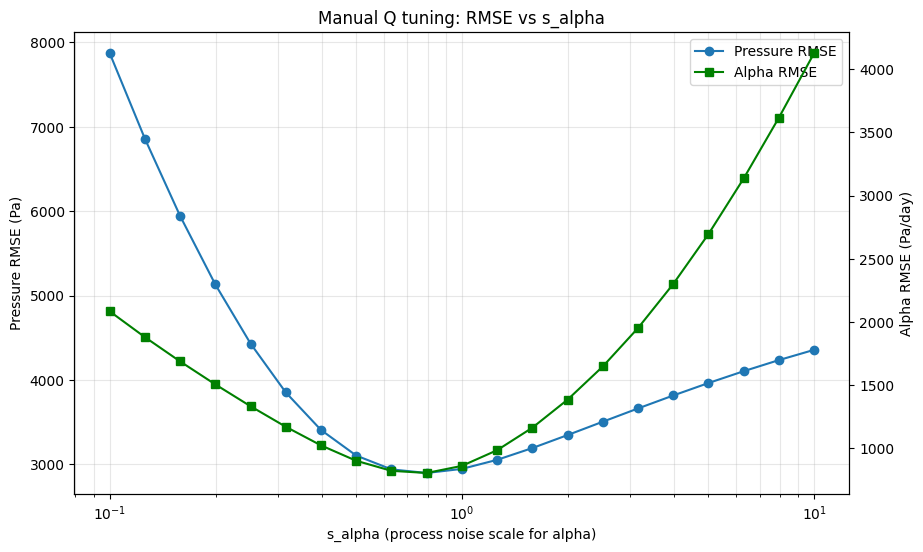

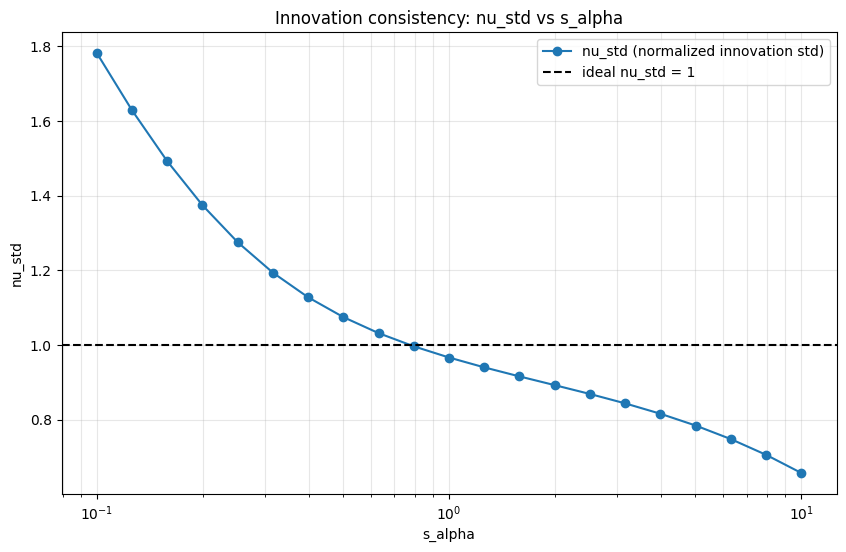

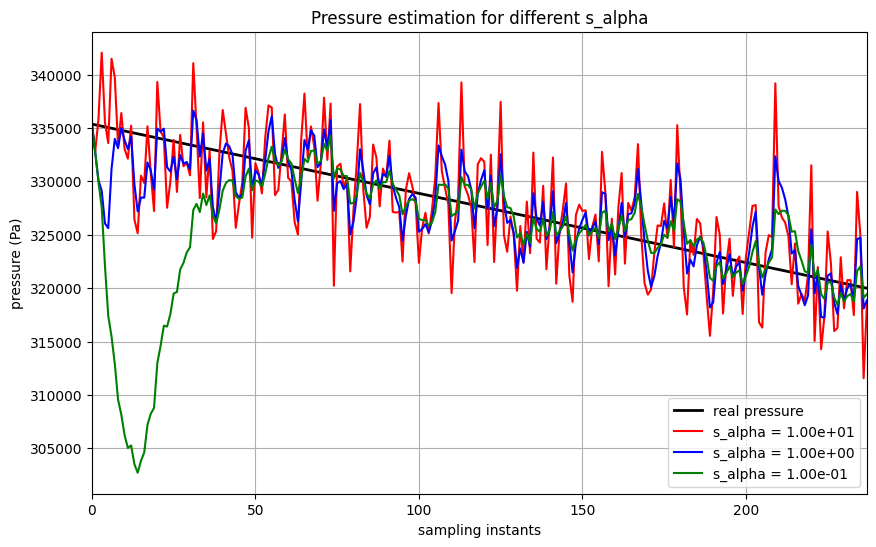

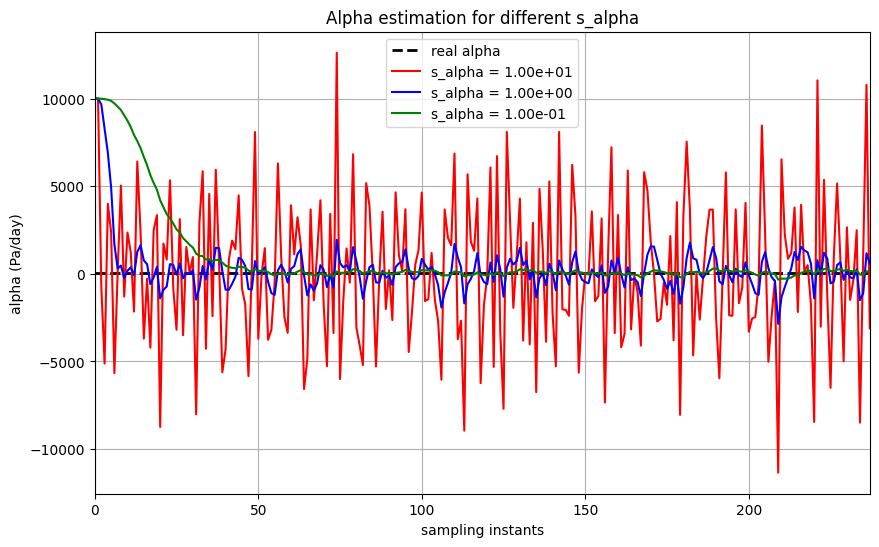

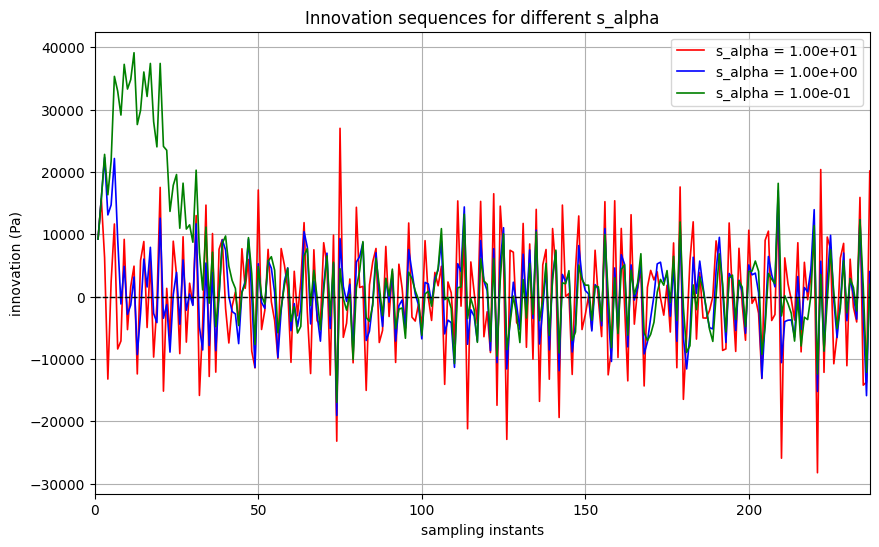

In [5]:
# ============================================================
# Kalman filtering with manual Q ratio tuning (s_alpha grid)
# and innovation consistency check (no ACF metric)
#
# Pressure unit:
#     Pa
#
# Alpha unit:
#     Pa/day
#
# Original CSV units:
#     pressure: bar
#     alpha:    bar/day
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 0. 基本设置
# ============================================================
plt.close("all")
np.random.seed(42)


# 单位转换
BAR_TO_PA = 1e5
BAR2_TO_PA2 = BAR_TO_PA ** 2


# ============================================================
# 1. 读取真实系统初始值
# ============================================================
df = pd.read_csv(
    "/Users/wenbo.wu/Documents/Documents - Wenbo WU/Thesis/RTE_use_case/RTE_dashboard/RTE/new_df_AlphaCorrected.csv",
    encoding="utf-8-sig"
)


# target_csemCur = 5002343705
target_csemCur = 5000252545
# target_csemCur = 5000252447


df_csem = df[df["csemCur"] == target_csemCur].copy()


if df_csem.empty:
    raise ValueError(
        f"在 new_df_AlphaCorrected 中没有找到 "
        f"csemCur = {target_csemCur} 的数据"
    )


row0 = df_csem.iloc[0]


# CSV 中的原始单位：
# compensatedRelativePressure_mafiltered: bar
# alpha: bar/day
P0_true_bar = float(
    row0["compensatedRelativePressure_mafiltered"]
)

alpha_true_bar_per_day = float(
    row0["alpha"]
)


# 转换为 Pa 和 Pa/day
P0_true = P0_true_bar * BAR_TO_PA
alpha_true = alpha_true_bar_per_day * BAR_TO_PA


# ============================================================
# 2. 真实系统线性变化
# ============================================================
Te = 1.0  # sampling time, day


# 原始终止压力为 3.2 bar
P_final_bar = 3.2


# 转换为 Pa
P_final = P_final_bar * BAR_TO_PA


if alpha_true <= 0:
    raise ValueError(
        f"alpha_true 必须大于 0，当前值为 "
        f"{alpha_true} Pa/day"
    )


# 计算终止时间
tf = (P0_true - P_final) / alpha_true


if tf <= 0:
    raise ValueError(
        f"计算得到 tf <= 0，请检查：\n"
        f"P0_true = {P0_true} Pa\n"
        f"P_final = {P_final} Pa\n"
        f"alpha_true = {alpha_true} Pa/day"
    )


temps = np.arange(
    0,
    tf + Te,
    Te
)

sampling_instants = np.arange(
    len(temps)
)


# 真实压力，单位 Pa
P_true = P0_true - temps * alpha_true


# ============================================================
# 3. 生成测量数据
# ============================================================
# 测量噪声标准差：
# 原始单位为 0.05 bar
sigma_meas_bar = 0.05


# 转换为 Pa
sigma_meas = sigma_meas_bar * BAR_TO_PA


# 测量压力，单位 Pa
P_measured = (
    P_true
    + sigma_meas * np.random.randn(len(P_true))
)


# ============================================================
# 4. 固定 R
# ============================================================
# R 是测量噪声协方差，单位 Pa^2
#
# sigma_meas = 0.05 bar = 5000 Pa
# R = (5000 Pa)^2 = 2.5e7 Pa^2
R = sigma_meas ** 2


# ============================================================
# 5. 设置初始协方差
# ============================================================
# 原始初始协方差：
# P:     0.01 bar^2
# alpha: 1e-6 (bar/day)^2
#
# 转换到 Pa 后，需要乘以 (1e5)^2
Sigma_priori_init_bar = np.diag([
    0.01,
    1e-6
])

Sigma_priori_init = (
    Sigma_priori_init_bar * BAR2_TO_PA2
)


# 初始 alpha：
# 原始单位为 0.1 bar/day
alpha0_bar_per_day = 0.1
alpha0 = alpha0_bar_per_day * BAR_TO_PA


# ============================================================
# 6. 设置 Q 的基准值（bar 单位下）
# ============================================================
sigma_process_P_bar = 0.01
sigma_process_alpha_bar_per_day = 0.01


# 由标准差计算方差
q_pressure_bar2 = sigma_process_P_bar ** 2
q_alpha_bar2_per_day2 = (
    sigma_process_alpha_bar_per_day ** 2
)


# 注意：这里不再直接构造 Q_base，而是在后面用 s_P, s_alpha 控制比例


# ============================================================
# 7. Kalman filter 函数（返回创新方差序列 S_array）
# ============================================================
def run_kalman_filter(
    P_measured,
    Te,
    Q,
    R,
    Sigma_priori_init,
    P0,
    alpha0
):
    """
    状态：
        x = [P, alpha]^T

    P:
        Pa

    alpha:
        Pa/day

    Q:
        过程噪声协方差

    R:
        测量噪声协方差，单位 Pa^2

    返回：
        Kalman_states: 2 x N
        Kalman_gain:   2 x (N-1)
        innovations:   (N-1,)
        S_array:       (N-1,)  创新方差 S_k = H P_{k|k-1} H^T + R
    """

    n_samples = len(P_measured)

    # 状态转移矩阵
    A = np.array([
        [1.0, -Te],
        [0.0,  1.0]
    ])

    # 观测矩阵，只观测压力
    H = np.array([
        [1.0, 0.0]
    ])

    # 初始状态
    x0 = np.array([
        [P0],
        [alpha0]
    ], dtype=float)

    # 初始化
    x_posteriori = x0.copy()
    Sigma_posteriori = Sigma_priori_init.copy()

    Kalman_states = x0.copy()
    Kalman_gain = np.empty((2, 0))
    innovations = []
    S_list = []

    # Kalman filtering
    for k in range(n_samples - 1):

        # -------------------------
        # Prediction
        # -------------------------
        x_priori = A @ x_posteriori

        Sigma_priori = (
            A
            @ Sigma_posteriori
            @ A.T
            + Q
        )

        # -------------------------
        # Innovation covariance S_k
        # -------------------------
        S = (
            H @ Sigma_priori @ H.T
            + np.array([[R]])
        ).item()

        S_list.append(S)

        # -------------------------
        # Kalman gain
        # -------------------------
        innovation_covariance = (
            np.array([[R]])
            + H @ Sigma_priori @ H.T
        )

        K = (
            Sigma_priori
            @ H.T
            @ np.linalg.inv(innovation_covariance)
        )

        # -------------------------
        # Innovation
        # -------------------------
        innovation = (
            np.array([[P_measured[k + 1]]])
            - H @ x_priori
        )

        innovations.append(
            float(innovation.item())
        )

        # -------------------------
        # Update state
        # -------------------------
        x_posteriori = (
            x_priori
            + K @ innovation
        )

        # -------------------------
        # Joseph form update
        # -------------------------
        I = np.eye(2)

        Sigma_posteriori = (
            (I - K @ H)
            @ Sigma_priori
            @ (I - K @ H).T
            + K @ np.array([[R]]) @ K.T
        )

        # 保存结果
        Kalman_states = np.hstack([
            Kalman_states,
            x_posteriori
        ])

        Kalman_gain = np.hstack([
            Kalman_gain,
            K
        ])

    return (
        Kalman_states,
        Kalman_gain,
        np.asarray(innovations),
        np.asarray(S_list)
    )


# ============================================================
# 8. 手动网格搜索 s_alpha（P 和 alpha 过程噪声比例）
# ============================================================
# Q 结构：
#   Q = Te * diag(
#         (s_P^2) * q_pressure_bar2,
#         (s_alpha^2) * q_alpha_bar2_per_day2
#       ) * BAR2_TO_PA2
#
# 这里固定 s_P = 1，只调 s_alpha

s_P = 1.0

# s_alpha 搜索范围：0.1 ~ 10，共 21 档
s_alpha_grid = np.logspace(-1, 1, 21)

results = []

for s_alpha in s_alpha_grid:

    # 在 bar 单位下构造 Q
    Q_bar = Te * np.diag([
        (s_P ** 2) * q_pressure_bar2,
        (s_alpha ** 2) * q_alpha_bar2_per_day2
    ])

    # 转换到 Pa 相关单位
    Q_candidate = Q_bar * BAR2_TO_PA2

    (
        states_candidate,
        gain_candidate,
        innovations_candidate,
        S_array
    ) = run_kalman_filter(
        P_measured=P_measured,
        Te=Te,
        Q=Q_candidate,
        R=R,
        Sigma_priori_init=Sigma_priori_init,
        P0=P0_true,
        alpha0=alpha0
    )

    P_candidate = states_candidate[0, :]
    alpha_candidate = states_candidate[1, :]

    # 忽略开始阶段的初始化瞬态
    transient = min(
        5,
        max(0, len(P_true) // 10)
    )

    # 压力 RMSE
    pressure_rmse = np.sqrt(
        np.mean(
            (
                P_candidate[transient:]
                - P_true[transient:]
            ) ** 2
        )
    )

    # 压力 MAE
    pressure_mae = np.mean(
        np.abs(
            P_candidate[transient:]
            - P_true[transient:]
        )
    )

    # alpha RMSE
    alpha_rmse = np.sqrt(
        np.mean(
            (
                alpha_candidate[transient:]
                - alpha_true
            ) ** 2
        )
    )

    # Innovation RMSE
    innovation_rmse = np.sqrt(
        np.mean(
            innovations_candidate ** 2
        )
    )

    # -------------------------
    # 归一化创新统计量
    # -------------------------
    nu = innovations_candidate.astype(float)
    # 去掉可能的 NaN / inf
    valid = np.isfinite(nu) & np.isfinite(S_array)
    nu = nu[valid]
    S_valid = S_array[valid]

    if len(nu) < 10 or np.any(S_valid <= 0):
        nu_mean = np.nan
        nu_std = np.nan
        nu_sq_mean = np.nan
    else:
        nu_tilde = nu / np.sqrt(S_valid)
        nu_mean = np.mean(nu_tilde)
        nu_std = np.std(nu_tilde)
        nu_sq_mean = np.mean(nu_tilde ** 2)

    results.append({
        "s_alpha": s_alpha,
        "acf_metric_sum": np.nan,  # 不再使用
        "acf_metric_max": np.nan,
        "pressure_rmse_Pa": pressure_rmse,
        "pressure_mae_Pa": pressure_mae,
        "alpha_rmse_Pa": alpha_rmse,
        "innovation_rmse_Pa": innovation_rmse,
        "nu_mean": nu_mean,
        "nu_std": nu_std,
        "nu_sq_mean": nu_sq_mean,
        "states": states_candidate,
        "innovations": innovations_candidate,
        "S_array": S_array
    })


results_df = pd.DataFrame(results)


# ============================================================
# 9. 输出 Q 搜索结果（按 pressure_rmse 排序示例）
# ============================================================
print("\n========== Q tuning results (manual s_alpha grid) ==========")
print(
    results_df.sort_values("pressure_rmse_Pa")[
        ["s_alpha", "pressure_rmse_Pa", "alpha_rmse_Pa",
         "nu_mean", "nu_std", "nu_sq_mean", "innovation_rmse_Pa"]
    ].head(10).to_string(
        index=False
    )
)


# 选择一个 nu_std 接近 1 的 s_alpha 作为“推荐”
valid_rows = results_df[np.isfinite(results_df["nu_std"])]
if not valid_rows.empty:
    # 找 nu_std 最接近 1 的行
    idx_best_nu = (
        (valid_rows["nu_std"] - 1.0).abs()
    ).idxmin()

    best_row = results_df.loc[idx_best_nu]

    print("\n========== Selected parameters (innovation-based) ==========")
    print(f"best_s_alpha (nu_std closest to 1) = {best_row['s_alpha']:.6e}")
    print(f"nu_mean = {best_row['nu_mean']:.6f}")
    print(f"nu_std  = {best_row['nu_std']:.6f}")
    print(f"nu_sq_mean = {best_row['nu_sq_mean']:.6f}")
    print(
        f"对应的 pressure_RMSE = "
        f"{best_row['pressure_rmse_Pa']:.6f} Pa"
    )
    print(
        f"对应的 alpha_RMSE = "
        f"{best_row['alpha_rmse_Pa']:.6f} Pa/day"
    )
else:
    print("\n没有有效的 nu_std 数据，请检查实现。")


print("\n========== Noise parameters ==========")
print(f"sigma_meas = {sigma_meas:.6f} Pa")
print(f"R = {R:.6e} Pa^2")

print("\nQ 基准结构（bar 单位）:")
print(
    "Q_bar = Te * diag( "
    f"(s_P^2)*{q_pressure_bar2:.2e}, "
    f"(s_alpha^2)*{q_alpha_bar2_per_day2:.2e} )"
)


# ============================================================
# 10. 画图：RMSE 和 nu_std 随 s_alpha 的变化
# ============================================================
plt.figure(10, figsize=(10, 6))

ax1 = plt.gca()

ax1.semilogx(
    results_df["s_alpha"],
    results_df["pressure_rmse_Pa"],
    "o-",
    linewidth=1.5,
    label="Pressure RMSE"
)

ax1.set_xlabel("s_alpha (process noise scale for alpha)")
ax1.set_ylabel("Pressure RMSE (Pa)")
ax1.grid(True, which="both", alpha=0.3)

ax2 = ax1.twinx()

ax2.semilogx(
    results_df["s_alpha"],
    results_df["alpha_rmse_Pa"],
    "s-",
    color="green",
    linewidth=1.5,
    label="Alpha RMSE"
)

ax2.set_ylabel("Alpha RMSE (Pa/day)")

# 合并 legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.title("Manual Q tuning: RMSE vs s_alpha")


plt.figure(11, figsize=(10, 6))

plt.semilogx(
    results_df["s_alpha"],
    results_df["nu_std"],
    "o-",
    linewidth=1.5,
    label="nu_std (normalized innovation std)"
)

plt.axhline(1.0, color="k", linestyle="--", linewidth=1.5, label="ideal nu_std = 1")

plt.xlabel("s_alpha")
plt.ylabel("nu_std")
plt.title("Innovation consistency: nu_std vs s_alpha")
plt.grid(True, which="both", alpha=0.3)
plt.legend()


# ============================================================
# 11. 选择 3 个典型 s_alpha 画 P 和 alpha 的时间序列
# ============================================================
# 选择：nu_std 最小、最接近 1、最大 的三个（在有限范围内）
valid_df = results_df[np.isfinite(results_df["nu_std"])].copy()

if len(valid_df) >= 3:
    # 排序
    sorted_by_nu = valid_df.sort_values("nu_std")

    idx_min = sorted_by_nu.iloc[0].name
    idx_mid = sorted_by_nu.iloc[len(sorted_by_nu)//2].name
    idx_max = sorted_by_nu.iloc[-1].name

    selected_indices = [idx_min, idx_mid, idx_max]
else:
    # 如果数据太少，就随便选前三个
    selected_indices = results_df.index[:3].tolist()


# 颜色
colors = ["red", "blue", "green"]
labels = [
    f"s_alpha = {results_df.loc[i, 's_alpha']:.2e}"
    for i in selected_indices
]


# P 的图
plt.figure(12, figsize=(10, 6))

plt.plot(
    sampling_instants,
    P_true,
    "k-",
    linewidth=2,
    label="real pressure"
)

for c, idx in zip(colors, selected_indices):
    states_tmp = results_df.loc[idx, "states"]
    P_tmp = states_tmp[0, :]

    plt.plot(
        sampling_instants,
        P_tmp,
        color=c,
        linewidth=1.5,
        label=labels[colors.index(c)]
    )

plt.xlabel("sampling instants")
plt.ylabel("pressure (Pa)")
plt.title("Pressure estimation for different s_alpha")
plt.grid(True)
plt.legend()


# Alpha 的图
plt.figure(13, figsize=(10, 6))

plt.plot(
    sampling_instants,
    alpha_true * np.ones_like(sampling_instants),
    "k--",
    linewidth=2,
    label="real alpha"
)

for c, idx in zip(colors, selected_indices):
    states_tmp = results_df.loc[idx, "states"]
    alpha_tmp = states_tmp[1, :]

    plt.plot(
        sampling_instants,
        alpha_tmp,
        color=c,
        linewidth=1.5,
        label=labels[colors.index(c)]
    )

plt.xlabel("sampling instants")
plt.ylabel("alpha (Pa/day)")
plt.title("Alpha estimation for different s_alpha")
plt.grid(True)
plt.legend()


# ============================================================
# 12. 对应 innovation 序列
# ============================================================
plt.figure(14, figsize=(10, 6))

for c, idx in zip(colors, selected_indices):
    innov_tmp = results_df.loc[idx, "innovations"]
    t_innov = np.arange(1, len(innov_tmp) + 1)

    plt.plot(
        t_innov,
        innov_tmp,
        color=c,
        linewidth=1.2,
        label=labels[colors.index(c)]
    )

plt.axhline(0, color="k", linestyle="--", linewidth=1)
plt.xlabel("sampling instants")
plt.ylabel("innovation (Pa)")
plt.title("Innovation sequences for different s_alpha")
plt.grid(True)
plt.legend()


# ============================================================
# 13. 放大 x 轴前段（可选）
# ============================================================
x_max_zoom = min(
    2000,
    len(sampling_instants) - 1
)

plt.figure(12)
plt.xlim(0, x_max_zoom)

plt.figure(13)
plt.xlim(0, x_max_zoom)

plt.figure(14)
plt.xlim(0, x_max_zoom)


# ============================================================
# 14. 打印关键信息
# ============================================================
print("\n========== System information ==========")
print("target_csemCur =", target_csemCur)
print(f"P0_true = {P0_true:.6f} Pa")
print(f"alpha_true = {alpha_true:.6f} Pa/day")
print(f"P_final = {P_final:.6f} Pa")
print(f"tf = {tf:.6f} days")
print(
    "number of sampling instants =",
    len(sampling_instants)
)
print("x_max_zoom =", x_max_zoom)


plt.show()


========== Manual common-Q tuning results ==========
  q_scale  pressure_rmse_Pa  pressure_mae_Pa  alpha_rmse_Pa_per_day  innovation_rmse_Pa   nu_mean   nu_std  nu_sq_mean
 0.031623       1983.352573      1528.680549             270.897338         8961.241692 -0.012218 0.949645    0.897818
 0.039811       1959.834021      1526.168571             282.947879         8568.635242 -0.015111 0.945279    0.889662
 0.050119       1974.878439      1536.148943             296.086992         8223.760651 -0.016145 0.942503    0.884480
 0.063096       2011.847669      1558.814057             311.060939         7923.733837 -0.015961 0.940324    0.880389
 0.079433       2060.742714      1590.820571             328.732735         7665.453920 -0.015069 0.938234    0.876454
 0.100000       2116.186208      1631.984955             349.832705         7445.693778 -0.013859 0.936016    0.872280
 0.125893       2175.534163      1676.575345             374.853307         7261.194781 -0.012606 0.933593    0.8

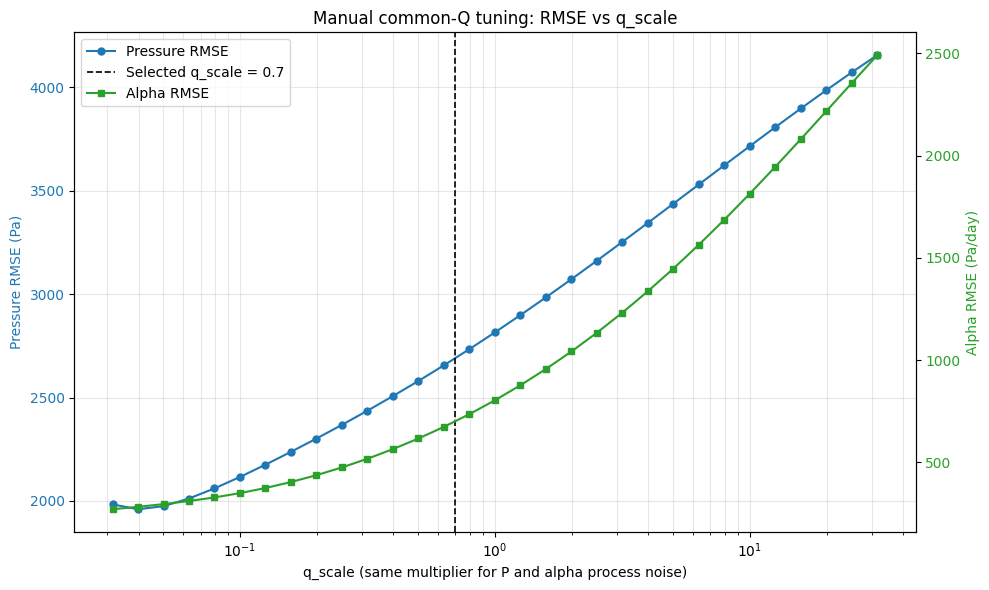

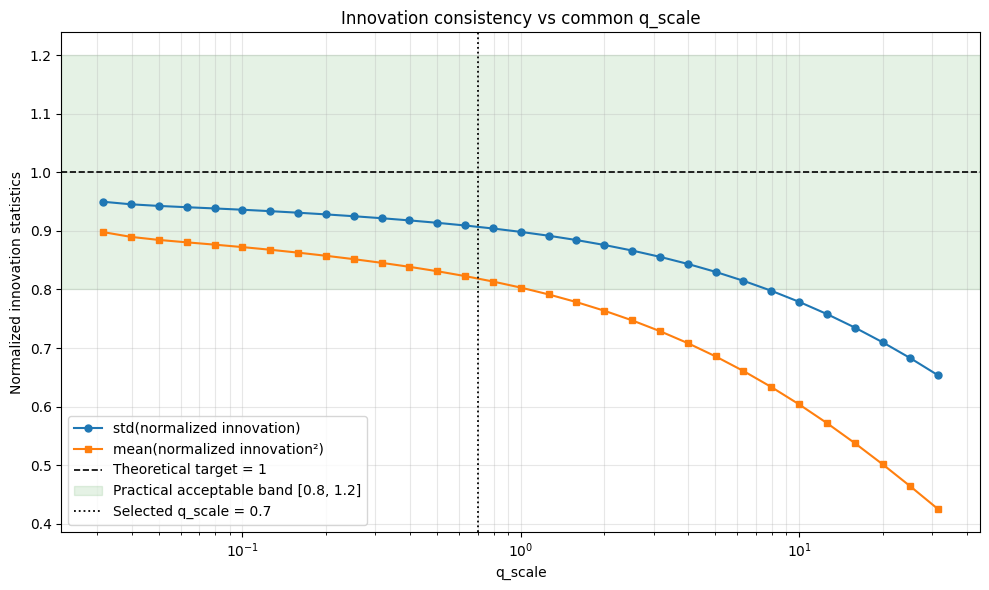

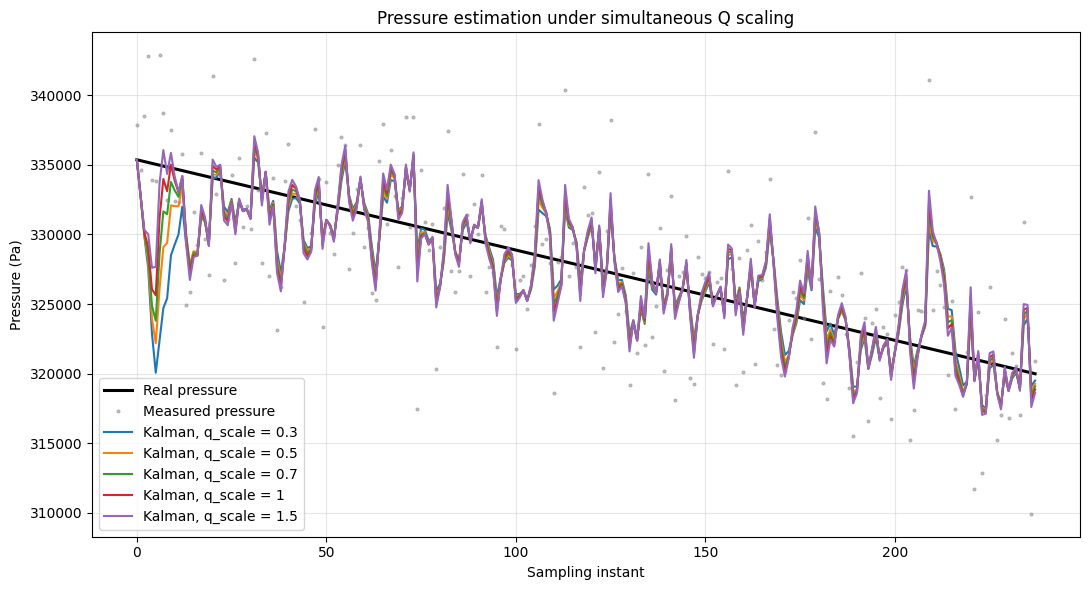

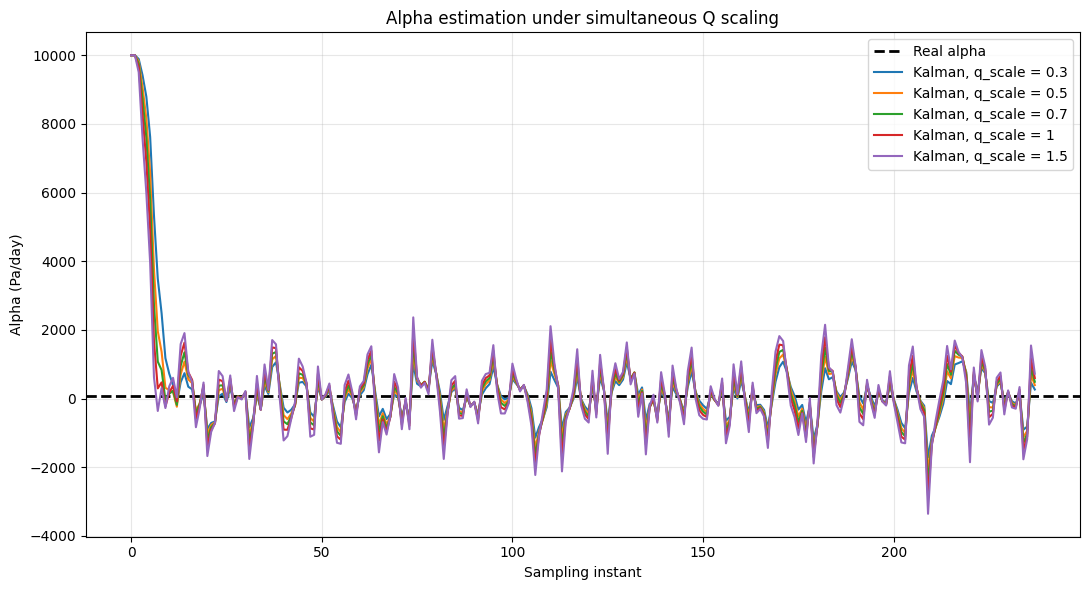

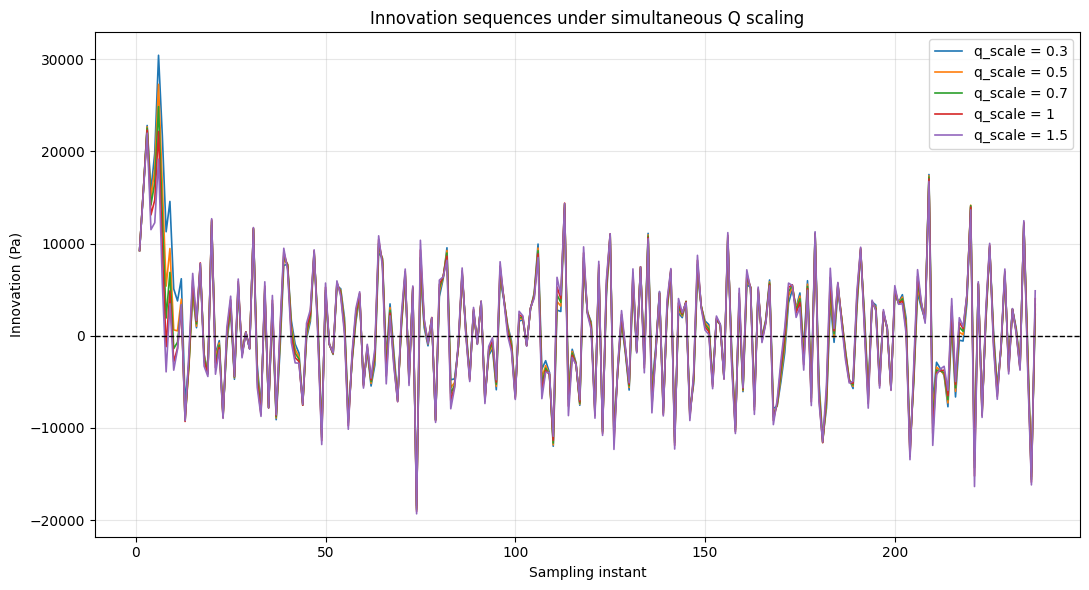

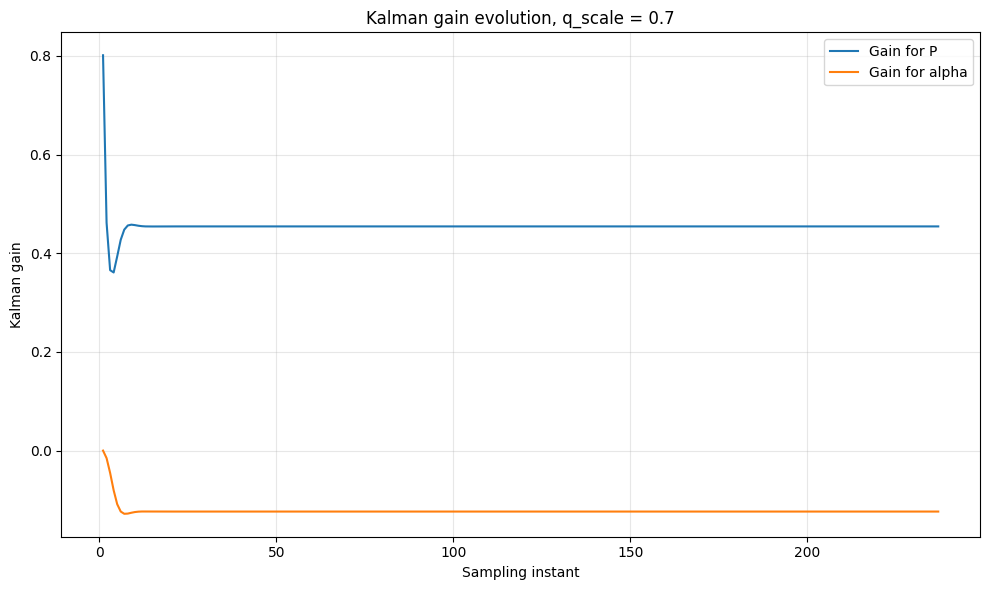

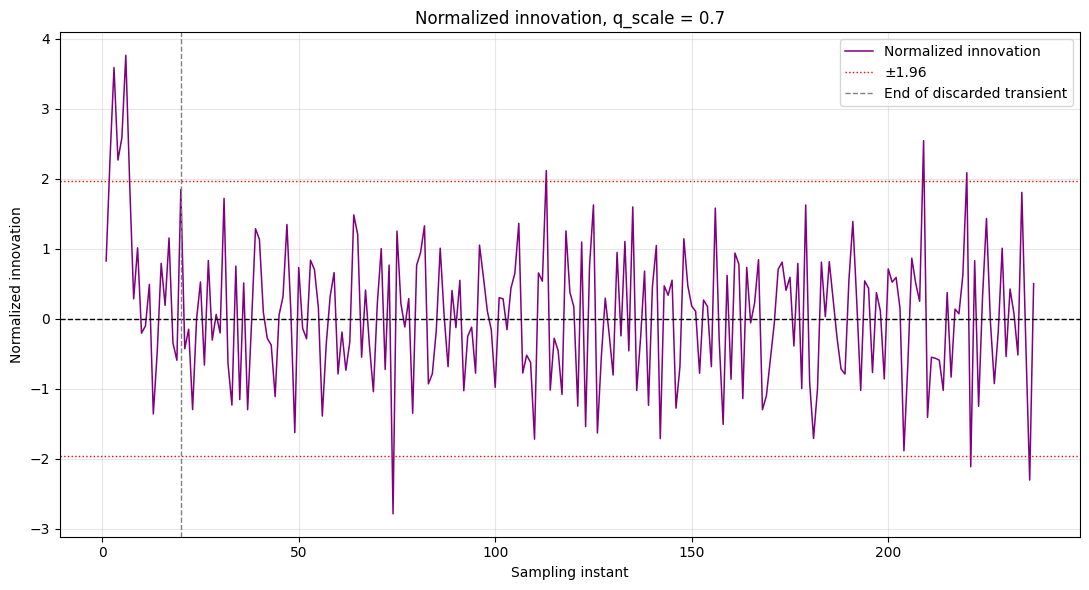

In [6]:
# ============================================================
# Kalman filtering with manual common-Q tuning
#
# State:
#     x = [P, alpha]^T
#
# Unit:
#     P:     Pa
#     alpha: Pa/day
#
# Original CSV unit:
#     pressure: bar
#     alpha:    bar/day
#
# Q tuning:
#     Q = q_scale * Q_base
#
# q_scale simultaneously adjusts:
#     - Q[0, 0]: pressure process-noise variance
#     - Q[1, 1]: alpha process-noise variance
#
# This script does NOT use innovation ACF for selection.
# It provides:
#     1. manual q_scale grid scan,
#     2. P/alpha RMSE in simulation,
#     3. normalized innovation consistency checks,
#     4. comparison plots,
#     5. one manually selected final q_scale.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 0. General settings
# ============================================================
plt.close("all")
np.random.seed(42)

BAR_TO_PA = 1e5
BAR2_TO_PA2 = BAR_TO_PA ** 2


# ============================================================
# 1. Read initial condition from CSV
# ============================================================
csv_path = (
    "/Users/wenbo.wu/Documents/Documents - Wenbo WU/"
    "Thesis/RTE_use_case/RTE_dashboard/RTE/"
    "new_df_AlphaCorrected.csv"
)

df = pd.read_csv(
    csv_path,
    encoding="utf-8-sig"
)

# target_csemCur = 5002343705
target_csemCur = 5000252545
# target_csemCur = 5000252447

df_csem = df[df["csemCur"] == target_csemCur].copy()

if df_csem.empty:
    raise ValueError(
        "在 new_df_AlphaCorrected.csv 中没有找到 "
        f"csemCur = {target_csemCur}"
    )

row0 = df_csem.iloc[0]

P0_true_bar = float(
    row0["compensatedRelativePressure_mafiltered"]
)

alpha_true_bar_per_day = float(
    row0["alpha"]
)

P0_true = P0_true_bar * BAR_TO_PA
alpha_true = alpha_true_bar_per_day * BAR_TO_PA


# ============================================================
# 2. Create the simulated true pressure trajectory
# ============================================================
Te = 1.0  # Sampling interval: 1 day

P_final_bar = 3.2
P_final = P_final_bar * BAR_TO_PA

if alpha_true <= 0:
    raise ValueError(
        "alpha_true 必须为正。当前值为："
        f"{alpha_true:.6f} Pa/day"
    )

tf = (P0_true - P_final) / alpha_true

if tf <= 0:
    raise ValueError(
        "计算得到 tf <= 0，请检查 P0_true、P_final 和 alpha_true。\n"
        f"P0_true = {P0_true:.6f} Pa\n"
        f"P_final = {P_final:.6f} Pa\n"
        f"alpha_true = {alpha_true:.6f} Pa/day"
    )

temps = np.arange(
    0.0,
    tf + Te,
    Te
)

sampling_instants = np.arange(
    len(temps)
)

P_true = P0_true - temps * alpha_true


# ============================================================
# 3. Generate pressure measurements
# ============================================================
sigma_meas_bar = 0.05
sigma_meas = sigma_meas_bar * BAR_TO_PA

P_measured = (
    P_true
    + sigma_meas * np.random.randn(len(P_true))
)

# Measurement-noise variance
R = sigma_meas ** 2


# ============================================================
# 4. Initial state and initial covariance
# ============================================================
# Initial covariance expressed in original bar units:
#   var(P0)     = 0.01 bar^2
#   var(alpha0) = 1e-6 (bar/day)^2
Sigma_priori_init_bar = np.diag([
    0.01,
    1e-6
])

Sigma_priori_init = (
    Sigma_priori_init_bar * BAR2_TO_PA2
)

# Initial alpha guess
# Keep this as your original value for direct comparability.
# Note:
#   0.1 bar/day = 10000 Pa/day.
alpha0_bar_per_day = 0.1
alpha0 = alpha0_bar_per_day * BAR_TO_PA


# ============================================================
# 5. Define baseline process-noise covariance Q_base
# ============================================================
# Baseline process standard deviations in original units:
sigma_process_P_bar = 0.01
sigma_process_alpha_bar_per_day = 0.01

q_pressure_bar2 = sigma_process_P_bar ** 2
q_alpha_bar2_per_day2 = (
    sigma_process_alpha_bar_per_day ** 2
)

# Baseline Q in bar-related units
Q_base_bar = Te * np.diag([
    q_pressure_bar2,
    q_alpha_bar2_per_day2
])

# Convert to Pa-related units
Q_base = Q_base_bar * BAR2_TO_PA2


# ============================================================
# 6. Kalman filter
# ============================================================
def run_kalman_filter(
    P_measured,
    Te,
    Q,
    R,
    Sigma_priori_init,
    P0,
    alpha0
):
    """
    Run a discrete linear Kalman filter.

    State:
        x_k = [P_k, alpha_k]^T

    Dynamics:
        P_{k+1} = P_k - Te * alpha_k + w_P,k
        alpha_{k+1} = alpha_k + w_alpha,k

    Observation:
        z_k = P_k + v_k

    Returns:
        states:
            shape (2, N)
            Row 0: pressure estimate, Pa
            Row 1: alpha estimate, Pa/day

        gains:
            shape (2, N-1)

        innovations:
            shape (N-1,)
            nu_k = z_k - H x_{k|k-1}

        innovation_variances:
            shape (N-1,)
            S_k = H P_{k|k-1} H^T + R
    """

    n_samples = len(P_measured)

    A = np.array([
        [1.0, -Te],
        [0.0, 1.0]
    ])

    H = np.array([
        [1.0, 0.0]
    ])

    x_posteriori = np.array([
        [P0],
        [alpha0]
    ], dtype=float)

    Sigma_posteriori = Sigma_priori_init.copy()

    states = x_posteriori.copy()
    gains = np.empty((2, 0))

    innovations = []
    innovation_variances = []

    I = np.eye(2)

    for k in range(n_samples - 1):

        # ----------------------------------------------------
        # Prediction
        # ----------------------------------------------------
        x_priori = A @ x_posteriori

        Sigma_priori = (
            A @ Sigma_posteriori @ A.T
            + Q
        )

        # ----------------------------------------------------
        # Innovation covariance:
        # S_k = H Sigma_priori H^T + R
        # ----------------------------------------------------
        S_matrix = (
            H @ Sigma_priori @ H.T
            + np.array([[R]])
        )

        S_k = float(S_matrix.item())
        innovation_variances.append(S_k)

        # ----------------------------------------------------
        # Kalman gain
        # ----------------------------------------------------
        K = (
            Sigma_priori
            @ H.T
            @ np.linalg.inv(S_matrix)
        )

        # ----------------------------------------------------
        # Innovation
        # Measurement at time k+1
        # ----------------------------------------------------
        innovation = (
            np.array([[P_measured[k + 1]]])
            - H @ x_priori
        )

        innovations.append(
            float(innovation.item())
        )

        # ----------------------------------------------------
        # State update
        # ----------------------------------------------------
        x_posteriori = (
            x_priori
            + K @ innovation
        )

        # ----------------------------------------------------
        # Covariance update: Joseph form
        # ----------------------------------------------------
        Sigma_posteriori = (
            (I - K @ H)
            @ Sigma_priori
            @ (I - K @ H).T
            + K @ np.array([[R]]) @ K.T
        )

        states = np.hstack([
            states,
            x_posteriori
        ])

        gains = np.hstack([
            gains,
            K
        ])

    return (
        states,
        gains,
        np.asarray(innovations),
        np.asarray(innovation_variances)
    )


# ============================================================
# 7. Innovation consistency function
# ============================================================
def compute_innovation_metrics(
    innovations,
    innovation_variances,
    transient=20
):
    """
    Compute normalized innovation statistics.

    Normalized innovation:
        nu_normalized_k = innovation_k / sqrt(S_k)

    Under a statistically consistent scalar-observation model:
        mean(nu_normalized)      should be close to 0
        std(nu_normalized)       should be close to 1
        mean(nu_normalized^2)    should be close to 1

    transient:
        Number of initial innovation samples excluded from
        the evaluation, to reduce influence from initialization.
    """

    nu = np.asarray(
        innovations,
        dtype=float
    )

    S = np.asarray(
        innovation_variances,
        dtype=float
    )

    valid = (
        np.isfinite(nu)
        & np.isfinite(S)
        & (S > 0)
    )

    nu = nu[valid]
    S = S[valid]

    if len(nu) <= transient + 5:
        return {
            "nu_mean": np.nan,
            "nu_std": np.nan,
            "nu_sq_mean": np.nan,
            "nis_sum": np.nan,
            "n_eval": 0,
            "nu_normalized": np.array([])
        }

    nu = nu[transient:]
    S = S[transient:]

    nu_normalized = nu / np.sqrt(S)

    nis_sum = float(
        np.sum(nu_normalized ** 2)
    )

    return {
        "nu_mean": float(np.mean(nu_normalized)),
        "nu_std": float(
            np.std(nu_normalized, ddof=1)
        ),
        "nu_sq_mean": float(
            np.mean(nu_normalized ** 2)
        ),
        "nis_sum": nis_sum,
        "n_eval": int(len(nu_normalized)),
        "nu_normalized": nu_normalized
    }


# ============================================================
# 8. Manual scan of one common Q scale
#
# Q_candidate = q_scale * Q_base
#
# This simultaneously changes:
# Q[0, 0] -> pressure process-noise variance
# Q[1, 1] -> alpha process-noise variance
# ============================================================
q_scale_grid = np.logspace(
    -1.5,   # about 0.0316
    1.5,    # about 31.6
    31
)

# For fair comparison, do not evaluate initial transient.
state_transient = min(
    20,
    max(5, len(P_true) // 10)
)

innovation_transient = min(
    20,
    max(5, len(P_measured) // 10)
)

q_search_results = []
all_runs = {}

for q_scale in q_scale_grid:

    # Key point:
    # The SAME q_scale multiplies both P and alpha process noise.
    Q_candidate = q_scale * Q_base

    (
        states_candidate,
        gains_candidate,
        innovations_candidate,
        S_candidate
    ) = run_kalman_filter(
        P_measured=P_measured,
        Te=Te,
        Q=Q_candidate,
        R=R,
        Sigma_priori_init=Sigma_priori_init,
        P0=P0_true,
        alpha0=alpha0
    )

    P_candidate = states_candidate[0, :]
    alpha_candidate = states_candidate[1, :]

    # These RMSE values are available because this is a simulation
    # with known P_true and alpha_true.
    pressure_rmse = np.sqrt(
        np.mean(
            (
                P_candidate[state_transient:]
                - P_true[state_transient:]
            ) ** 2
        )
    )

    pressure_mae = np.mean(
        np.abs(
            P_candidate[state_transient:]
            - P_true[state_transient:]
        )
    )

    alpha_rmse = np.sqrt(
        np.mean(
            (
                alpha_candidate[state_transient:]
                - alpha_true
            ) ** 2
        )
    )

    innovation_rmse = np.sqrt(
        np.mean(
            innovations_candidate ** 2
        )
    )

    innovation_metrics = compute_innovation_metrics(
        innovations=innovations_candidate,
        innovation_variances=S_candidate,
        transient=innovation_transient
    )

    q_search_results.append({
        "q_scale": q_scale,
        "Q11_pressure_Pa2": Q_candidate[0, 0],
        "Q22_alpha_Pa2_per_day2": Q_candidate[1, 1],
        "pressure_rmse_Pa": pressure_rmse,
        "pressure_mae_Pa": pressure_mae,
        "alpha_rmse_Pa_per_day": alpha_rmse,
        "innovation_rmse_Pa": innovation_rmse,
        "nu_mean": innovation_metrics["nu_mean"],
        "nu_std": innovation_metrics["nu_std"],
        "nu_sq_mean": innovation_metrics["nu_sq_mean"],
        "nis_sum": innovation_metrics["nis_sum"],
        "n_innovation_eval": innovation_metrics["n_eval"]
    })

    all_runs[float(q_scale)] = {
        "Q": Q_candidate,
        "states": states_candidate,
        "gains": gains_candidate,
        "innovations": innovations_candidate,
        "S": S_candidate,
        "innovation_metrics": innovation_metrics
    }

q_results_df = pd.DataFrame(q_search_results)


# ============================================================
# 9. Print manual tuning table
# ============================================================
print("\n========== Manual common-Q tuning results ==========")

display_columns = [
    "q_scale",
    "pressure_rmse_Pa",
    "pressure_mae_Pa",
    "alpha_rmse_Pa_per_day",
    "innovation_rmse_Pa",
    "nu_mean",
    "nu_std",
    "nu_sq_mean"
]

print(
    q_results_df[
        display_columns
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# This ranking is only a convenience for identifying candidates.
# It does not automatically make a final choice.
q_results_df["innovation_distance"] = (
    np.abs(q_results_df["nu_mean"])
    + np.abs(q_results_df["nu_std"] - 1.0)
    + np.abs(q_results_df["nu_sq_mean"] - 1.0)
)

print("\n========== Candidates with innovation closest to theory ==========")
print(
    q_results_df.sort_values(
        by="innovation_distance",
        ascending=True
    )[
        [
            "q_scale",
            "pressure_rmse_Pa",
            "alpha_rmse_Pa_per_day",
            "nu_mean",
            "nu_std",
            "nu_sq_mean",
            "innovation_distance"
        ]
    ].head(10).to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# ============================================================
# 10. MANUAL final Q selection
#
# Change only this value after looking at:
# - the printed table,
# - RMSE plot,
# - innovation consistency plot,
# - P / alpha trajectories.
#
# A reasonable first value for your earlier experiment:
#     q_scale_selected = 0.7
# ============================================================
q_scale_selected = 0.7

Q_selected = q_scale_selected * Q_base

(
    Kalman_states,
    Kalman_gain,
    innovations,
    S_array
) = run_kalman_filter(
    P_measured=P_measured,
    Te=Te,
    Q=Q_selected,
    R=R,
    Sigma_priori_init=Sigma_priori_init,
    P0=P0_true,
    alpha0=alpha0
)

P_Kalman = Kalman_states[0, :]
alpha_Kalman = Kalman_states[1, :]

final_innovation_metrics = compute_innovation_metrics(
    innovations=innovations,
    innovation_variances=S_array,
    transient=innovation_transient
)


# ============================================================
# 11. Print final selected-Q diagnostics
# ============================================================
print("\n========== Noise parameters ==========")
print(f"sigma_meas = {sigma_meas:.6f} Pa")
print(f"R = {R:.6e} Pa^2")

print("\nQ_base =")
print(Q_base)

print("\n========== Final manually selected Q ==========")
print(f"q_scale_selected = {q_scale_selected:.6e}")
print("Q_selected =")
print(Q_selected)

print("\n========== Final innovation diagnostics ==========")
print(
    "Initial innovations excluded =",
    innovation_transient
)
print(
    "Number of evaluated innovations =",
    final_innovation_metrics["n_eval"]
)
print(
    f"mean(normalized innovation) = "
    f"{final_innovation_metrics['nu_mean']:.6f}"
)
print(
    f"std(normalized innovation) = "
    f"{final_innovation_metrics['nu_std']:.6f}"
)
print(
    f"mean(normalized innovation^2) = "
    f"{final_innovation_metrics['nu_sq_mean']:.6f}"
)

if (
    np.isfinite(final_innovation_metrics["nu_std"])
    and 0.8 <= final_innovation_metrics["nu_std"] <= 1.2
    and 0.8 <= final_innovation_metrics["nu_sq_mean"] <= 1.2
):
    print(
        "Innovation conclusion: "
        "the variance consistency is approximately acceptable."
    )
else:
    print(
        "Innovation conclusion: "
        "Q/R or the model/initialization may need further adjustment."
    )


# ============================================================
# 12. Plot: RMSE against q_scale
# ============================================================
plt.figure(1, figsize=(10, 6))

ax1 = plt.gca()

ax1.semilogx(
    q_results_df["q_scale"],
    q_results_df["pressure_rmse_Pa"],
    "o-",
    color="tab:blue",
    linewidth=1.5,
    markersize=5,
    label="Pressure RMSE"
)

ax1.axvline(
    q_scale_selected,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label=f"Selected q_scale = {q_scale_selected:.3g}"
)

ax1.set_xlabel(
    "q_scale (same multiplier for P and alpha process noise)"
)
ax1.set_ylabel(
    "Pressure RMSE (Pa)",
    color="tab:blue"
)
ax1.tick_params(
    axis="y",
    labelcolor="tab:blue"
)
ax1.grid(
    True,
    which="both",
    alpha=0.3
)

ax2 = ax1.twinx()

ax2.semilogx(
    q_results_df["q_scale"],
    q_results_df["alpha_rmse_Pa_per_day"],
    "s-",
    color="tab:green",
    linewidth=1.5,
    markersize=5,
    label="Alpha RMSE"
)

ax2.set_ylabel(
    "Alpha RMSE (Pa/day)",
    color="tab:green"
)
ax2.tick_params(
    axis="y",
    labelcolor="tab:green"
)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="best"
)

plt.title("Manual common-Q tuning: RMSE vs q_scale")
plt.tight_layout()


# ============================================================
# 13. Plot: innovation consistency against q_scale
# ============================================================
plt.figure(2, figsize=(10, 6))

plt.semilogx(
    q_results_df["q_scale"],
    q_results_df["nu_std"],
    "o-",
    linewidth=1.5,
    markersize=5,
    label="std(normalized innovation)"
)

plt.semilogx(
    q_results_df["q_scale"],
    q_results_df["nu_sq_mean"],
    "s-",
    linewidth=1.5,
    markersize=5,
    label="mean(normalized innovation²)"
)

plt.axhline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Theoretical target = 1"
)

plt.axhspan(
    0.8,
    1.2,
    color="green",
    alpha=0.10,
    label="Practical acceptable band [0.8, 1.2]"
)

plt.axvline(
    q_scale_selected,
    color="black",
    linestyle=":",
    linewidth=1.3,
    label=f"Selected q_scale = {q_scale_selected:.3g}"
)

plt.xlabel("q_scale")
plt.ylabel("Normalized innovation statistics")
plt.title("Innovation consistency vs common q_scale")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()


# ============================================================
# 14. Compare several manually chosen q_scale values
#
# Modify this list to inspect candidates around your preferred
# region. The values do NOT need to appear in q_scale_grid.
# ============================================================
q_scales_to_compare = [
    0.3,
    0.5,
    0.7,
    1.0,
    1.5
]

comparison_runs = {}

for q_scale_compare in q_scales_to_compare:

    Q_compare = q_scale_compare * Q_base

    (
        states_compare,
        gains_compare,
        innovations_compare,
        S_compare
    ) = run_kalman_filter(
        P_measured=P_measured,
        Te=Te,
        Q=Q_compare,
        R=R,
        Sigma_priori_init=Sigma_priori_init,
        P0=P0_true,
        alpha0=alpha0
    )

    comparison_runs[q_scale_compare] = {
        "states": states_compare,
        "gains": gains_compare,
        "innovations": innovations_compare,
        "S": S_compare,
        "metrics": compute_innovation_metrics(
            innovations=innovations_compare,
            innovation_variances=S_compare,
            transient=innovation_transient
        )
    }


# ============================================================
# 15. Plot: pressure estimates for compared q_scale values
# ============================================================
plt.figure(3, figsize=(11, 6))

plt.plot(
    sampling_instants,
    P_true,
    color="black",
    linewidth=2.2,
    label="Real pressure"
)

plt.plot(
    sampling_instants,
    P_measured,
    linestyle="None",
    marker=".",
    color="gray",
    alpha=0.45,
    markersize=4,
    label="Measured pressure"
)

for q_scale_compare in q_scales_to_compare:

    P_compare = comparison_runs[
        q_scale_compare
    ]["states"][0, :]

    plt.plot(
        sampling_instants,
        P_compare,
        linewidth=1.5,
        label=f"Kalman, q_scale = {q_scale_compare:g}"
    )

plt.xlabel("Sampling instant")
plt.ylabel("Pressure (Pa)")
plt.title("Pressure estimation under simultaneous Q scaling")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()


# ============================================================
# 16. Plot: alpha estimates for compared q_scale values
# ============================================================
plt.figure(4, figsize=(11, 6))

plt.axhline(
    alpha_true,
    color="black",
    linestyle="--",
    linewidth=2.0,
    label="Real alpha"
)

for q_scale_compare in q_scales_to_compare:

    alpha_compare = comparison_runs[
        q_scale_compare
    ]["states"][1, :]

    plt.plot(
        sampling_instants,
        alpha_compare,
        linewidth=1.5,
        label=f"Kalman, q_scale = {q_scale_compare:g}"
    )

plt.xlabel("Sampling instant")
plt.ylabel("Alpha (Pa/day)")
plt.title("Alpha estimation under simultaneous Q scaling")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()


# ============================================================
# 17. Plot: innovation sequences for compared q_scale values
# ============================================================
plt.figure(5, figsize=(11, 6))

for q_scale_compare in q_scales_to_compare:

    innovations_compare = comparison_runs[
        q_scale_compare
    ]["innovations"]

    t_innov = np.arange(
        1,
        len(innovations_compare) + 1
    )

    plt.plot(
        t_innov,
        innovations_compare,
        linewidth=1.2,
        label=f"q_scale = {q_scale_compare:g}"
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    linewidth=1.0
)

plt.xlabel("Sampling instant")
plt.ylabel("Innovation (Pa)")
plt.title("Innovation sequences under simultaneous Q scaling")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()


# ============================================================
# 18. Plot: Kalman gains for final selected q_scale
# ============================================================
sampling_instants_gain = np.arange(
    1,
    len(temps)
)

plt.figure(6, figsize=(10, 6))

plt.plot(
    sampling_instants_gain,
    Kalman_gain[0, :],
    linewidth=1.5,
    label="Gain for P"
)

plt.plot(
    sampling_instants_gain,
    Kalman_gain[1, :],
    linewidth=1.5,
    label="Gain for alpha"
)

plt.xlabel("Sampling instant")
plt.ylabel("Kalman gain")
plt.title(
    f"Kalman gain evolution, q_scale = {q_scale_selected:.3g}"
)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()


# ============================================================
# 19. Plot: normalized innovations for final q_scale
# ============================================================
valid_final = (
    np.isfinite(innovations)
    & np.isfinite(S_array)
    & (S_array > 0)
)

nu_final = innovations[valid_final]
S_final = S_array[valid_final]

nu_normalized_final = (
    nu_final / np.sqrt(S_final)
)

t_nu = np.arange(
    1,
    len(nu_normalized_final) + 1
)

plt.figure(7, figsize=(11, 6))

plt.plot(
    t_nu,
    nu_normalized_final,
    color="purple",
    linewidth=1.1,
    label="Normalized innovation"
)

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    linewidth=1.0
)

plt.axhline(
    1.96,
    color="red",
    linestyle=":",
    linewidth=1.0,
    label="±1.96"
)

plt.axhline(
    -1.96,
    color="red",
    linestyle=":",
    linewidth=1.0
)

plt.axvline(
    innovation_transient,
    color="gray",
    linestyle="--",
    linewidth=1.0,
    label="End of discarded transient"
)

plt.xlabel("Sampling instant")
plt.ylabel("Normalized innovation")
plt.title(
    f"Normalized innovation, q_scale = {q_scale_selected:.3g}"
)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()


# ============================================================
# 20. System information
# ============================================================
print("\n========== System information ==========")
print("target_csemCur =", target_csemCur)
print(f"P0_true = {P0_true:.6f} Pa")
print(f"alpha_true = {alpha_true:.6f} Pa/day")
print(f"P_final = {P_final:.6f} Pa")
print(f"tf = {tf:.6f} days")
print("number of sampling instants =", len(sampling_instants))
print("state transient removed =", state_transient)
print("innovation transient removed =", innovation_transient)

plt.show()


========== Model settings ==========
P0_true = 335363.565010 Pa
alpha_true = 64.859583 Pa/day
alpha0 = 10000.000000 Pa/day
sigma_meas = 3000.000000 Pa
R = 9.000000e+06 Pa^2
Q =
[[0. 0.]
 [0. 0.]]

========== Initial covariance ==========
[[1.0e+08 0.0e+00]
 [0.0e+00 2.5e+07]]

========== Filter results ==========
Initial alpha estimate = 10000.000000 Pa/day
Final alpha estimate = 60.513830 Pa/day
True alpha = 64.859583 Pa/day
Final alpha error = -4.345753 Pa/day

Final Kalman gain:
[ 0.01676486 -0.00010629]

Final covariance:
[[ 1.50883758e+05 -9.56612513e+02]
 [-9.56612513e+02  8.10378342e+00]]

========== RMSE ==========
Pressure RMSE = 936.385108 Pa
Alpha RMSE = 851.130378 Pa/day


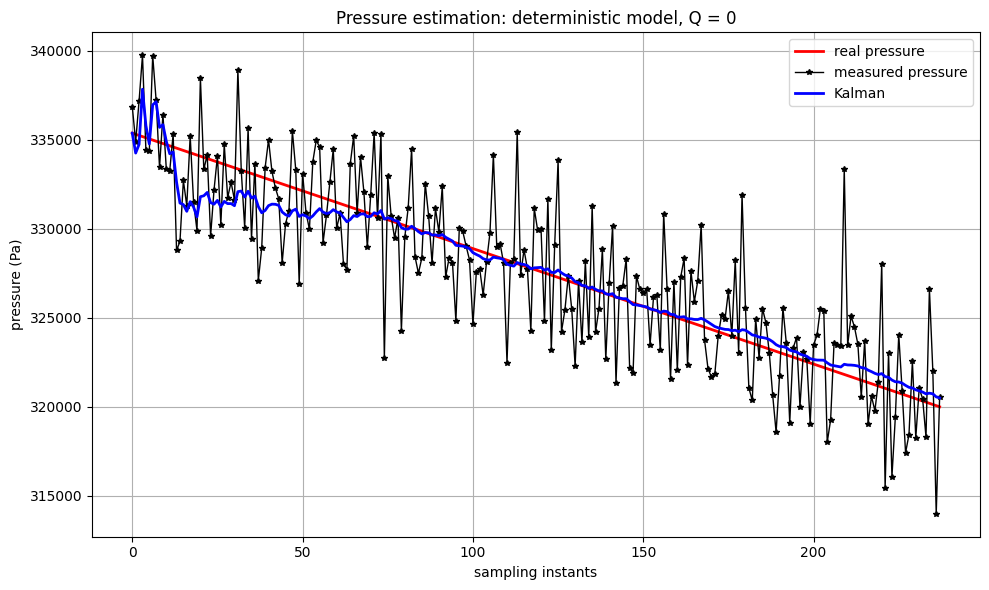

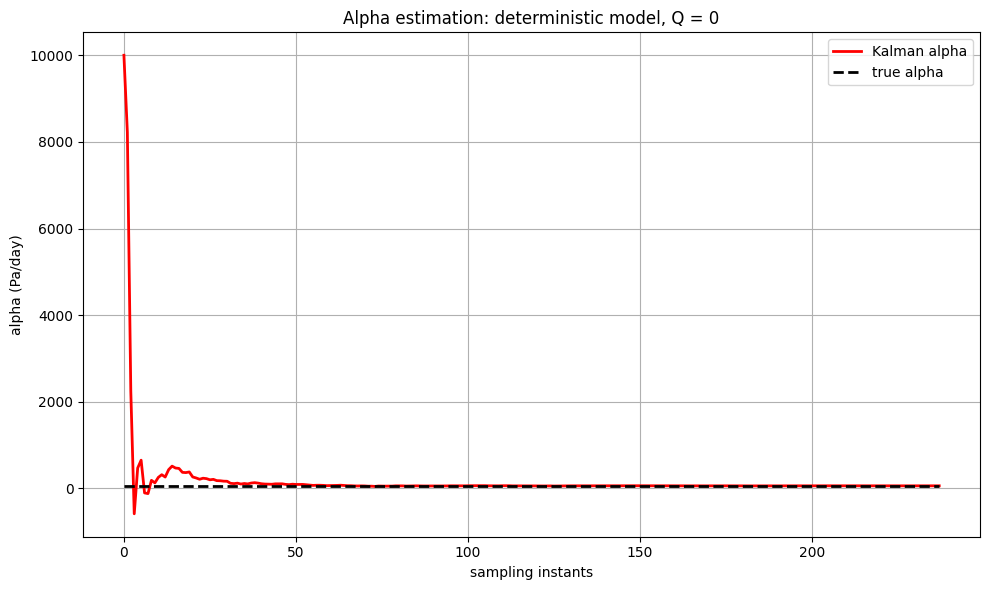

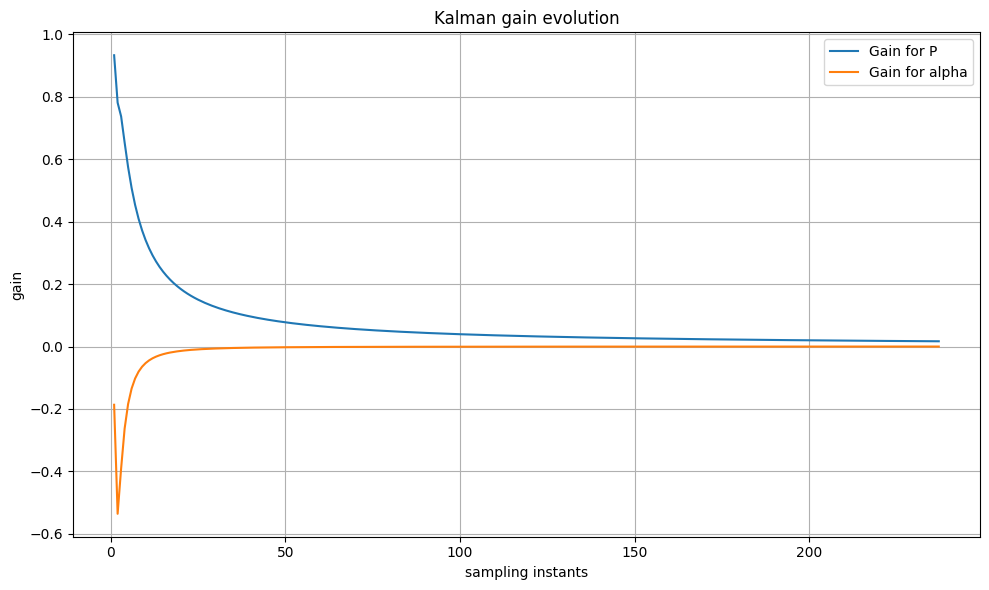

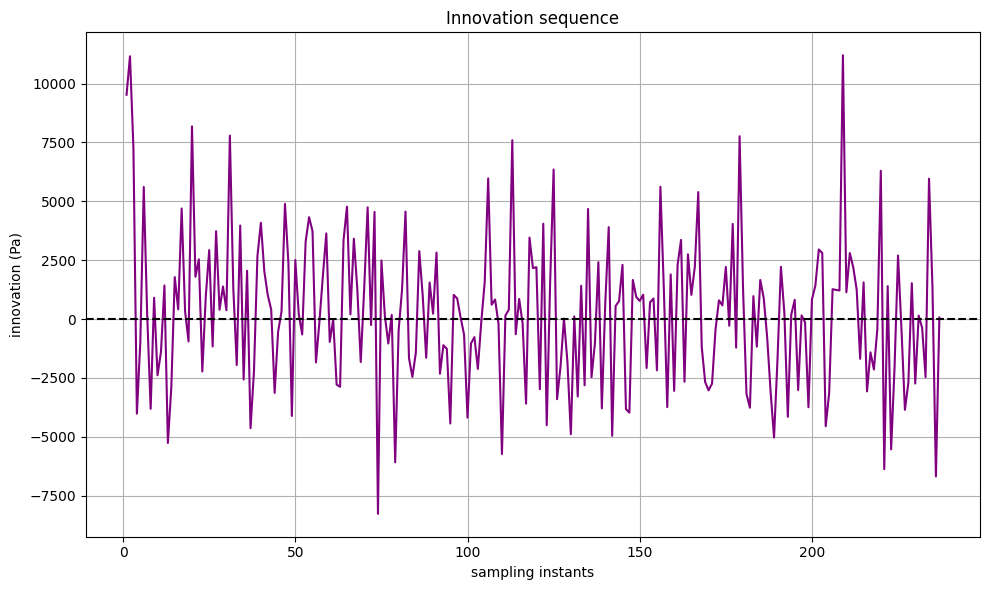

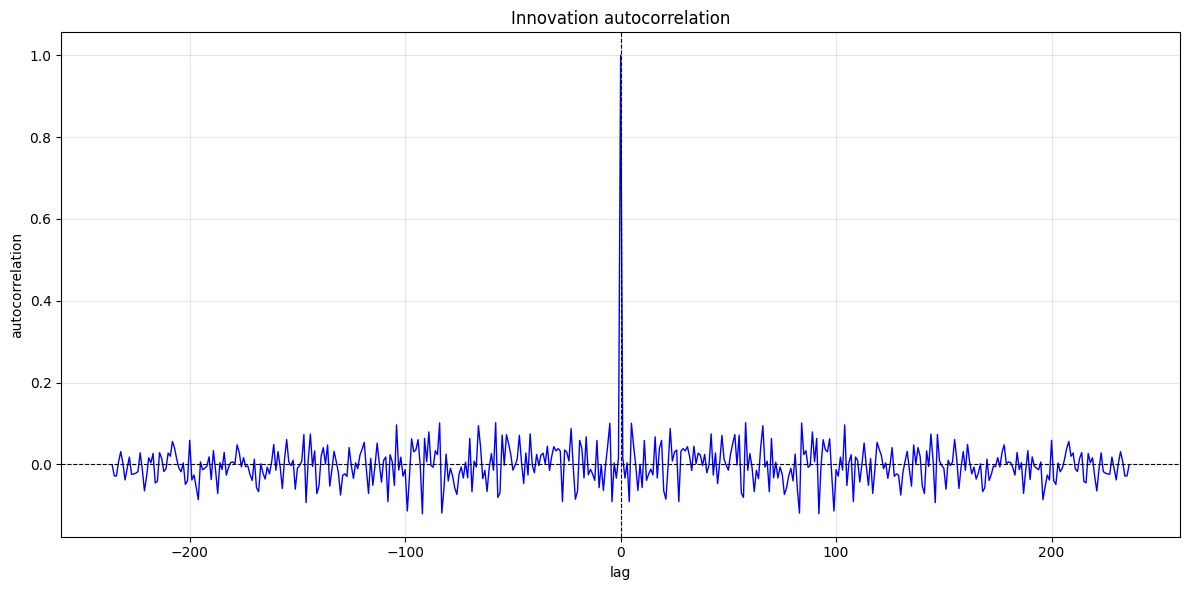

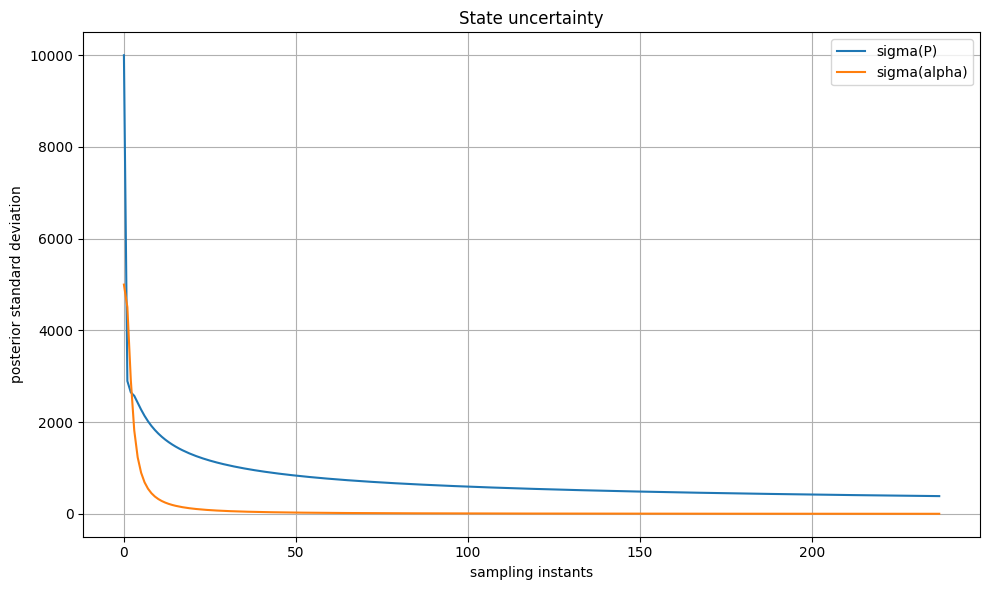

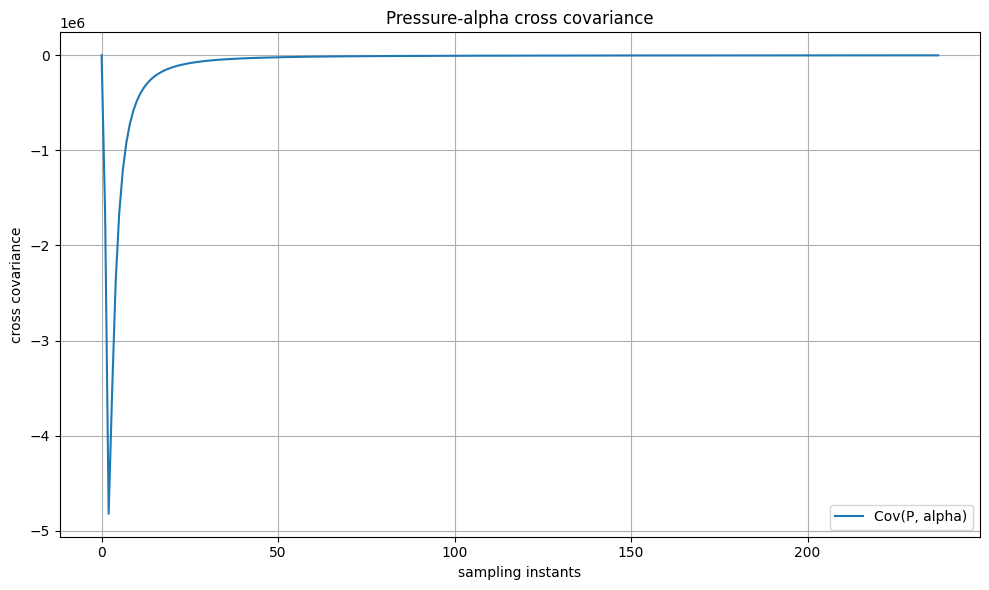

In [1]:
# Q=0

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 0. 基本设置
# ============================================================
plt.close("all")
np.random.seed(42)

BAR_TO_PA = 1e5


# ============================================================
# 1. 读取数据
# ============================================================
csv_path = (
    "/Users/wenbo.wu/Documents/Documents - Wenbo WU/"
    "Thesis/RTE_use_case/RTE_dashboard/RTE/"
    "new_df_AlphaCorrected.csv"
)

df = pd.read_csv(
    csv_path,
    encoding="utf-8-sig"
)

target_csemCur = 5000252545

df_csem = df[df["csemCur"] == target_csemCur].copy()

if df_csem.empty:
    raise ValueError(
        f"没有找到 csemCur = {target_csemCur} 的数据"
    )

row0 = df_csem.iloc[0]

P0_true_bar = float(
    row0["compensatedRelativePressure_mafiltered"]
)

alpha_true_bar_per_day = float(
    row0["alpha"]
)

P0_true = P0_true_bar * BAR_TO_PA
alpha_true = alpha_true_bar_per_day * BAR_TO_PA


# ============================================================
# 2. 确定性真实模型
# ============================================================
Te = 1.0

P_final_bar = 3.2
P_final = P_final_bar * BAR_TO_PA

if alpha_true <= 0:
    raise ValueError(
        f"alpha_true 必须大于 0，当前值为 {alpha_true}"
    )

tf = (P0_true - P_final) / alpha_true

if tf <= 0:
    raise ValueError(
        "tf <= 0，请检查 P0_true、P_final 和 alpha_true"
    )

temps = np.arange(0, tf + Te, Te)
sampling_instants = np.arange(len(temps))

P_true = P0_true - temps * alpha_true


# ============================================================
# 3. 生成含噪压力测量
# ============================================================
# sigma_meas_bar = 0.012
sigma_meas_bar = 0.03
sigma_meas = sigma_meas_bar * BAR_TO_PA

P_measured = (
    P_true
    + sigma_meas * np.random.randn(len(P_true))
)


# ============================================================
# 4. 测量噪声协方差
# ============================================================
R = sigma_meas ** 2


# ============================================================
# 5. 确定性状态模型
# ============================================================
# x = [P, alpha]^T
#
# P(k+1)     = P(k) - Te * alpha(k)
# alpha(k+1) = alpha(k)
#
# Q = 0 表示没有过程噪声
A = np.array([
    [1.0, -Te],
    [0.0,  1.0]
])

H = np.array([
    [1.0, 0.0]
])

Q = np.zeros((2, 2))


# ============================================================
# 6. 初始状态
# ============================================================
# 不要让 alpha0 的不确定度过小。
#
# 这里故意设置 alpha0 为一个可能有偏差的值，
# 用于验证 alpha 是否能够从压力测量中估计出来。
alpha0_bar_per_day = 0.10
alpha0 = alpha0_bar_per_day * BAR_TO_PA


# 初始压力标准差
# 0.1 bar = 10000 Pa
sigma_P0 = 0.10 * BAR_TO_PA

# 初始 alpha 标准差
# 0.05 bar/day = 5000 Pa/day
sigma_alpha0 = 0.05 * BAR_TO_PA


# 允许 P 和 alpha 具有初始相关性
# 如果没有任何先验相关信息，可以先设置为 0。
rho_P_alpha = 0.0

cov_P_alpha = (
    rho_P_alpha
    * sigma_P0
    * sigma_alpha0
)

Sigma0 = np.array([
    [sigma_P0 ** 2, cov_P_alpha],
    [cov_P_alpha, sigma_alpha0 ** 2]
])


# ============================================================
# 7. 数值稳定的 Kalman filter
# ============================================================
def run_kalman_filter(
    measurements,
    A,
    H,
    Q,
    R,
    x0,
    Sigma0
):
    """
    确定性状态模型的 Kalman filter。

    状态：
        x = [P, alpha]^T

    过程模型：
        x(k+1) = A x(k) + w(k)

    这里：
        Q = 0

    观测模型：
        y(k) = H x(k) + v(k)
    """

    measurements = np.asarray(
        measurements,
        dtype=float
    )

    n_samples = len(measurements)
    state_dim = len(x0)

    states = np.zeros(
        (state_dim, n_samples)
    )

    gains = np.zeros(
        (state_dim, n_samples - 1)
    )

    innovations = np.zeros(
        n_samples - 1
    )

    covariance_history = np.zeros(
        (n_samples, state_dim, state_dim)
    )

    x_posteriori = np.asarray(
        x0,
        dtype=float
    ).reshape(-1, 1)

    Sigma_posteriori = np.asarray(
        Sigma0,
        dtype=float
    ).copy()

    states[:, 0] = x_posteriori[:, 0]
    covariance_history[0] = Sigma_posteriori

    identity = np.eye(state_dim)

    for k in range(n_samples - 1):

        # ----------------------------------------------------
        # Prediction
        # ----------------------------------------------------
        x_priori = A @ x_posteriori

        Sigma_priori = (
            A
            @ Sigma_posteriori
            @ A.T
            + Q
        )

        # 强制对称化，避免浮点误差破坏对称性
        Sigma_priori = (
            Sigma_priori
            + Sigma_priori.T
        ) / 2.0

        # ----------------------------------------------------
        # Innovation
        # ----------------------------------------------------
        innovation = np.array([
            [measurements[k + 1]]
        ]) - H @ x_priori

        S = (
            H
            @ Sigma_priori
            @ H.T
            + np.array([[R]])
        )

        # 不使用 inv，直接解线性方程
        K = np.linalg.solve(
            S,
            H @ Sigma_priori
        ).T

        # ----------------------------------------------------
        # Update state
        # ----------------------------------------------------
        x_posteriori = (
            x_priori
            + K @ innovation
        )

        # ----------------------------------------------------
        # Joseph covariance update
        # 保留完整协方差矩阵，包括非对角项
        # ----------------------------------------------------
        I_KH = identity - K @ H

        Sigma_posteriori = (
            I_KH
            @ Sigma_priori
            @ I_KH.T
            + K
            @ np.array([[R]])
            @ K.T
        )

        # 只做对称化，不清零非对角项
        Sigma_posteriori = (
            Sigma_posteriori
            + Sigma_posteriori.T
        ) / 2.0

        # 防止极小的负特征值来自浮点误差
        eigenvalues, eigenvectors = np.linalg.eigh(
            Sigma_posteriori
        )

        eigenvalues = np.maximum(
            eigenvalues,
            0.0
        )

        Sigma_posteriori = (
            eigenvectors
            @ np.diag(eigenvalues)
            @ eigenvectors.T
        )

        # ----------------------------------------------------
        # 保存
        # ----------------------------------------------------
        states[:, k + 1] = x_posteriori[:, 0]
        gains[:, k] = K[:, 0]
        innovations[k] = innovation[0, 0]
        covariance_history[k + 1] = Sigma_posteriori

    return (
        states,
        gains,
        innovations,
        covariance_history
    )


# ============================================================
# 8. 运行 Kalman filter
# ============================================================
x0 = np.array([
    P0_true,
    alpha0
])

print("\n========== Model settings ==========")
print(f"P0_true = {P0_true:.6f} Pa")
print(f"alpha_true = {alpha_true:.6f} Pa/day")
print(f"alpha0 = {alpha0:.6f} Pa/day")
print(f"sigma_meas = {sigma_meas:.6f} Pa")
print(f"R = {R:.6e} Pa^2")
print("Q =")
print(Q)

print("\n========== Initial covariance ==========")
print(Sigma0)

(
    states,
    gains,
    innovations,
    covariance_history
) = run_kalman_filter(
    measurements=P_measured,
    A=A,
    H=H,
    Q=Q,
    R=R,
    x0=x0,
    Sigma0=Sigma0
)

P_Kalman = states[0, :]
alpha_Kalman = states[1, :]


# ============================================================
# 9. 诊断输出
# ============================================================
print("\n========== Filter results ==========")
print(
    f"Initial alpha estimate = "
    f"{alpha_Kalman[0]:.6f} Pa/day"
)

print(
    f"Final alpha estimate = "
    f"{alpha_Kalman[-1]:.6f} Pa/day"
)

print(
    f"True alpha = "
    f"{alpha_true:.6f} Pa/day"
)

print(
    f"Final alpha error = "
    f"{alpha_Kalman[-1] - alpha_true:.6f} Pa/day"
)

print("\nFinal Kalman gain:")
print(gains[:, -1])

print("\nFinal covariance:")
print(covariance_history[-1])


# ============================================================
# 10. 计算误差指标
# ============================================================
pressure_rmse = np.sqrt(
    np.mean(
        (P_Kalman - P_true) ** 2
    )
)

alpha_rmse = np.sqrt(
    np.mean(
        (alpha_Kalman - alpha_true) ** 2
    )
)

print("\n========== RMSE ==========")
print(f"Pressure RMSE = {pressure_rmse:.6f} Pa")
print(f"Alpha RMSE = {alpha_rmse:.6f} Pa/day")


# ============================================================
# 11. 压力估计图
# ============================================================
plt.figure(figsize=(10, 6))

plt.plot(
    sampling_instants,
    P_true,
    "r",
    linewidth=2,
    label="real pressure"
)

plt.plot(
    sampling_instants,
    P_measured,
    "*-k",
    linewidth=1,
    markersize=4,
    label="measured pressure"
)

plt.plot(
    sampling_instants,
    P_Kalman,
    "b",
    linewidth=2,
    label="Kalman"
)

plt.xlabel("sampling instants")
plt.ylabel("pressure (Pa)")
plt.title(
    "Pressure estimation: deterministic model, Q = 0"
)
plt.grid(True)
plt.legend()
plt.tight_layout()


# ============================================================
# 12. Alpha 估计图
# ============================================================
plt.figure(figsize=(10, 6))

plt.plot(
    sampling_instants,
    alpha_Kalman,
    "r",
    linewidth=2,
    label="Kalman alpha"
)

plt.plot(
    sampling_instants,
    alpha_true * np.ones_like(sampling_instants),
    "k--",
    linewidth=2,
    label="true alpha"
)

plt.xlabel("sampling instants")
plt.ylabel("alpha (Pa/day)")
plt.title(
    "Alpha estimation: deterministic model, Q = 0"
)
plt.grid(True)
plt.legend()
plt.tight_layout()


# ============================================================
# 13. Kalman gain
# ============================================================
plt.figure(figsize=(10, 6))

plt.plot(
    np.arange(1, len(sampling_instants)),
    gains[0, :],
    label="Gain for P"
)

plt.plot(
    np.arange(1, len(sampling_instants)),
    gains[1, :],
    label="Gain for alpha"
)

plt.xlabel("sampling instants")
plt.ylabel("gain")
plt.title("Kalman gain evolution")
plt.grid(True)
plt.legend()
plt.tight_layout()


# ============================================================
# 14. Innovation
# ============================================================
plt.figure(figsize=(10, 6))

plt.plot(
    np.arange(1, len(sampling_instants)),
    innovations,
    color="purple",
    linewidth=1.5
)

plt.axhline(
    0,
    color="black",
    linestyle="--"
)

plt.xlabel("sampling instants")
plt.ylabel("innovation (Pa)")
plt.title("Innovation sequence")
plt.grid(True)
plt.tight_layout()


# ============================================================
# 15. Innovation autocorrelation
# ============================================================
x = innovations - np.mean(innovations)

if len(x) > 1 and np.var(x) > 0:

    acf_full = np.correlate(
        x,
        x,
        mode="full"
    )

    acf_full = (
        acf_full
        / acf_full[len(x) - 1]
    )

    lags = np.arange(
        -(len(x) - 1),
        len(x)
    )

    max_lag = min(
        2000,
        len(x) - 1
    )

    mask = (
        (lags >= -max_lag)
        & (lags <= max_lag)
    )

    plt.figure(figsize=(12, 6))

    plt.plot(
        lags[mask],
        acf_full[mask],
        color="blue",
        linewidth=1
    )

    plt.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=0.8
    )

    plt.axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=0.8
    )

    plt.xlabel("lag")
    plt.ylabel("autocorrelation")
    plt.title("Innovation autocorrelation")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()


# ============================================================
# 16. 协方差变化
# ============================================================
sigma_P_history = np.sqrt(
    np.maximum(
        covariance_history[:, 0, 0],
        0.0
    )
)

sigma_alpha_history = np.sqrt(
    np.maximum(
        covariance_history[:, 1, 1],
        0.0
    )
)

cross_covariance_history = (
    covariance_history[:, 0, 1]
)

plt.figure(figsize=(10, 6))

plt.plot(
    sampling_instants,
    sigma_P_history,
    label="sigma(P)"
)

plt.plot(
    sampling_instants,
    sigma_alpha_history,
    label="sigma(alpha)"
)

plt.xlabel("sampling instants")
plt.ylabel("posterior standard deviation")
plt.title("State uncertainty")
plt.grid(True)
plt.legend()
plt.tight_layout()


plt.figure(figsize=(10, 6))

plt.plot(
    sampling_instants,
    cross_covariance_history,
    label="Cov(P, alpha)"
)

plt.xlabel("sampling instants")
plt.ylabel("cross covariance")
plt.title("Pressure-alpha cross covariance")
plt.grid(True)
plt.legend()
plt.tight_layout()


plt.show()

P0_true = 333676.17 Pa (3.3368 bar)
alpha_true = 204.98 Pa/day (0.0020 bar/day)

开始 R/Q 参数扫描

固定 R = 1.44e+06 Pa^2 (sigma_meas = 1200.00 Pa)
扫描 15 x 15 = 225 个 Q 配置

最优配置

最小 alpha RMSE:
  sigma_P_process = 719.69 Pa
  sigma_alpha_process = 100.00 Pa/day
  alpha RMSE = 1530.56 Pa/day
  pressure RMSE = 710.00 Pa

最小 pressure RMSE:
  sigma_P_process = 100.00 Pa
  sigma_alpha_process = 100.00 Pa/day
  pressure RMSE = 624.36 Pa
  alpha RMSE = 1531.13 Pa/day

综合最优:
  sigma_P_process = 100.00 Pa
  sigma_alpha_process = 100.00 Pa/day
  alpha RMSE = 1531.13 Pa/day
  pressure RMSE = 624.36 Pa

最优 Q 矩阵:
[[517947.46792312      0.        ]
 [     0.          10000.        ]]

Q/R 比例 (trace(Q)/R): 3.6663e-01

所有扫描结果已保存到：kalman_tuning_results.csv
最优参数已保存到：optimal_kalman_params.csv


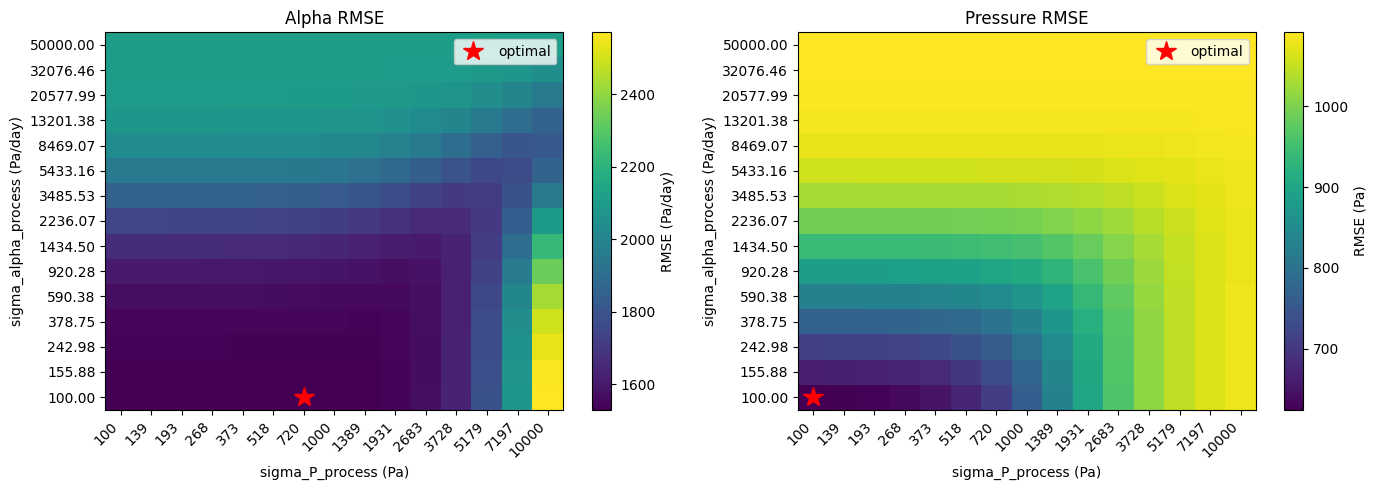

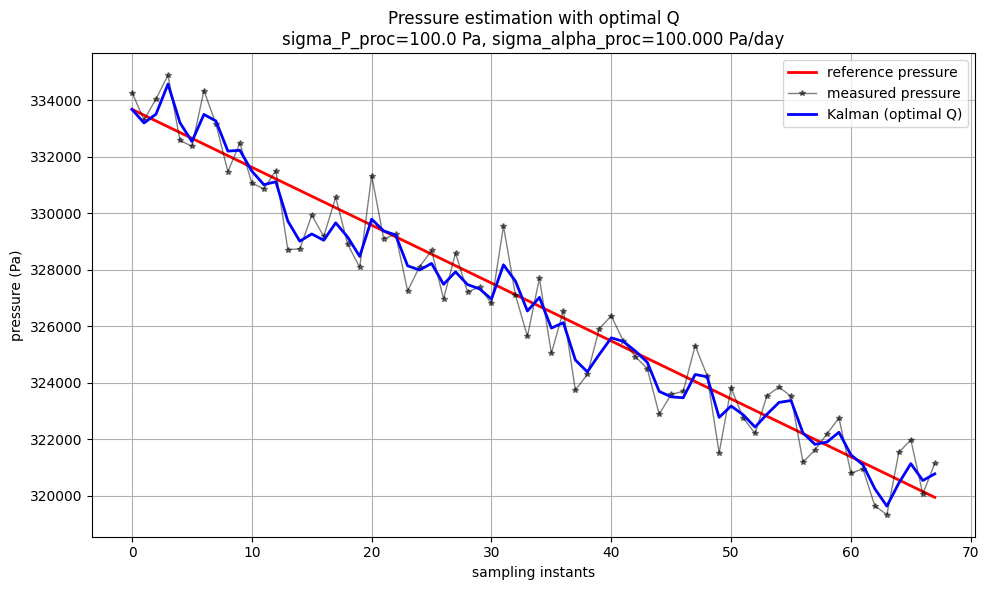

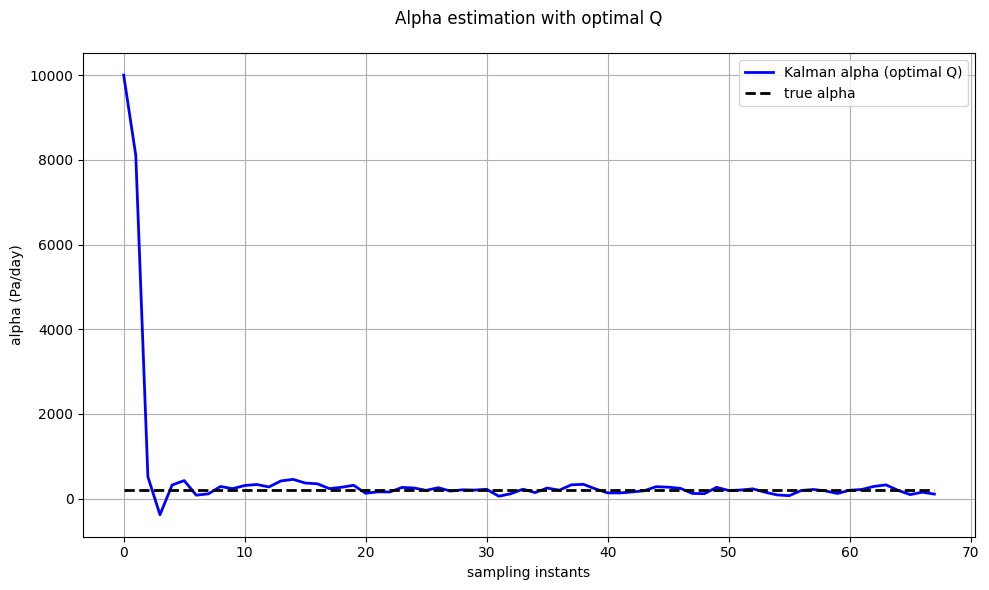

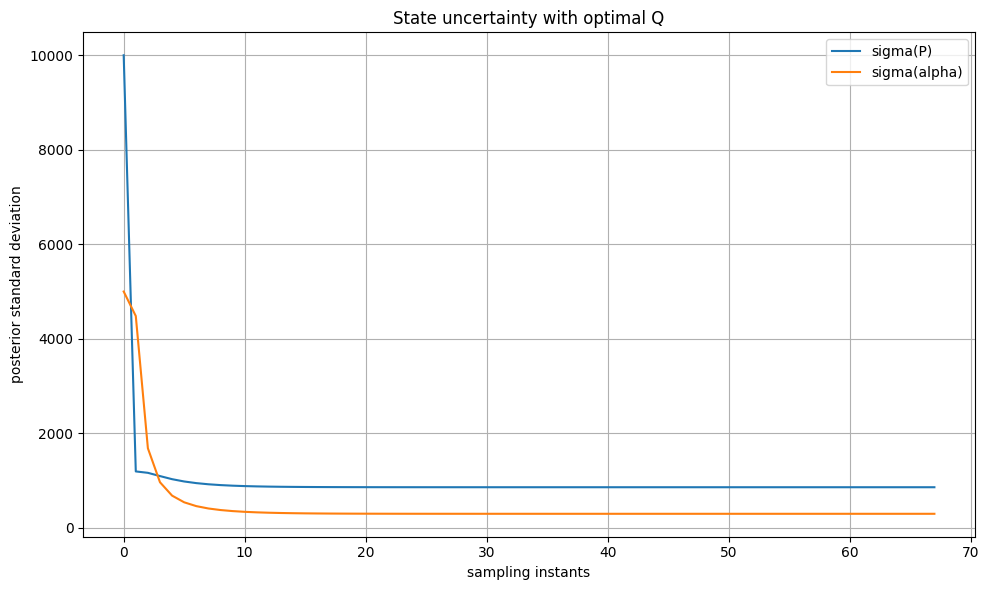


参数扫描完成!


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product


# ============================================================
# 0. 基本设置
# ============================================================
plt.close("all")
np.random.seed(42)


BAR_TO_PA = 1e5


# ============================================================
# 1. 读取数据
# ============================================================
csv_path = (
    "/Users/wenbo.wu/Documents/Documents - Wenbo WU/"
    "Thesis/RTE_use_case/RTE_dashboard/RTE/"
    "new_df_AlphaCorrected.csv"
)


df = pd.read_csv(
    csv_path,
    encoding="utf-8-sig"
)


# target_csemCur = 5000252545
target_csemCur =5001319493


df_csem = df[df["csemCur"] == target_csemCur].copy()


if df_csem.empty:
    raise ValueError(
        f"没有找到 csemCur = {target_csemCur} 的数据"
    )


row0 = df_csem.iloc[0]


P0_true_bar = float(
    row0["compensatedRelativePressure_mafiltered"]
)


alpha_true_bar_per_day = float(
    row0["alpha"]
)


P0_true = P0_true_bar * BAR_TO_PA
alpha_true = alpha_true_bar_per_day * BAR_TO_PA


print(f"P0_true = {P0_true:.2f} Pa ({P0_true_bar:.4f} bar)")
print(f"alpha_true = {alpha_true:.2f} Pa/day ({alpha_true_bar_per_day:.4f} bar/day)")


# ============================================================
# 2. 确定性真实模型
# ============================================================
Te = 1.0  # 采样间隔 (天)


P_final_bar = 3.2
P_final = P_final_bar * BAR_TO_PA


if alpha_true <= 0:
    raise ValueError(
        f"alpha_true 必须大于 0，当前值为 {alpha_true}"
    )


tf = (P0_true - P_final) / alpha_true


if tf <= 0:
    raise ValueError(
        "tf <= 0，请检查 P0_true、P_final 和 alpha_true"
    )


temps = np.arange(0, tf + Te, Te)
sampling_instants = np.arange(len(temps))


P_true = P0_true - temps * alpha_true


# ============================================================
# 3. 生成含噪压力测量
# ============================================================
sigma_meas_bar = 0.012
sigma_meas = sigma_meas_bar * BAR_TO_PA


P_measured = (
    P_true
    + sigma_meas * np.random.randn(len(P_true))
)


# ============================================================
# 4. 测量噪声协方差 R
# ============================================================
R = sigma_meas ** 2


# ============================================================
# 5. 状态模型 (带过程噪声)
# ============================================================
A = np.array([
    [1.0, -Te],
    [0.0,  1.0]
])


H = np.array([
    [1.0, 0.0]
])


# ============================================================
# 6. 初始状态
# ============================================================
alpha0_bar_per_day = 0.10
alpha0 = alpha0_bar_per_day * BAR_TO_PA


sigma_P0 = 0.10 * BAR_TO_PA
sigma_alpha0 = 0.05 * BAR_TO_PA
rho_P_alpha = 0.0


cov_P_alpha = rho_P_alpha * sigma_P0 * sigma_alpha0


Sigma0 = np.array([
    [sigma_P0 ** 2, cov_P_alpha],
    [cov_P_alpha, sigma_alpha0 ** 2]
])


# ============================================================
# 7. Kalman filter
# ============================================================
def run_kalman_filter(measurements, A, H, Q, R, x0, Sigma0):
    """带过程噪声的 Kalman filter"""
    
    measurements = np.asarray(measurements, dtype=float)
    n_samples = len(measurements)
    state_dim = len(x0)
    
    states = np.zeros((state_dim, n_samples))
    gains = np.zeros((state_dim, n_samples - 1))
    innovations = np.zeros(n_samples - 1)
    covariance_history = np.zeros((n_samples, state_dim, state_dim))
    
    x_posteriori = np.asarray(x0, dtype=float).reshape(-1, 1)
    Sigma_posteriori = np.asarray(Sigma0, dtype=float).copy()
    
    states[:, 0] = x_posteriori[:, 0]
    covariance_history[0] = Sigma_posteriori
    
    identity = np.eye(state_dim)
    
    for k in range(n_samples - 1):
        # Prediction
        x_priori = A @ x_posteriori
        Sigma_priori = A @ Sigma_posteriori @ A.T + Q
        Sigma_priori = (Sigma_priori + Sigma_priori.T) / 2.0
        
        # Innovation
        innovation = np.array([[measurements[k + 1]]]) - H @ x_priori
        S = H @ Sigma_priori @ H.T + np.array([[R]])
        K = np.linalg.solve(S, H @ Sigma_priori).T
        
        # Update
        x_posteriori = x_priori + K @ innovation
        I_KH = identity - K @ H
        Sigma_posteriori = (
            I_KH @ Sigma_priori @ I_KH.T 
            + K @ np.array([[R]]) @ K.T
        )
        Sigma_posteriori = (Sigma_posteriori + Sigma_posteriori.T) / 2.0
        
        # 防止负特征值
        eigenvalues, eigenvectors = np.linalg.eigh(Sigma_posteriori)
        eigenvalues = np.maximum(eigenvalues, 0.0)
        Sigma_posteriori = eigenvectors @ np.diag(eigenvalues) @ eigenvectors.T
        
        # 保存
        states[:, k + 1] = x_posteriori[:, 0]
        gains[:, k] = K[:, 0]
        innovations[k] = innovation[0, 0]
        covariance_history[k + 1] = Sigma_posteriori
    
    return states, gains, innovations, covariance_history


# ============================================================
# 8. Q 矩阵构建
# ============================================================
def build_Q_matrix(sigma_P_process, sigma_alpha_process, rho=0.0):
    cov_P_alpha_process = rho * sigma_P_process * sigma_alpha_process
    Q = np.array([
        [sigma_P_process ** 2, cov_P_alpha_process],
        [cov_P_alpha_process, sigma_alpha_process ** 2]
    ])
    return Q


# ============================================================
# 9. 性能指标
# ============================================================
def compute_metrics(P_Kalman, alpha_Kalman, P_true, alpha_true):
    return {
        'pressure_rmse': np.sqrt(np.mean((P_Kalman - P_true) ** 2)),
        'alpha_rmse': np.sqrt(np.mean((alpha_Kalman - alpha_true) ** 2)),
        'pressure_mae': np.mean(np.abs(P_Kalman - P_true)),
        'alpha_mae': np.mean(np.abs(alpha_Kalman - alpha_true)),
        'alpha_final_error': alpha_Kalman[-1] - alpha_true
    }


# ============================================================
# 10. R/Q 参数扫描
# ============================================================
print("\n" + "=" * 60)
print("开始 R/Q 参数扫描")
print("=" * 60)


R_fixed = R
sigma_meas_fixed = np.sqrt(R_fixed)


# Q 扫描范围
sigma_P_process_range = np.logspace(
    np.log10(100),
    np.log10(10000),
    num=15
)

sigma_alpha_process_range = np.logspace(
    np.log10(0.001 * BAR_TO_PA),
    np.log10(0.5 * BAR_TO_PA),
    num=15
)


results = []
x0 = np.array([P0_true, alpha0])


print(f"\n固定 R = {R_fixed:.2e} Pa^2 (sigma_meas = {sigma_meas_fixed:.2f} Pa)")
print(f"扫描 {len(sigma_P_process_range)} x {len(sigma_alpha_process_range)} = "
      f"{len(sigma_P_process_range) * len(sigma_alpha_process_range)} 个 Q 配置")


for i, sigma_P_proc in enumerate(sigma_P_process_range):
    for j, sigma_alpha_proc in enumerate(sigma_alpha_process_range):
        Q = build_Q_matrix(sigma_P_proc, sigma_alpha_proc, rho=0.0)
        
        states, gains, innovations, cov_hist = run_kalman_filter(
            measurements=P_measured,
            A=A, H=H, Q=Q, R=R_fixed,
            x0=x0, Sigma0=Sigma0
        )
        
        P_Kalman = states[0, :]
        alpha_Kalman = states[1, :]
        
        metrics = compute_metrics(P_Kalman, alpha_Kalman, P_true, alpha_true)
        
        results.append({
            'sigma_P_process': sigma_P_proc,
            'sigma_alpha_process': sigma_alpha_proc,
            'Q': Q.copy(),
            'P_Kalman': P_Kalman,
            'alpha_Kalman': alpha_Kalman,
            'covariance_history': cov_hist,
            **metrics
        })


results_df = pd.DataFrame([
    {
        'sigma_P_process': r['sigma_P_process'],
        'sigma_alpha_process': r['sigma_alpha_process'],
        'pressure_rmse': r['pressure_rmse'],
        'alpha_rmse': r['alpha_rmse'],
        'pressure_mae': r['pressure_mae'],
        'alpha_mae': r['alpha_mae'],
        'alpha_final_error': r['alpha_final_error']
    }
    for r in results
])


# ============================================================
# 11. 最优配置
# ============================================================
print("\n" + "=" * 60)
print("最优配置")
print("=" * 60)


best_by_alpha_rmse = results_df.loc[results_df['alpha_rmse'].idxmin()]
print(f"\n最小 alpha RMSE:")
print(f"  sigma_P_process = {best_by_alpha_rmse['sigma_P_process']:.2f} Pa")
print(f"  sigma_alpha_process = {best_by_alpha_rmse['sigma_alpha_process']:.2f} Pa/day")
print(f"  alpha RMSE = {best_by_alpha_rmse['alpha_rmse']:.2f} Pa/day")
print(f"  pressure RMSE = {best_by_alpha_rmse['pressure_rmse']:.2f} Pa")


best_by_pressure_rmse = results_df.loc[results_df['pressure_rmse'].idxmin()]
print(f"\n最小 pressure RMSE:")
print(f"  sigma_P_process = {best_by_pressure_rmse['sigma_P_process']:.2f} Pa")
print(f"  sigma_alpha_process = {best_by_pressure_rmse['sigma_alpha_process']:.2f} Pa/day")
print(f"  pressure RMSE = {best_by_pressure_rmse['pressure_rmse']:.2f} Pa")
print(f"  alpha RMSE = {best_by_pressure_rmse['alpha_rmse']:.2f} Pa/day")


results_df['combined_score'] = (
    results_df['alpha_rmse'] / results_df['alpha_rmse'].min()
    + results_df['pressure_rmse'] / results_df['pressure_rmse'].min()
)

best_combined = results_df.loc[results_df['combined_score'].idxmin()]
print(f"\n综合最优:")
print(f"  sigma_P_process = {best_combined['sigma_P_process']:.2f} Pa")
print(f"  sigma_alpha_process = {best_combined['sigma_alpha_process']:.2f} Pa/day")
print(f"  alpha RMSE = {best_combined['alpha_rmse']:.2f} Pa/day")
print(f"  pressure RMSE = {best_combined['pressure_rmse']:.2f} Pa")


# ============================================================
# 12. 可视化
# ============================================================

# 12.1 RMSE 热力图
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


# Alpha RMSE
pivot_alpha = results_df.pivot(
    index='sigma_alpha_process',
    columns='sigma_P_process',
    values='alpha_rmse'
)

im1 = axes[0].imshow(pivot_alpha.values, cmap='viridis', aspect='auto', origin='lower')
axes[0].set_xlabel('sigma_P_process (Pa)')
axes[0].set_ylabel('sigma_alpha_process (Pa/day)')
axes[0].set_title('Alpha RMSE')
axes[0].set_xticks(np.arange(len(pivot_alpha.columns)))
axes[0].set_xticklabels([f'{x:.0f}' for x in pivot_alpha.columns], rotation=45, ha='right')
axes[0].set_yticks(np.arange(len(pivot_alpha.index)))
axes[0].set_yticklabels([f'{x:.2f}' for x in pivot_alpha.index])
plt.colorbar(im1, ax=axes[0], label='RMSE (Pa/day)')

# 标记最优位置 (修复)
min_alpha_idx = np.unravel_index(np.argmin(pivot_alpha.values), pivot_alpha.values.shape)
axes[0].plot(min_alpha_idx[1], min_alpha_idx[0], 'r*', markersize=15, label='optimal')
axes[0].legend()


# Pressure RMSE
pivot_pressure = results_df.pivot(
    index='sigma_alpha_process',
    columns='sigma_P_process',
    values='pressure_rmse'
)

im2 = axes[1].imshow(pivot_pressure.values, cmap='viridis', aspect='auto', origin='lower')
axes[1].set_xlabel('sigma_P_process (Pa)')
axes[1].set_ylabel('sigma_alpha_process (Pa/day)')
axes[1].set_title('Pressure RMSE')
axes[1].set_xticks(np.arange(len(pivot_pressure.columns)))
axes[1].set_xticklabels([f'{x:.0f}' for x in pivot_pressure.columns], rotation=45, ha='right')
axes[1].set_yticks(np.arange(len(pivot_pressure.index)))
axes[1].set_yticklabels([f'{x:.2f}' for x in pivot_pressure.index])
plt.colorbar(im2, ax=axes[1], label='RMSE (Pa)')

# 标记最优位置 (修复)
min_pressure_idx = np.unravel_index(np.argmin(pivot_pressure.values), pivot_pressure.values.shape)
axes[1].plot(min_pressure_idx[1], min_pressure_idx[0], 'r*', markersize=15, label='optimal')
axes[1].legend()

plt.tight_layout()


# 12.2 最优配置结果
best_result = results[results_df['alpha_rmse'].idxmin()]
Q_best = best_result['Q']
P_Kalman_best = best_result['P_Kalman']
alpha_Kalman_best = best_result['alpha_Kalman']
cov_best = best_result['covariance_history']


print(f"\n最优 Q 矩阵:")
print(Q_best)


# 压力估计
plt.figure(figsize=(10, 6))
plt.plot(sampling_instants, P_true, "r", linewidth=2, label="reference pressure")
plt.plot(sampling_instants, P_measured, "*-k", linewidth=1, markersize=4, 
         label="measured pressure", alpha=0.5)
plt.plot(sampling_instants, P_Kalman_best, "b", linewidth=2, label="Kalman (optimal Q)")
plt.xlabel("sampling instants")
plt.ylabel("pressure (Pa)")
plt.title(f"Pressure estimation with optimal Q\n"
          f"sigma_P_proc={best_combined['sigma_P_process']:.1f} Pa, "
          f"sigma_alpha_proc={best_combined['sigma_alpha_process']:.3f} Pa/day")
plt.grid(True)
plt.legend()
plt.tight_layout()


# Alpha 估计
plt.figure(figsize=(10, 6))
plt.plot(sampling_instants, alpha_Kalman_best, "b", linewidth=2, label="Kalman alpha (optimal Q)")
plt.plot(sampling_instants, alpha_true * np.ones_like(sampling_instants), "k--", 
         linewidth=2, label="true alpha")
plt.xlabel("sampling instants")
plt.ylabel("alpha (Pa/day)")
plt.title(f"Alpha estimation with optimal Q\n")
plt.grid(True)
plt.legend()
plt.tight_layout()


# 协方差
sigma_P_history = np.sqrt(np.maximum(cov_best[:, 0, 0], 0.0))
sigma_alpha_history = np.sqrt(np.maximum(cov_best[:, 1, 1], 0.0))

plt.figure(figsize=(10, 6))
plt.plot(sampling_instants, sigma_P_history, label="sigma(P)")
plt.plot(sampling_instants, sigma_alpha_history, label="sigma(alpha)")
plt.xlabel("sampling instants")
plt.ylabel("posterior standard deviation")
plt.title("State uncertainty with optimal Q")
plt.grid(True)
plt.legend()
plt.tight_layout()


# 12.3 Q/R 比例
Q_over_R_ratio = np.trace(Q_best) / R_fixed
print(f"\nQ/R 比例 (trace(Q)/R): {Q_over_R_ratio:.4e}")


# ============================================================
# 13. 保存结果
# ============================================================
results_df.to_csv('kalman_tuning_results.csv', index=False)
print(f"\n所有扫描结果已保存到：kalman_tuning_results.csv")


optimal_params = {
    'sigma_P_process_optimal': best_combined['sigma_P_process'],
    'sigma_alpha_process_optimal': best_combined['sigma_alpha_process'],
    'alpha_rmse_optimal': best_combined['alpha_rmse'],
    'pressure_rmse_optimal': best_combined['pressure_rmse'],
    'R_fixed': R_fixed,
    'Q_trace': np.trace(Q_best)
}

pd.DataFrame([optimal_params]).to_csv('optimal_kalman_params.csv', index=False)
print(f"最优参数已保存到：optimal_kalman_params.csv")


plt.show()


print("\n" + "=" * 60)
print("参数扫描完成!")
print("=" * 60)

P0_true = 335363.57 Pa (3.3536 bar)
alpha_true = 64.86 Pa/day (0.0006 bar/day)

开始 R/Q 参数扫描

固定 R = 1.44e+06 Pa^2 (sigma_meas = 1200.00 Pa)
扫描 15 x 15 = 225 个 Q 配置

最优配置

最小 alpha RMSE:
  sigma_P_process = 1000.00 Pa
  sigma_alpha_process = 100.00 Pa/day
  alpha RMSE = 832.04 Pa/day
  pressure RMSE = 756.25 Pa
  alpha final error = 30.72 Pa/day

最小 pressure RMSE:
  sigma_P_process = 100.00 Pa
  sigma_alpha_process = 100.00 Pa/day
  pressure RMSE = 582.48 Pa
  alpha RMSE = 834.41 Pa/day
  pressure final error = -73.43 Pa

综合最优:
  sigma_P_process = 100.00 Pa
  sigma_alpha_process = 100.00 Pa/day
  alpha RMSE = 834.41 Pa/day
  pressure RMSE = 582.48 Pa

最优 Q 矩阵:
[[1000000.       0.]
 [      0.   10000.]]

========== 新增：仅用于绘图的过程噪声轨迹 ==========
sigma_P_process_visual = 50.00 Pa
sigma_alpha_process_visual = 1.00 Pa/day
Q_visual =
[[2.5e+03 0.0e+00]
 [0.0e+00 1.0e+00]]

Q/R 比例 (trace(Q)/R): 7.0139e-01

所有扫描结果已保存到：kalman_tuning_results.csv
最优参数已保存到：optimal_kalman_params.csv


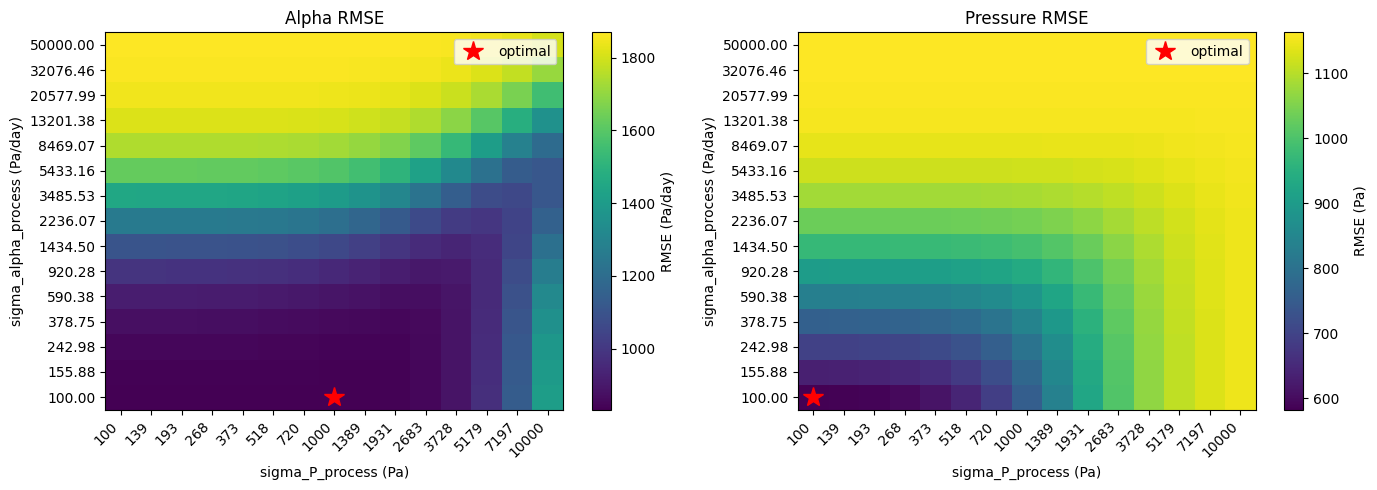

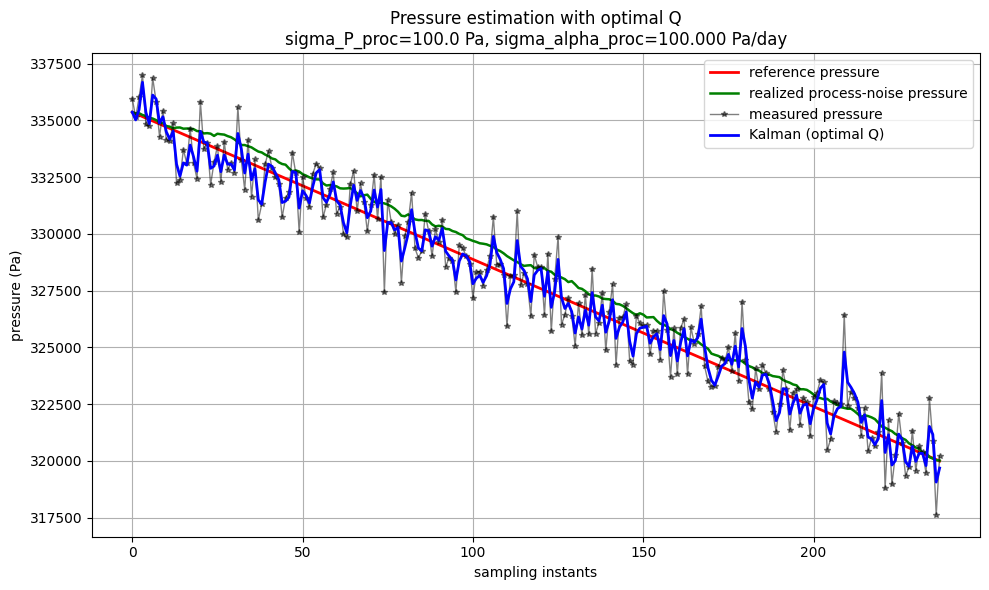

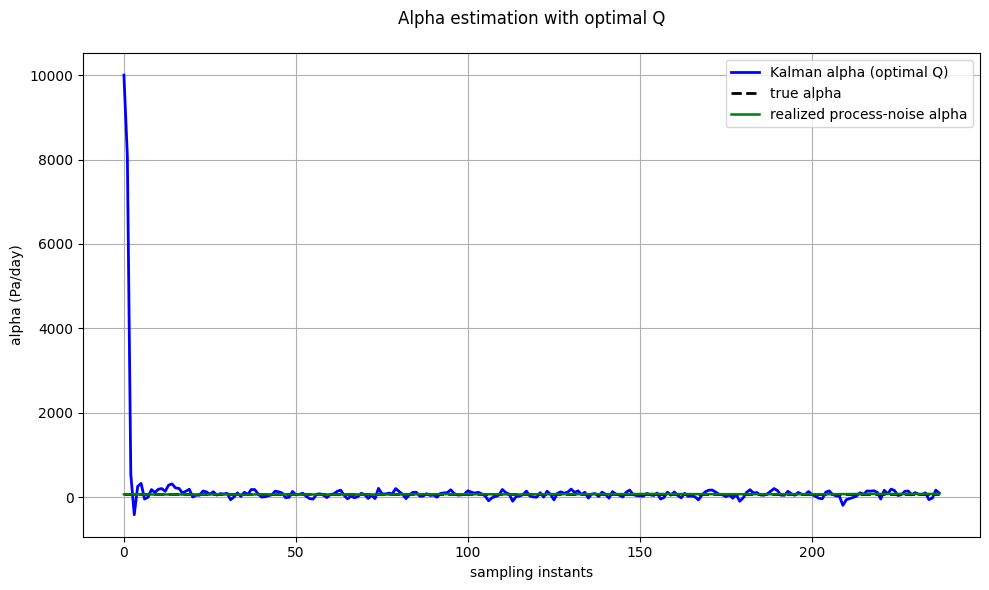

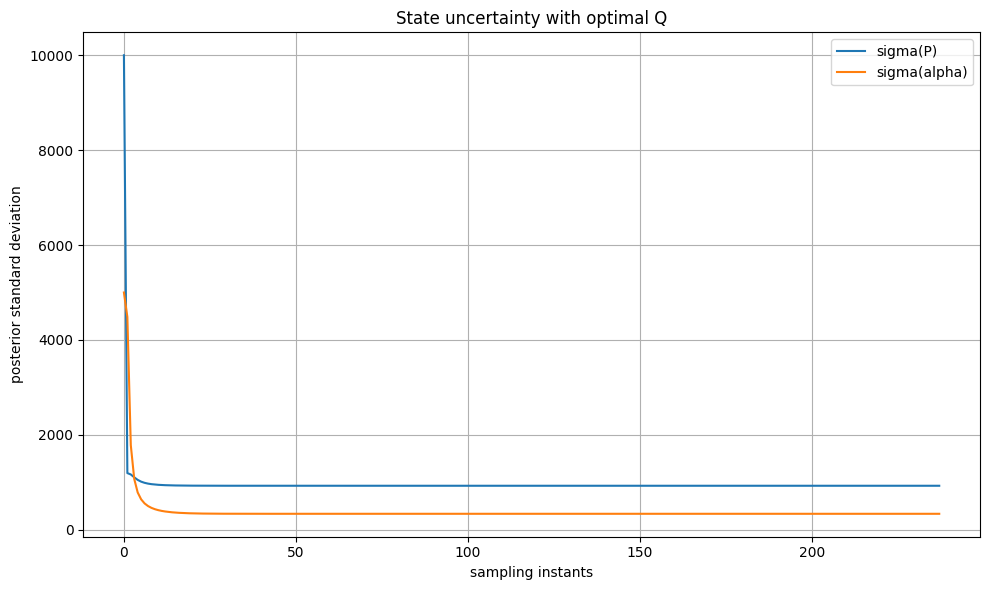

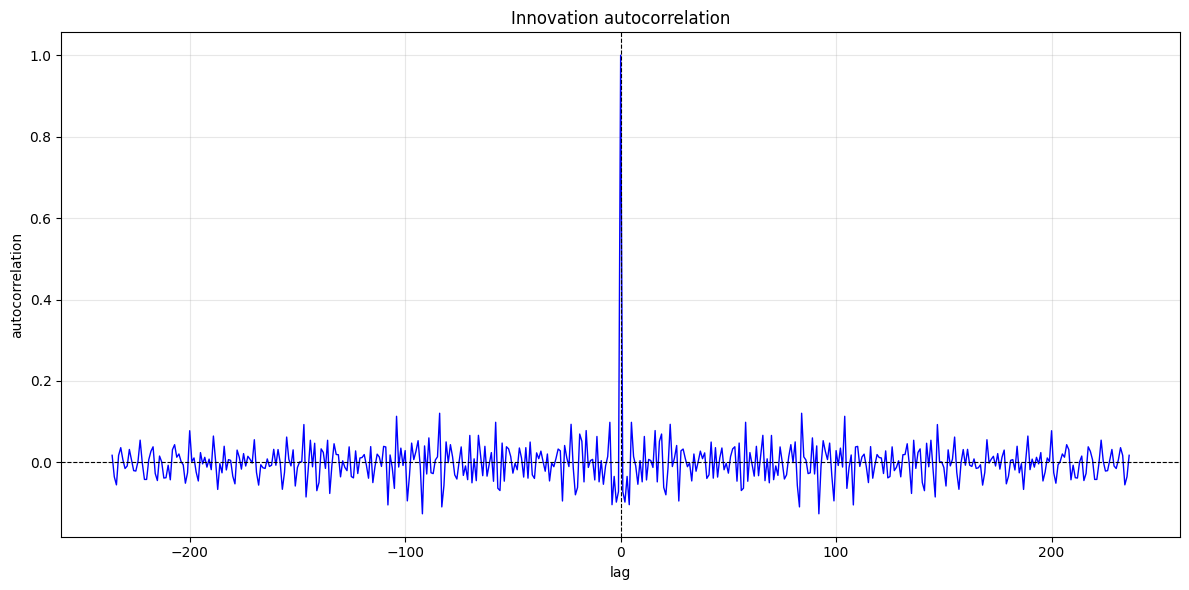


参数扫描完成!


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product


# ============================================================
# 0. 基本设置
# ============================================================
# 重要说明：
# 本代码保留你原有实验的所有计算：
#   - np.random.seed(42)
#   - P_measured 的生成方式
#   - R/Q 网格扫描
#   - best_result 的选择方式（最小 alpha RMSE）
#   - Pressure / Alpha / covariance 图中的原始曲线
#
# 唯一新增：
#   1. 两条“仅用于展示”的绿色过程噪声轨迹；
#   2. innovation autocorrelation 图（全负/正 lag，连续线）。
#
# 绿色过程轨迹不参与：
#   - P_measured 的生成
#   - Kalman filter 输入
#   - Q 扫描
#   - RMSE 计算
# 因而它不会改变你原来黑色测量、蓝色 Kalman 曲线、最优 Q 和结果。
plt.close("all")
np.random.seed(42)

BAR_TO_PA = 1e5


# ============================================================
# 1. 读取数据
# ============================================================
csv_path = (
    "/Users/wenbo.wu/Documents/Documents - Wenbo WU/"
    "Thesis/RTE_use_case/RTE_dashboard/RTE/"
    "new_df_AlphaCorrected.csv"
)


df = pd.read_csv(
    csv_path,
    encoding="utf-8-sig"
)


target_csemCur = 5000252545
# target_csemCur =5001319493

df_csem = df[df["csemCur"] == target_csemCur].copy()


if df_csem.empty:
    raise ValueError(
        f"没有找到 csemCur = {target_csemCur} 的数据"
    )


row0 = df_csem.iloc[0]


P0_true_bar = float(
    row0["compensatedRelativePressure_mafiltered"]
)


alpha_true_bar_per_day = float(
    row0["alpha"]
)


P0_true = P0_true_bar * BAR_TO_PA
alpha_true = alpha_true_bar_per_day * BAR_TO_PA


print(f"P0_true = {P0_true:.2f} Pa ({P0_true_bar:.4f} bar)")
print(
    f"alpha_true = {alpha_true:.2f} Pa/day "
    f"({alpha_true_bar_per_day:.4f} bar/day)"
)


# ============================================================
# 2. 确定性真实模型
# ============================================================
Te = 1.0  # 采样间隔 (天)


P_final_bar = 3.2
P_final = P_final_bar * BAR_TO_PA


if alpha_true <= 0:
    raise ValueError(
        f"alpha_true 必须大于 0，当前值为 {alpha_true}"
    )


tf = (P0_true - P_final) / alpha_true


if tf <= 0:
    raise ValueError(
        "tf <= 0，请检查 P0_true、P_final 和 alpha_true"
    )


temps = np.arange(0, tf + Te, Te)
sampling_instants = np.arange(len(temps))
n_samples = len(temps)


# 这条红线是你原有的 reference pressure，保持不变。
P_true = P0_true - temps * alpha_true


# ============================================================
# 3. 生成含噪压力测量（完全保留原有计算）
# ============================================================
sigma_meas_bar = 0.012
sigma_meas = sigma_meas_bar * BAR_TO_PA


# 不改变这一部分：黑色测量点仍由 P_true 加测量噪声生成。
# 由于此时仍是 np.random.seed(42) 后的第一次随机抽样，
# 它与旧代码中的 P_measured 完全一致。
P_measured = (
    P_true
    + sigma_meas * np.random.randn(len(P_true))
)


# ============================================================
# 4. 测量噪声协方差 R
# ============================================================
R = sigma_meas ** 2


# ============================================================
# 5. 状态模型 (带过程噪声)
# ============================================================
A = np.array([
    [1.0, -Te],
    [0.0, 1.0]
])


H = np.array([
    [1.0, 0.0]
])


# ============================================================
# 6. 初始状态
# ============================================================
alpha0_bar_per_day = 0.10
alpha0 = alpha0_bar_per_day * BAR_TO_PA


sigma_P0 = 0.10 * BAR_TO_PA
sigma_alpha0 = 0.05 * BAR_TO_PA
rho_P_alpha = 0.0


cov_P_alpha = rho_P_alpha * sigma_P0 * sigma_alpha0


Sigma0 = np.array([
    [sigma_P0 ** 2, cov_P_alpha],
    [cov_P_alpha, sigma_alpha0 ** 2]
])


# ============================================================
# 7. Kalman filter（完全保留原有计算逻辑）
# ============================================================
def run_kalman_filter(measurements, A, H, Q, R, x0, Sigma0):
    """带过程噪声的 Kalman filter"""

    measurements = np.asarray(measurements, dtype=float)
    n_samples = len(measurements)
    state_dim = len(x0)

    states = np.zeros((state_dim, n_samples))
    gains = np.zeros((state_dim, n_samples - 1))
    innovations = np.zeros(n_samples - 1)
    covariance_history = np.zeros((n_samples, state_dim, state_dim))

    x_posteriori = np.asarray(x0, dtype=float).reshape(-1, 1)
    Sigma_posteriori = np.asarray(Sigma0, dtype=float).copy()

    states[:, 0] = x_posteriori[:, 0]
    covariance_history[0] = Sigma_posteriori

    identity = np.eye(state_dim)

    for k in range(n_samples - 1):
        # Prediction
        x_priori = A @ x_posteriori
        Sigma_priori = A @ Sigma_posteriori @ A.T + Q
        Sigma_priori = (Sigma_priori + Sigma_priori.T) / 2.0

        # Innovation
        innovation = np.array([[measurements[k + 1]]]) - H @ x_priori
        S = H @ Sigma_priori @ H.T + np.array([[R]])
        K = np.linalg.solve(S, H @ Sigma_priori).T

        # Update
        x_posteriori = x_priori + K @ innovation
        I_KH = identity - K @ H
        Sigma_posteriori = (
            I_KH @ Sigma_priori @ I_KH.T
            + K @ np.array([[R]]) @ K.T
        )
        Sigma_posteriori = (Sigma_posteriori + Sigma_posteriori.T) / 2.0

        # 防止负特征值
        eigenvalues, eigenvectors = np.linalg.eigh(Sigma_posteriori)
        eigenvalues = np.maximum(eigenvalues, 0.0)
        Sigma_posteriori = eigenvectors @ np.diag(eigenvalues) @ eigenvectors.T

        # 保存
        states[:, k + 1] = x_posteriori[:, 0]
        gains[:, k] = K[:, 0]
        innovations[k] = innovation[0, 0]
        covariance_history[k + 1] = Sigma_posteriori

    return states, gains, innovations, covariance_history


# ============================================================
# 8. Q 矩阵构建
# ============================================================
def build_Q_matrix(sigma_P_process, sigma_alpha_process, rho=0.0):
    cov_P_alpha_process = rho * sigma_P_process * sigma_alpha_process

    Q = np.array([
        [sigma_P_process ** 2, cov_P_alpha_process],
        [cov_P_alpha_process, sigma_alpha_process ** 2]
    ])

    return Q


# ============================================================
# 9. 性能指标（完全保留：针对 P_true 与 alpha_true）
# ============================================================
def compute_metrics(P_Kalman, alpha_Kalman, P_true, alpha_true):
    return {
        "pressure_rmse": np.sqrt(np.mean((P_Kalman - P_true) ** 2)),
        "alpha_rmse": np.sqrt(np.mean((alpha_Kalman - alpha_true) ** 2)),
        "pressure_mae": np.mean(np.abs(P_Kalman - P_true)),
        "alpha_mae": np.mean(np.abs(alpha_Kalman - alpha_true)),
        "pressure_final_error": P_Kalman[-1] - P_true[-1],
        "alpha_final_error": alpha_Kalman[-1] - alpha_true
    }


# ============================================================
# 10. R/Q 参数扫描（完全保留）
# ============================================================
print("\n" + "=" * 60)
print("开始 R/Q 参数扫描")
print("=" * 60)


R_fixed = R
sigma_meas_fixed = np.sqrt(R_fixed)


# Q 扫描范围（保持你原来的范围和 15 x 15 网格）
sigma_P_process_range = np.logspace(
    np.log10(100),
    np.log10(10000),
    num=15
)


sigma_alpha_process_range = np.logspace(
    np.log10(0.001 * BAR_TO_PA),
    np.log10(0.5 * BAR_TO_PA),
    num=15
)


results = []
x0 = np.array([P0_true, alpha0])


print(
    f"\n固定 R = {R_fixed:.2e} Pa^2 "
    f"(sigma_meas = {sigma_meas_fixed:.2f} Pa)"
)
print(
    f"扫描 {len(sigma_P_process_range)} x "
    f"{len(sigma_alpha_process_range)} = "
    f"{len(sigma_P_process_range) * len(sigma_alpha_process_range)} 个 Q 配置"
)


for i, sigma_P_proc in enumerate(sigma_P_process_range):
    for j, sigma_alpha_proc in enumerate(sigma_alpha_process_range):
        Q = build_Q_matrix(
            sigma_P_proc,
            sigma_alpha_proc,
            rho=0.0
        )

        states, gains, innovations, cov_hist = run_kalman_filter(
            measurements=P_measured,
            A=A,
            H=H,
            Q=Q,
            R=R_fixed,
            x0=x0,
            Sigma0=Sigma0
        )

        P_Kalman = states[0, :]
        alpha_Kalman = states[1, :]

        metrics = compute_metrics(
            P_Kalman,
            alpha_Kalman,
            P_true,
            alpha_true
        )

        results.append({
            "sigma_P_process": sigma_P_proc,
            "sigma_alpha_process": sigma_alpha_proc,
            "Q": Q.copy(),
            "P_Kalman": P_Kalman,
            "alpha_Kalman": alpha_Kalman,
            "gains": gains,
            "innovations": innovations,
            "covariance_history": cov_hist,
            **metrics
        })


# ============================================================
# 11. 结果表
# ============================================================
results_df = pd.DataFrame([
    {
        "sigma_P_process": r["sigma_P_process"],
        "sigma_alpha_process": r["sigma_alpha_process"],
        "pressure_rmse": r["pressure_rmse"],
        "alpha_rmse": r["alpha_rmse"],
        "pressure_mae": r["pressure_mae"],
        "alpha_mae": r["alpha_mae"],
        "pressure_final_error": r["pressure_final_error"],
        "alpha_final_error": r["alpha_final_error"]
    }
    for r in results
])


# ============================================================
# 12. 最优配置（完全保留）
# ============================================================
print("\n" + "=" * 60)
print("最优配置")
print("=" * 60)


best_by_alpha_rmse = results_df.loc[results_df["alpha_rmse"].idxmin()]

print("\n最小 alpha RMSE:")
print(f"  sigma_P_process = {best_by_alpha_rmse['sigma_P_process']:.2f} Pa")
print(
    f"  sigma_alpha_process = "
    f"{best_by_alpha_rmse['sigma_alpha_process']:.2f} Pa/day"
)
print(f"  alpha RMSE = {best_by_alpha_rmse['alpha_rmse']:.2f} Pa/day")
print(f"  pressure RMSE = {best_by_alpha_rmse['pressure_rmse']:.2f} Pa")
print(
    f"  alpha final error = "
    f"{best_by_alpha_rmse['alpha_final_error']:.2f} Pa/day"
)


best_by_pressure_rmse = results_df.loc[results_df["pressure_rmse"].idxmin()]

print("\n最小 pressure RMSE:")
print(f"  sigma_P_process = {best_by_pressure_rmse['sigma_P_process']:.2f} Pa")
print(
    f"  sigma_alpha_process = "
    f"{best_by_pressure_rmse['sigma_alpha_process']:.2f} Pa/day"
)
print(f"  pressure RMSE = {best_by_pressure_rmse['pressure_rmse']:.2f} Pa")
print(f"  alpha RMSE = {best_by_pressure_rmse['alpha_rmse']:.2f} Pa/day")
print(
    f"  pressure final error = "
    f"{best_by_pressure_rmse['pressure_final_error']:.2f} Pa"
)


results_df["combined_score"] = (
    results_df["alpha_rmse"] / results_df["alpha_rmse"].min()
    + results_df["pressure_rmse"] / results_df["pressure_rmse"].min()
)


best_combined = results_df.loc[results_df["combined_score"].idxmin()]

print("\n综合最优:")
print(f"  sigma_P_process = {best_combined['sigma_P_process']:.2f} Pa")
print(
    f"  sigma_alpha_process = "
    f"{best_combined['sigma_alpha_process']:.2f} Pa/day"
)
print(f"  alpha RMSE = {best_combined['alpha_rmse']:.2f} Pa/day")
print(f"  pressure RMSE = {best_combined['pressure_rmse']:.2f} Pa")


# ============================================================
# 13. 选择绘图用的最优结果（保持原有：最小 alpha RMSE）
# ============================================================
# 你的旧图使用 alpha RMSE 最小的配置。
# 因此这里保持这个选择，以确保旧结果和旧图不改变。
best_result_index = results_df["alpha_rmse"].idxmin()
best_result = results[best_result_index]

Q_best = best_result["Q"]
P_Kalman_best = best_result["P_Kalman"]
alpha_Kalman_best = best_result["alpha_Kalman"]
gains_best = best_result["gains"]
innovations_best = best_result["innovations"]
cov_best = best_result["covariance_history"]


print("\n最优 Q 矩阵:")
print(Q_best)


# ============================================================
# 14. 新增：仅供绘图展示的过程噪声真实轨迹
# ============================================================
# 非常重要：
# 下面代码放在原有计算、原有网格扫描和最优结果选择之后。
# 它使用独立的随机数生成器 rng_process_visual，绝不调用 np.random.randn。
# 因而不会改变 P_measured、Kalman filter、Q 扫描或旧图。
#
# 绿色线不是 P_measured 的数据来源，也不参与 RMSE；它仅显示
# “如果同一名义模型受到过程噪声影响，真实 P / alpha 可如何偏离”。

sigma_P_process_visual = 50.0       # Pa / sampling interval
sigma_alpha_process_visual = 1.0    # Pa/day / sampling interval
rho_process_visual = 0.0

Q_visual = build_Q_matrix(
    sigma_P_process_visual,
    sigma_alpha_process_visual,
    rho=rho_process_visual
)

# 独立 RNG：不会污染或改变原始 np.random 的序列。
rng_process_visual = np.random.default_rng(2026)

Q_visual_symmetric = (Q_visual + Q_visual.T) / 2.0
eigvals_visual, eigvecs_visual = np.linalg.eigh(Q_visual_symmetric)
eigvals_visual = np.maximum(eigvals_visual, 0.0)
sqrt_Q_visual = eigvecs_visual @ np.diag(np.sqrt(eigvals_visual))

# [P, alpha] 的过程噪声可视化轨迹
x_visual_process = np.zeros((2, n_samples))
x_visual_process[:, 0] = np.array([P0_true, alpha_true])

for k in range(n_samples - 1):
    w_visual = sqrt_Q_visual @ rng_process_visual.standard_normal(2)
    x_next_visual = A @ x_visual_process[:, k] + w_visual

    # alpha 被定义为 pressure-decrease rate，因此在可视化仿真中保持正值。
    x_next_visual[1] = max(x_next_visual[1], 1e-6)

    x_visual_process[:, k + 1] = x_next_visual

P_true_with_process_noise = x_visual_process[0, :]
alpha_true_with_process_noise = x_visual_process[1, :]

print("\n========== 新增：仅用于绘图的过程噪声轨迹 ==========")
print(f"sigma_P_process_visual = {sigma_P_process_visual:.2f} Pa")
print(
    f"sigma_alpha_process_visual = "
    f"{sigma_alpha_process_visual:.2f} Pa/day"
)
print("Q_visual =")
print(Q_visual)


# ============================================================
# 15. 可视化：RMSE 热力图（保持原有）
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


# Alpha RMSE
pivot_alpha = results_df.pivot(
    index="sigma_alpha_process",
    columns="sigma_P_process",
    values="alpha_rmse"
)

im1 = axes[0].imshow(
    pivot_alpha.values,
    cmap="viridis",
    aspect="auto",
    origin="lower"
)

axes[0].set_xlabel("sigma_P_process (Pa)")
axes[0].set_ylabel("sigma_alpha_process (Pa/day)")
axes[0].set_title("Alpha RMSE")
axes[0].set_xticks(np.arange(len(pivot_alpha.columns)))
axes[0].set_xticklabels(
    [f"{x:.0f}" for x in pivot_alpha.columns],
    rotation=45,
    ha="right"
)
axes[0].set_yticks(np.arange(len(pivot_alpha.index)))
axes[0].set_yticklabels([f"{x:.2f}" for x in pivot_alpha.index])
plt.colorbar(im1, ax=axes[0], label="RMSE (Pa/day)")

min_alpha_idx = np.unravel_index(
    np.argmin(pivot_alpha.values),
    pivot_alpha.values.shape
)
axes[0].plot(
    min_alpha_idx[1],
    min_alpha_idx[0],
    "r*",
    markersize=15,
    label="optimal"
)
axes[0].legend()


# Pressure RMSE
pivot_pressure = results_df.pivot(
    index="sigma_alpha_process",
    columns="sigma_P_process",
    values="pressure_rmse"
)

im2 = axes[1].imshow(
    pivot_pressure.values,
    cmap="viridis",
    aspect="auto",
    origin="lower"
)

axes[1].set_xlabel("sigma_P_process (Pa)")
axes[1].set_ylabel("sigma_alpha_process (Pa/day)")
axes[1].set_title("Pressure RMSE")
axes[1].set_xticks(np.arange(len(pivot_pressure.columns)))
axes[1].set_xticklabels(
    [f"{x:.0f}" for x in pivot_pressure.columns],
    rotation=45,
    ha="right"
)
axes[1].set_yticks(np.arange(len(pivot_pressure.index)))
axes[1].set_yticklabels([f"{x:.2f}" for x in pivot_pressure.index])
plt.colorbar(im2, ax=axes[1], label="RMSE (Pa)")

min_pressure_idx = np.unravel_index(
    np.argmin(pivot_pressure.values),
    pivot_pressure.values.shape
)
axes[1].plot(
    min_pressure_idx[1],
    min_pressure_idx[0],
    "r*",
    markersize=15,
    label="optimal"
)
axes[1].legend()

plt.tight_layout()


# ============================================================
# 16. Pressure estimation 图（原图不变，仅增加绿色曲线）
# ============================================================
plt.figure(figsize=(10, 6))

# 原始红线
plt.plot(
    sampling_instants,
    P_true,
    "r",
    linewidth=2,
    label="reference pressure"
)

# 新增绿色曲线：只做过程噪声可视化，不影响原来的黑线或蓝线。
plt.plot(
    sampling_instants,
    P_true_with_process_noise,
    color="green",
    linewidth=1.8,
    label="realized process-noise pressure"
)

# 原始黑线：保持完全不变
plt.plot(
    sampling_instants,
    P_measured,
    "*-k",
    linewidth=1,
    markersize=4,
    label="measured pressure",
    alpha=0.5
)

# 原始蓝线：保持完全不变
plt.plot(
    sampling_instants,
    P_Kalman_best,
    "b",
    linewidth=2,
    label="Kalman (optimal Q)"
)

plt.xlabel("sampling instants")
plt.ylabel("pressure (Pa)")
plt.title(
    f"Pressure estimation with optimal Q\n"
    f"sigma_P_proc={best_combined['sigma_P_process']:.1f} Pa, "
    f"sigma_alpha_proc={best_combined['sigma_alpha_process']:.3f} Pa/day"
)
plt.grid(True)
plt.legend()
plt.tight_layout()


# ============================================================
# 17. Alpha estimation 图（原图不变，仅增加绿色曲线）
# ============================================================
plt.figure(figsize=(10, 6))

# 原始蓝线
plt.plot(
    sampling_instants,
    alpha_Kalman_best,
    "b",
    linewidth=2,
    label="Kalman alpha (optimal Q)"
)

# 原始恒定 alpha 参考线。保留旧代码的黑色虚线和标签。
plt.plot(
    sampling_instants,
    alpha_true * np.ones_like(sampling_instants),
    "k--",
    linewidth=2,
    label="true alpha"
)

# 新增绿色过程噪声 alpha 曲线：仅用于可视化。
plt.plot(
    sampling_instants,
    alpha_true_with_process_noise,
    color="green",
    linewidth=1.8,
    label="realized process-noise alpha"
)

plt.xlabel("sampling instants")
plt.ylabel("alpha (Pa/day)")
plt.title(
    f"Alpha estimation with optimal Q\n")
plt.grid(True)
plt.legend()
plt.tight_layout()


# ============================================================
# 18. 协方差（保持原有）
# ============================================================
sigma_P_history = np.sqrt(np.maximum(cov_best[:, 0, 0], 0.0))
sigma_alpha_history = np.sqrt(np.maximum(cov_best[:, 1, 1], 0.0))

plt.figure(figsize=(10, 6))
plt.plot(sampling_instants, sigma_P_history, label="sigma(P)")
plt.plot(sampling_instants, sigma_alpha_history, label="sigma(alpha)")
plt.xlabel("sampling instants")
plt.ylabel("posterior standard deviation")
plt.title("State uncertainty with optimal Q")
plt.grid(True)
plt.legend()
plt.tight_layout()


# ============================================================
# 19. 新增：innovation autocorrelation
# ============================================================
# 这是原有最优 Kalman 结果的 innovation。
# 它与旧实验完全一致，因为 P_measured、Q 扫描和 best_result 都未改变。
innovation_centered = innovations_best - np.mean(innovations_best)
n_innovations = len(innovation_centered)

if n_innovations > 1 and np.var(innovation_centered) > 0:
    acf_full = np.correlate(
        innovation_centered,
        innovation_centered,
        mode="full"
    )

    zero_lag_index = n_innovations - 1
    acf_full = acf_full / acf_full[zero_lag_index]

    lags_full = np.arange(
        -(n_innovations - 1),
        n_innovations
    )

    plt.figure(figsize=(12, 6))

    # 按照你给出的示例：画全部负 lag 和正 lag，连续蓝线。
    plt.plot(
        lags_full,
        acf_full,
        color="blue",
        linewidth=1.0
    )

    plt.axhline(
        0.0,
        color="black",
        linestyle="--",
        linewidth=0.8
    )

    plt.axvline(
        0.0,
        color="black",
        linestyle="--",
        linewidth=0.8
    )

    plt.xlabel("lag")
    plt.ylabel("autocorrelation")
    plt.title("Innovation autocorrelation")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

else:
    print("\n无法绘制 innovation autocorrelation：innovation 数量不足或方差为 0。")


# ============================================================
# 20. Q/R 比例（保持原有）
# ============================================================
Q_over_R_ratio = np.trace(Q_best) / R_fixed
print(f"\nQ/R 比例 (trace(Q)/R): {Q_over_R_ratio:.4e}")


# ============================================================
# 21. 保存结果（保持原有，额外保存 final errors）
# ============================================================
results_df.to_csv("kalman_tuning_results.csv", index=False)
print("\n所有扫描结果已保存到：kalman_tuning_results.csv")


optimal_params = {
    "sigma_P_process_optimal": best_combined["sigma_P_process"],
    "sigma_alpha_process_optimal": best_combined["sigma_alpha_process"],
    "alpha_rmse_optimal": best_combined["alpha_rmse"],
    "pressure_rmse_optimal": best_combined["pressure_rmse"],
    "R_fixed": R_fixed,
    "Q_trace": np.trace(Q_best),
    "pressure_final_error_selected_alpha_RMSE": best_result["pressure_final_error"],
    "alpha_final_error_selected_alpha_RMSE": best_result["alpha_final_error"],
    "sigma_P_process_visual": sigma_P_process_visual,
    "sigma_alpha_process_visual": sigma_alpha_process_visual
}


pd.DataFrame([optimal_params]).to_csv(
    "optimal_kalman_params.csv",
    index=False
)
print("最优参数已保存到：optimal_kalman_params.csv")


plt.show()


print("\n" + "=" * 60)
print("参数扫描完成!")
print("=" * 60)